# Классификация банковских рисков по новостным публикациям

Дипломное исследование сравнивает **логистическую регрессию**, **метод опорных векторов (LinearSVC)** и **mDeBERTa** в задачах обнаружения риска и определения его категории. Все вычисления, определения функций, методы обучения и построения графиков содержатся **в этом Notebook**; скрытых архивов кода и внешних Python-модулей нет.

**Категории:** риск не выявлен, киберриск, операционный риск, регуляторный риск. Первая категория означает отсутствие в публикации признаков трёх рассматриваемых типов риска для анализируемого банка, а не полное отсутствие каких-либо банковских рисков.

Обучение использует только зафиксированные внутренние части train. Valid применяется после фиксации обучающих решений. Исторический **test удерживается закрытым до завершения выбора моделей и порогов и открывается один раз для финальной независимой оценки**.


## 1. Подготовка среды

Notebook рассчитан на Kaggle с включёнными **GPU и Internet**. При первом запуске автоматически устанавливается совместимый стек Transformers в отдельную временную папку. Контрольные проверки встроены в основной экспериментальный протокол и не требуют ручного вмешательства.


In [1]:
import os, sys, time, subprocess, importlib.metadata
from pathlib import Path
os.environ['USE_TF'] = '0'
os.environ['USE_FLAX'] = '0'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'

KAGGLE = Path('/kaggle/input').is_dir()
# Kaggle may allocate two T4 GPUs. The frozen training protocol requires a
# single device (batch size 4, accumulation 8), so expose only the first GPU.
# This must run before torch / accelerate is imported.
if KAGGLE:
    os.environ['CUDA_VISIBLE_DEVICES'] = '0'
INPUT_ROOT = Path('/kaggle/input') if KAGGLE else Path('/mnt/data')
OUTPUT_ROOT = Path('/kaggle/working') if KAGGLE else Path('/mnt/data/notebook_check')
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
MANIFEST_SHA256 = '7412229943ab43737b6b453c101a26429fc893b0c8ac5aab73300a32c57b72b1'
NOTEBOOK_CODE_SHA256 = 'c8491c53374a5bbcd329ec1689bd5ec78239278418d3decaad7a63b437b3d16d'
SESSION_STARTED = time.time()

# Пакеты модели ставятся в отдельный каталог до импорта transformers.
# Базовые NumPy, Pandas, SciPy, Scikit-learn и CUDA PyTorch Kaggle не заменяются.
MODEL_PACKAGES = {'transformers':'4.57.6','accelerate':'1.12.0',
                  'tokenizers':'0.22.2','huggingface-hub':'0.36.2',
                  'safetensors':'0.8.0','sentencepiece':'0.2.1'}
if KAGGLE:
    package_dir = Path('/kaggle/temp/bankrisk_open_packages')
    package_dir.mkdir(parents=True,exist_ok=True)
    def package_version(name):
        try:return importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:return None
    missing={name:ver for name,ver in MODEL_PACKAGES.items() if package_version(name)!=ver}
    if missing:
        result=subprocess.run([sys.executable,'-m','pip','install','-q','--no-deps','--target',str(package_dir),
                               *[f'{name}=={ver}' for name,ver in MODEL_PACKAGES.items()]],
                              capture_output=True,text=True)
        if result.returncode:
            raise RuntimeError('Не удалось подготовить библиотеки. Для подготовки среды требуется доступ к Internet в Kaggle. '+result.stderr[-1500:])
    if str(package_dir) not in sys.path:sys.path.insert(0,str(package_dir))
    importlib.invalidate_caches()
    print('Среда Kaggle подготовлена. GPU и модели проверяются непосредственно перед обучением.')
else:
    print('Локальный просмотр разрешён; обучение mDeBERTa выполняется только в Kaggle.')


Среда Kaggle подготовлена. GPU и модели проверяются непосредственно перед обучением.


## 2. Данные

Исследование использует компактный датасет из **4 473 публикаций**, включая фиксированные части train (3 201), valid (641) и test (631). Архив подключается через **Add Input**. CSV содержит текст, заголовок, банк и категорию риска; отдельная небольшая таблица содержит только идентификаторы разбиений и событийных групп. Технические метаданные не используются в качестве признаков модели.


### 2.1. Подготовка текста и определение категорий

Удаление заголовка выполняется консервативно: только при однозначном совпадении префикса. Это исключает произвольное удаление содержательной части новости.


In [2]:
"""Text policies retained from the historical notebook; no model imports."""
import re
import pandas as pd

def remove_title_strict(title, text):
    """Удаляет только точный префикс из title и разделяющие пробелы."""
    text = '' if text is None or pd.isna(text) else str(text)
    title = '' if title is None or pd.isna(title) else str(title)
    result = dict(body=text, candidate_body=text, status='unresolved', changed=False, removed_chars=0,
                  prefix_matched=False, matched_prefix_chars=0, prefix_title_removed=False, title_still_in_body=False,
                  body_starts_with_title=False, paired_title_eligible=False)
    if not title.strip():
        result['status'] = 'missing_title'
        return result
    if title != title.strip():
        result['status'] = 'ambiguous_title_whitespace'
        return result
    if not text.startswith(title):
        result['status'] = 'title_not_exact_prefix'
        return result
    cut = len(title)
    if cut == len(text):
        result['status'] = 'empty_body'
        return result
    if not text[cut].isspace():
        result['status'] = 'no_prefix_boundary'
        return result
    while cut < len(text) and text[cut].isspace():
        cut += 1
    if cut == len(text):
        result['status'] = 'empty_body'
        return result
    body = text[cut:]
    residual = title.casefold() in body.casefold()
    repeated_prefix = body.casefold().startswith(title.casefold())
    if residual:
        result.update(candidate_body=body, status='ambiguous_residual_title',
                      prefix_matched=True, matched_prefix_chars=cut,
                      title_still_in_body=True, body_starts_with_title=repeated_prefix)
        return result
    result.update(body=body, status='removed_prefix',
                  changed=body != text, removed_chars=cut, prefix_title_removed=True,
                  prefix_matched=True, matched_prefix_chars=cut, candidate_body=body,
                  title_still_in_body=residual, body_starts_with_title=repeated_prefix,
                  paired_title_eligible=not residual)
    assert body == text[cut:]
    assert not result['paired_title_eligible'] or title.casefold() not in body.casefold()
    return result

def add_title(title, text):
    title, text = title.strip(), text.strip()
    if not title or title.casefold() in text[:max(300, len(title)+40)].casefold(): return text
    return title + '. ' + text

def bank_context(bank, text, title):
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    words = [x for x in re.findall(r'\w+', bank.casefold()) if len(x) >= 4]
    matches = [i for i, s in enumerate(sentences) if bank.strip() and
               (bank.casefold() in s.casefold() or any(w in s.casefold() for w in words))]
    if not matches: return add_title(title, text)
    indices = set()
    for i in matches: indices.update(range(max(0, i-1), min(len(sentences), i+2)))
    return add_title(title, ' '.join(sentences[i] for i in sorted(indices)))


### 2.2. Воспроизводимые метрики, группировка и сохранение результатов

Ниже приведён открытый код расчёта метрик, разделения событийных групп, калибровки порога и сохранения результатов. Контрольные проверки встроены в основной экспериментальный протокол и не требуют ручного вмешательства.


In [3]:
"""Data/protocol/metrics/cache primitives for the V2.1 Final notebook.

No entry point in this module fits a model or loads test for inference.
"""
import hashlib
import importlib.util
import json
import math
import os
import platform
import random
import re
import shutil
import time
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, precision_recall_curve, auc
from sklearn.model_selection import StratifiedGroupKFold

VERSION = 'bank-risk-one-open-notebook-v1'
DATA_VERSION = 'bank-risk-news-v2.1-final-compact-1'
LABELS = ['no_risk', 'cyber_risk', 'operational_risk', 'regulatory_risk']
SEEDS = [42, 123, 2026]
FEATURES = ['text_fragment', 'title', 'entity_norm']
PINNED = {'transformers': '4.57.6', 'accelerate': '1.12.0', 'tokenizers': '0.22.2', 'sentencepiece': '0.2.1', 'safetensors': '0.8.0', 'huggingface-hub': '0.36.2', 'scikit-learn': '1.6.1', 'numpy': '2.2.6', 'pandas': '2.2.3', 'scipy': '1.17.1', 'matplotlib': '3.10.0', 'joblib': '1.5.2'}
TRANSFORMS = ['noise_substitute', 'noise_delete', 'noise_swap', 'truncate_60pct', 'mask_bank']

def clean_json(value):
    if isinstance(value, dict):
        return {str(k): clean_json(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [clean_json(v) for v in value]
    if isinstance(value, np.ndarray):
        return clean_json(value.tolist())
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, Path):
        return str(value)
    return value

def digest(value):
    return hashlib.sha256(json.dumps(clean_json(value), sort_keys=True, ensure_ascii=False, allow_nan=False).encode()).hexdigest()

def file_sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def save_json(path, value, exclusive=False):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    text = json.dumps(clean_json(value), ensure_ascii=False, sort_keys=True, indent=2, allow_nan=False) + '\n'
    if exclusive:
        with path.open('x', encoding='utf-8') as f:
            f.write(text)
    else:
        temporary = path.with_name(path.name + '.partial')
        temporary.write_text(text, encoding='utf-8')
        temporary.replace(path)

def save_csv(path, frame):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.partial')
    frame.to_csv(tmp, index=False, encoding='utf-8-sig')
    tmp.replace(path)

def import_path(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

def labels_of(frame, task):
    return (frame.risk_type_4cls != 'no_risk').to_numpy(int) if task == 'binary' else frame.risk_type_4cls.map({c: i for i, c in enumerate(LABELS)}).to_numpy(int)


In [4]:
def rendered_inputs(frame, mode):
    records = frame[FEATURES].fillna('').astype(str).to_dict('records')
    a = []
    b = []
    audit = []
    for r in records:
        title = remove_title_strict(r['title'], r['text_fragment'])
        audit.append(title)
        if mode == 'text':
            a.append(r['text_fragment'])
            b.append(None)
        elif mode == 'text_without_title':
            a.append(title['body'])
            b.append(None)
        elif mode == 'bank_context':
            a.append(r['entity_norm'])
            b.append(bank_context(r['entity_norm'], r['text_fragment'], r['title']))
        else:
            raise ValueError(mode)
    return (a, b, pd.DataFrame(audit))

def choose_folds(frame, task, max_folds=5, seed=42):
    y = labels_of(frame, task)
    g = frame.leakage_group_id.to_numpy()
    classes = set(range(2 if task == 'binary' else 4))
    attempts = []
    support = {str(c): len(set(g[y == c])) for c in sorted(classes)}
    for k in range(max_folds, 1, -1):
        note = {'folds': k, 'class_group_support': support, 'valid': False, 'sides': []}
        attempts.append(note)
        if min(support.values()) < k:
            note['reason'] = 'not enough distinct class groups'
            continue
        splits = list(StratifiedGroupKFold(k, shuffle=True, random_state=seed).split(np.zeros(len(y)), y, g))
        valid = True
        for tr, va in splits:
            ok = set(y[tr]) == classes and set(y[va]) == classes and (not set(g[tr]) & set(g[va]))
            valid &= ok
            note['sides'].append({'train': dict(Counter(map(int, y[tr]))), 'validation': dict(Counter(map(int, y[va]))), 'group_overlap': len(set(g[tr]) & set(g[va]))})
        note['valid'] = bool(valid)
        if valid:
            return (splits, {'selected_folds': k, 'attempts': attempts, 'legacy_folds_used': False})
    raise RuntimeError('Reliable grouped CV unavailable; no fallback split search/valid tuning. Attempts: ' + json.dumps(clean_json(attempts)))

def choose_threshold(y, scores):
    y = np.asarray(y)
    scores = np.asarray(scores, float)
    if set(y) != {0, 1} or not np.isfinite(scores).all():
        raise ValueError('Calibration needs both classes and finite scores')
    p, r, t = precision_recall_curve(y, scores)
    f = np.divide(2 * p[:-1] * r[:-1], p[:-1] + r[:-1], out=np.zeros(len(t)), where=p[:-1] + r[:-1] > 0)
    i = np.flatnonzero(np.isclose(f, f.max(), rtol=0, atol=1e-12))[-1]
    return (float(t[i]), pd.DataFrame({'threshold': t, 'precision': p[:-1], 'recall': r[:-1], 'f1': f, 'selected': np.arange(len(t)) == i}))

def metrics(y, pred, task, scores=None, weights=None):
    y = np.asarray(y, int)
    pred = np.asarray(pred, int)
    w = np.ones(len(y)) if weights is None else np.asarray(weights, float)
    k = 2 if task == 'binary' else 4
    if len(y) != len(pred) or len(y) != len(w):
        raise ValueError('Metric array lengths differ')
    cm = np.bincount(k * y + pred, weights=w, minlength=k * k).reshape(k, k)
    tp = np.diag(cm)
    support = cm.sum(1)
    predicted = cm.sum(0)

    def div(a, b):
        return float(a / b) if b else float('nan')
    result = {'n': float(w.sum()), 'class_support': support.tolist(), 'groups_not_observations': 'see group counts', 'confusion_matrix': cm.tolist(), 'classes': []}
    fvalues = []
    for i in range(k):
        f = div(2 * tp[i], support[i] + predicted[i]) if support[i] else float('nan')
        fvalues.append(f)
        result['classes'].append({'class': (['no_risk', 'risk'] if k == 2 else LABELS)[i], 'precision': div(tp[i], predicted[i]) if support[i] else float('nan'), 'recall': div(tp[i], support[i]), 'f1': f, 'support': float(support[i]), 'error_fraction': div(support[i] - tp[i], support[i])})
    result['macro_f1'] = float(np.mean(fvalues)) if np.all(support > 0) else float('nan')
    result['macro_f1_observed_classes'] = float(np.nanmean(fvalues)) if np.any(support > 0) else float('nan')
    result['weighted_f1'] = float(np.nansum(np.asarray(fvalues) * support) / w.sum()) if w.sum() else float('nan')
    if task == 'binary':
        tn, fp, fn, tp = cm.ravel()
        result.update(tn=tn, fp=fp, fn=fn, tp=tp, precision=result['classes'][1]['precision'], recall=result['classes'][1]['recall'], f1=result['classes'][1]['f1'])
        good = w > 0
        if scores is not None and len(set(y[good])) == 2:
            ss = np.asarray(scores, float)
            result['ap'] = float(average_precision_score(y[good], ss[good], sample_weight=w[good]))
            pp, rr, _ = precision_recall_curve(y[good], ss[good], sample_weight=w[good])
            result['pr_auc_trapezoidal'] = float(auc(rr, pp))
        else:
            result.update(ap=float('nan'), pr_auc_trapezoidal=float('nan'))
    return result

def scalar_metrics(result):
    return {k: v for k, v in result.items() if isinstance(v, (int, float, np.number))}

def class_weights(y, k):
    y = np.asarray(y, int)
    n = np.bincount(y, minlength=k)
    if len(n) != k or (n == 0).any():
        raise ValueError('Class weighting requires every class in fit')
    return len(y) / (k * n.astype(float))


In [5]:
def run_plan(variant):
    if variant not in {'CORE', 'FULL'}:
        raise ValueError(variant)
    classic = [{'task': t, 'family': f, 'mode': 'text', 'balance': 'classical_grid', 'seed': 42} for t in ['binary', 'multiclass'] for f in ['Dummy', 'LogisticRegression', 'LinearSVC']]
    neural = [{'task': 'binary', 'family': 'mDeBERTa', 'mode': mode, 'balance': 'baseline', 'seed': seed} for seed in SEEDS for mode in ['text', 'text_without_title', 'bank_context']] + [{'task': 'multiclass', 'family': 'mDeBERTa', 'mode': 'text', 'balance': balance, 'seed': seed} for seed in SEEDS for balance in ['baseline', 'weighted_loss', 'oversampling']]
    if variant == 'CORE':
        neural = [r for r in neural if r['seed'] == 42 and (r['task'] == 'binary' and r['mode'] == 'text' or (r['task'] == 'multiclass' and r['balance'] in {'baseline', 'weighted_loss'}))]
    for row in classic + neural:
        row['name'] = '__'.join((str(row[k]) for k in ['task', 'family', 'mode', 'balance', 'seed']))
    return classic + neural

def assert_kaggle_training():
    if not (platform.system() == 'Linux' and Path('/kaggle/input').is_dir() and Path('/kaggle/working').is_dir()):
        raise PermissionError('Real model training is permitted only in Kaggle, never in local Codex validation')

class RunStore:
    """Checksummed, append-only completed runs; read-only overlays avoid copying GPU weights."""

    def __init__(self, root, identity, sources=()):
        self.root = Path(root)
        self.identity = clean_json(identity)
        self.identity_sha = digest(identity)
        self._verified = {}
        self.sources = [Path(s).resolve() for s in sources]
        self.root.mkdir(parents=True, exist_ok=True)
        for path in [self.root, *self.sources]:
            manifest = path / 'experiment_manifest.json'
            if manifest.exists():
                old = read_json(manifest)
                if old['identity'] != self.identity or old['identity_sha256'] != self.identity_sha:
                    raise ValueError('Incompatible experiment source: ' + str(path))
            elif path != self.root or any(path.iterdir()):
                raise ValueError('Nonempty/foreign output without compatible manifest: ' + str(path))
        if not (self.root / 'experiment_manifest.json').exists():
            save_json(self.root / 'experiment_manifest.json', {'identity': identity, 'identity_sha256': self.identity_sha}, exclusive=True)

    def complete(self, unit, signature):
        found = []
        for root in [self.root, *self.sources]:
            folder = root / unit
            marker = folder / 'complete.json'
            if not marker.exists():
                continue
            obj = read_json(marker)
            if obj['signature_sha256'] != digest(signature):
                raise ValueError('Run configuration differs: ' + str(folder))
            stamp = tuple(((name, (folder / name).stat().st_size, (folder / name).stat().st_mtime_ns) for name in sorted(obj['files'])))
            cache_key = (str(folder.resolve()), digest(obj))
            if self._verified.get(cache_key) == stamp:
                found.append((folder, obj))
                continue
            for name, expected in obj['files'].items():
                file = (folder / name).resolve()
                if not file.is_relative_to(folder.resolve()) or file_sha(file) != expected:
                    raise ValueError('Damaged/escaping artifact: ' + str(file))
            self._verified[cache_key] = stamp
            found.append((folder, obj))
        if len(found) > 1 and len({digest(x[1]) for x in found}) > 1:
            raise ValueError('Conflicting completed copies of ' + unit)
        return found[0][0] if found else None

    def begin(self, unit, signature, retry=False):
        folder = self.root / unit
        folder.mkdir(parents=True, exist_ok=True)
        identity = folder / 'run_identity.json'
        obj = {'signature_sha256': digest(signature), 'signature': signature}
        if identity.exists() and read_json(identity) != clean_json(obj):
            raise ValueError('Incompatible unfinished run')
        if (folder / 'failed.json').exists() and (not retry):
            raise RuntimeError('Failed run requires explicit RETRY_FAILED=True or a new configuration; no silent parameter changes')
        if not identity.exists():
            save_json(identity, obj, exclusive=True)
        return folder

    def seal(self, folder, signature):
        folder = Path(folder)
        files = {p.relative_to(folder).as_posix(): file_sha(p) for p in sorted(folder.rglob('*')) if p.is_file() and p.name not in {'complete.json'} and ('__pycache__' not in p.parts)}
        save_json(folder / 'complete.json', {'signature_sha256': digest(signature), 'files': files}, exclusive=True)

def noise_text(text, kind, rng, rate=0.01):
    chars = list(text)
    i = 0
    while i < len(chars):
        if chars[i].isalpha() and rng.random() < rate:
            if kind == 'noise_delete' and len(chars) > 1:
                chars.pop(i)
                continue
            if kind == 'noise_swap' and i + 1 < len(chars) and chars[i + 1].isalpha():
                chars[i], chars[i + 1] = (chars[i + 1], chars[i])
                i += 1
            elif kind == 'noise_substitute':
                alphabet = 'абвгдежзиклмнопрстуфхцчшэюя' if re.match('[А-Яа-яЁё]', chars[i]) else 'abcdefghijklmnopqrstuvwxyz'
                options = [c for c in alphabet if c != chars[i].lower()]
                replacement = rng.choice(options)
                chars[i] = replacement.upper() if chars[i].isupper() else replacement
        i += 1
    value = ''.join(chars)
    return value if value.strip() else text


In [6]:
def bank_pattern(bank):
    words = re.findall('\\w+', bank, flags=re.UNICODE)
    if not words:
        return None
    parts = []
    for word in words:
        if word.casefold().endswith('банк'):
            parts.append(re.escape(word) + '(?:а|у|е|ом)?')
        else:
            parts.append(re.escape(word))
    return re.compile('(?<!\\w)' + '[\\s\\-–—«»"“”]*'.join(parts) + '(?!\\w)', re.IGNORECASE)

def perturb(frame, kind, seed=20261122):
    if kind not in TRANSFORMS:
        raise ValueError(kind)
    changed = frame.copy(deep=True)
    audits = []
    for i, row in frame.iterrows():
        rng = random.Random(int(digest([seed, str(row['sample_id']), kind])[:16], 16))
        r = row[FEATURES].astype(str).to_dict()
        original = r.copy()
        matched = 0
        if kind.startswith('noise_'):
            title = remove_title_strict(r['title'], r['text_fragment'])
            if title['prefix_matched'] and r['text_fragment'].startswith(r['title']):
                cut = title['matched_prefix_chars']
                gap = r['text_fragment'][len(r['title']):cut]
                r['title'] = noise_text(r['title'], kind, rng)
                r['text_fragment'] = r['title'] + gap + noise_text(r['text_fragment'][cut:], kind, rng)
            else:
                r['text_fragment'] = noise_text(r['text_fragment'], kind, rng)
                r['title'] = noise_text(r['title'], kind, rng)
            status = 'applied' if r != original else 'no_selected_characters'
        elif kind == 'truncate_60pct':
            tokens = list(re.finditer('\\S+', r['text_fragment']))
            keep = max(16, int(math.ceil(0.6 * len(tokens))))
            if r['text_fragment'].startswith(r['title']) and r['title'].strip():
                keep = max(keep, len(r['title'].split()) + 1)
            if keep < len(tokens):
                r['text_fragment'] = r['text_fragment'][:tokens[keep - 1].end()]
                status = 'applied'
            else:
                status = 'not_applied_short_text'
        else:
            pattern = bank_pattern(r['entity_norm'])
            if pattern:
                for col in ['text_fragment', 'title']:
                    r[col], count = pattern.subn('[BANK]', r[col])
                    matched += count
            r['entity_norm'] = '[BANK]'
            status = 'applied' if matched else 'bank_condition_masked_no_reliable_text_alias'
        if not r['text_fragment'].strip():
            raise ValueError('Transformation would create an empty text')
        for col in FEATURES:
            changed.at[i, col] = r[col]
        audits.append({'sample_id': row['sample_id'], 'transform': kind, 'status': status, 'changed': r != original, 'bank_matches': matched, 'original_text': original['text_fragment'], 'transformed_text': r['text_fragment'], 'original_title': original['title'], 'transformed_title': r['title'], 'original_bank_input': original['entity_norm'], 'transformed_bank_input': r['entity_norm']})
    for col in ['sample_id', 'leakage_group_id', 'risk_type_4cls']:
        if not changed[col].equals(frame[col]):
            raise AssertionError('Transformation changed identity/groups/y')
    return (changed, pd.DataFrame(audits))


### 2.3. Чтение компактного набора данных

Разделения загружаются в соответствии с манифестом и проверяются по контрольным суммам. Внешняя валидация блокируется до фиксации моделей; исторический test не используется до финальной одноразовой оценки.


In [7]:
"""Compact CSV/ZIP loader. Test features are never exposed; groups are joined by sample_id."""
import csv,hashlib,io,json,zipfile
from pathlib import Path
import numpy as np
import pandas as pd

COMPACT_DATA_VERSION='bank-risk-news-v2.1-final-compact-1'
NEWS_COLUMNS=['sample_id','entity_norm','title','text_fragment','risk_type_4cls','published_year','published_month','source']
META_COLUMNS=['sample_id','split','train_role','leakage_group_id']
FEATURES=['text_fragment','title','entity_norm']
LABELS=['no_risk','cyber_risk','operational_risk','regulatory_risk']
NAMES={'dataset_manifest.json','bank_risk_news.csv','split_metadata.csv'}
def digest_bytes(value):return hashlib.sha256(value).hexdigest()

class Bundle:
    def __init__(self,path,zipped=False):self.path=Path(path);self.zipped=zipped
    def bytes(self,name):
        if name not in NAMES:raise ValueError('Неизвестный файл набора данных')
        if self.zipped:
            with zipfile.ZipFile(self.path) as z:
                if set(z.namelist())!=NAMES or len(z.namelist())!=3:raise ValueError('Архив должен содержать ровно три файла набора данных')
                if z.getinfo(name).file_size>128*1024*1024:raise ValueError('Недопустимый размер файла данных')
                return z.read(name)
        return (self.path/name).read_bytes()
    def rows(self,name):return csv.DictReader(io.StringIO(self.bytes(name).decode('utf-8-sig'),newline=''))
    def verify(self,expected_sha):
        raw=self.bytes('dataset_manifest.json')
        if digest_bytes(raw)!=expected_sha:raise ValueError('Контрольная сумма манифеста не совпадает с версией исследования')
        m=json.loads(raw)
        if m.get('format')!='bank-risk-kaggle-compact' or m.get('dataset_version')!=COMPACT_DATA_VERSION:raise ValueError('Неподдерживаемая версия набора данных')
        if m['columns']!=NEWS_COLUMNS or m['metadata_columns']!=META_COLUMNS or m['features']!=FEATURES or not m['constraints']['test_locked']:
            raise ValueError('Нарушены схема данных, состав признаков или блокировка test')
        for name,item in m['files'].items():
            value=self.bytes(name)
            if digest_bytes(value)!=item['sha256'] or len(value)!=item['bytes']:raise ValueError('Файл изменён или повреждён: '+name)
        return m

def discover(root,expected_sha):
    candidates=[];root=Path(root)
    for path in sorted(root.rglob('dataset_manifest.json')):
        try:m=json.loads(path.read_text(encoding='utf-8-sig'))
        except (OSError,ValueError):continue
        if not isinstance(m,dict):continue
        if m.get('format')=='bank-risk-kaggle-compact' and m.get('dataset_version')==COMPACT_DATA_VERSION:
            # Runtime descriptors may contain the same manifest without any dataset CSVs.
            if not any((path.parent/name).exists() for name in ['bank_risk_news.csv','split_metadata.csv']):continue
            b=Bundle(path.parent);b.verify(expected_sha);candidates.append(b)
    for path in sorted(root.rglob('*.zip')):
        try:
            with zipfile.ZipFile(path) as z:
                if 'dataset_manifest.json' not in z.namelist():continue
                if z.getinfo('dataset_manifest.json').file_size>2*1024*1024:continue
                m=json.loads(z.read('dataset_manifest.json'))
        except (zipfile.BadZipFile,OSError,ValueError):continue
        if not isinstance(m,dict):continue
        if m.get('format')=='bank-risk-kaggle-compact' and m.get('dataset_version')==COMPACT_DATA_VERSION:
            b=Bundle(path,True);b.verify(expected_sha);candidates.append(b)
    if not candidates:raise FileNotFoundError('Набор данных не найден. Ожидается архив bank_risk_kaggle_dataset.zip в разделе Add Input')
    # Multiple identical extracted/archive copies are safe: every candidate has the exact pinned manifest and file hashes.
    return candidates[0]


In [8]:
class CompactAccess:
    def __init__(self,bundle,expected_sha,runtime_directory):
        self.bundle=bundle;self.manifest=bundle.verify(expected_sha);self.manifest_sha=expected_sha
        self.base=Path(runtime_directory);self.base.mkdir(parents=True,exist_ok=True)
        (self.base/'dataset_manifest.json').write_bytes(bundle.bytes('dataset_manifest.json'))
        contract={'feature_columns':FEATURES,'group_column':'leakage_group_id','group_join_key':'sample_id','final_test_enabled':False,
            'selection_roles':{'training':'fit','checkpoint':'stop','threshold':'calibration','evaluation':'valid'}}
        (self.base/'training_contract.json').write_text(json.dumps(contract,sort_keys=True,ensure_ascii=False)+'\n',encoding='utf-8')
        self.contract=contract;self.valid_opened=False
        meta_reader=bundle.rows('split_metadata.csv')
        if meta_reader.fieldnames!=META_COLUMNS:raise ValueError('Некорректные столбцы метаданных')
        rows=list(meta_reader);self.index={r['sample_id']:r for r in rows}
        if len(rows)!=4473 or len(self.index)!=4473:raise ValueError('Метаданные содержат пропуски или повторяющиеся идентификаторы')
        for r in rows:
            if r['split'] not in {'train','valid','test'} or not r['leakage_group_id']:raise ValueError('Не определены split или защищённая группа')
            if (r['split']=='train' and r['train_role'] not in {'fit','stop','calibration'}) or (r['split']!='train' and r['train_role']!=''):
                raise ValueError('Роль записи не соответствует её разделению')
        groups={};role_groups={}
        for r in rows:
            groups.setdefault(r['leakage_group_id'],set()).add(r['split'])
            if r['split']=='train':role_groups.setdefault(r['leakage_group_id'],set()).add(r['train_role'])
        if any(len(v)!=1 for v in groups.values()) or any(len(v)!=1 for v in role_groups.values()):raise ValueError('Обнаружено пересечение защищённых групп между выборками')
        if {r['leakage_group_id'] for r in rows if r['split']!='test'}&set(self.manifest['protected_test_groups']):raise ValueError('Нарушена защита тестовых событийных групп')
        if {r['leakage_group_id'] for r in rows if r['split']=='train'}&set(self.manifest['protected_valid_groups']):raise ValueError('Нарушена защита валидационных событийных групп')
        reader=bundle.rows('bank_risk_news.csv')
        if reader.fieldnames!=NEWS_COLUMNS:raise ValueError('Некорректная структура основного CSV')
        seen=set();metadata=[];train=[];counts={s:{c:0 for c in LABELS} for s in ['train','valid','test']}
        for row in reader:
            sid=row['sample_id']
            if sid in seen or sid not in self.index:raise ValueError('Неоднозначное соединение по sample_id')
            seen.add(sid);m=self.index[sid]
            if row['risk_type_4cls'] not in LABELS or not row['entity_norm'] or not row['text_fragment'].strip():raise ValueError('Отсутствуют обязательные поля новости')
            counts[m['split']][row['risk_type_4cls']]+=1
            metadata.append({**m,**{c:row[c] for c in ['entity_norm','risk_type_4cls','published_year','published_month','source']}})
            if m['split']=='train':train.append({**row,'split':'train','role':m['train_role'],'leakage_group_id':m['leakage_group_id']})
        if seen!=set(self.index) or counts!=self.manifest['class_counts']:raise ValueError('Число записей или состав категорий не соответствует манифесту')
        self.membership=pd.DataFrame(rows);self.meta=pd.DataFrame(metadata)
        self.metadata=self.meta.set_index('sample_id');self.targets=self.meta[['sample_id','risk_type_4cls']].set_index('sample_id')
        self.train=pd.DataFrame(train).reset_index(drop=True)
        self.roles={role:self.train[self.train.role.eq(role)].reset_index(drop=True) for role in ['fit','stop','calibration']}
        if {r:len(f) for r,f in self.roles.items()}!=self.manifest['train_roles']:raise ValueError('Размеры внутренних подвыборок изменены')
        if any(set(f.risk_type_4cls)!=set(LABELS) for f in self.roles.values()):raise ValueError('Во внутренней подвыборке отсутствует категория риска')
    def load(self,split):
        if split=='test':raise PermissionError('Тестовая выборка закрыта для модельного доступа')
        if split=='train':return self.train.copy(deep=True)
        raise PermissionError('Валидационная выборка доступна только после фиксации параметров')
    def open_valid(self,freeze_path):
        freeze=json.loads(Path(freeze_path).read_text(encoding='utf-8'))
        if not freeze.get('all_training_complete') or freeze.get('dataset_manifest_sha')!=self.manifest_sha:raise PermissionError('До внешней оценки требуется завершить обучение и зафиксировать параметры')
        result=[]
        for row in self.bundle.rows('bank_risk_news.csv'):
            m=self.index[row['sample_id']]
            if m['split']=='valid':result.append({**row,'split':'valid','role':'','leakage_group_id':m['leakage_group_id']})
        self.valid_opened=True;return pd.DataFrame(result).reset_index(drop=True)
    def features(self,frame,columns=FEATURES):
        if not columns or len(set(columns))!=len(columns) or not set(columns)<=set(FEATURES):raise ValueError('Допускаются только текст новости, заголовок и целевой банк')
        return frame[list(columns)].copy()


In [9]:
"""Display-only Russian labels; no numerical or experimental decisions."""
import re
TASK={'binary':'Бинарная задача','multiclass':'Четыре категории'}
MODE={'text':'Полный текст','text_without_title':'Без заголовка','bank_context':'Банковский контекст'}
BALANCE={'baseline':'Стандартная функция потерь','weighted_loss':'Взвешенная функция потерь','oversampling':'Повторная выборка','classical_grid':'Групповая кросс-валидация'}
CLASS={'no_risk':'Риск не выявлен','risk':'Риск','cyber_risk':'Киберриск','operational_risk':'Операционный риск','regulatory_risk':'Регуляторный риск'}
FAMILY={'Dummy':'Dummy','LogisticRegression':'Логистическая регрессия','LinearSVC':'LinearSVC','mDeBERTa':'mDeBERTa'}
METRIC={'precision':'Precision','recall':'Recall','f1':'F1','ap':'AP','macro_f1':'Macro F1','weighted_f1':'Weighted F1'}
for _category,_label in CLASS.items():
    for _metric in ('precision','recall','f1'):
        METRIC[_metric+'_'+_category]=METRIC[_metric]+' — '+_label

def display_text(text):
    return re.sub(r'(?<!\w)(?:no_risk|operational_risk|cyber_risk|regulatory_risk)(?!\w)',lambda match:CLASS[match.group()],str(text))

def run_label(value,multiline=False,task=False,seed=True):
    fields=str(value).split('__')
    if len(fields)!=5:return str(value)
    kind,family,mode,balance,initialization=fields;parts=[]
    if task:parts.append('Бинарная' if kind=='binary' else '4 категории')
    parts.append('Логистическая\nрегрессия' if multiline and family=='LogisticRegression' else FAMILY.get(family,family))
    if family=='mDeBERTa':
        description=MODE.get(mode,mode) if kind=='binary' else {'baseline':'Стандартная','weighted_loss':'Взвешенная','oversampling':'Повторная выборка'}.get(balance,balance)
        if multiline:description=description.replace('Банковский контекст','Банковский\nконтекст')
        parts.append(description)
        if seed:parts.append('seed '+initialization)
    return ('\n' if multiline else ', ').join(parts)

def value_label(column,value):
    if value is None:return ''
    text=str(value)
    if column in {'name','a','b'}:return run_label(text,task=True)
    mapping={'task':TASK,'family':FAMILY,'mode':MODE,'balance':BALANCE,'class':CLASS,'true':CLASS,'predicted':CLASS,'a_prediction':CLASS,'b_prediction':CLASS,'metric':METRIC}
    if column in mapping:return mapping[column].get(text,text)
    if column in {'precision','recall','f1','ap','macro_f1','weighted_f1','mean','std_ddof1','min','max','observed','ci_low','ci_high','f1_delta','recall_delta'}:
        try:return '' if text.lower()=='nan' else f'{float(text):.4f}'
        except ValueError:return text
    return text


In [10]:
# Один и тот же архив можно подключить к Notebook в Kaggle; распаковка не требуется.
DATA = CompactAccess(
    discover(INPUT_ROOT, MANIFEST_SHA256),
    MANIFEST_SHA256,
    (Path('/kaggle/temp') if KAGGLE else OUTPUT_ROOT) / 'bank-risk-open-data'
)
train_df = DATA.train
fit_df, stop_df, calibration_df = (DATA.roles[x] for x in ['fit','stop','calibration'])
print(f'Публикации: {sum(sum(x.values()) for x in DATA.manifest["class_counts"].values()):,}'.replace(',',' '))
print(f'Обучающая часть: {len(train_df)}; основная: {len(fit_df)}, контрольная: {len(stop_df)}, калибровочная: {len(calibration_df)}.')
print('Валидационная и тестовая части исключены из обучения; test остаётся закрытым.')


Публикации: 4 473
Обучающая часть: 3201; основная: 1901, контрольная: 658, калибровочная: 642.
Валидационная и тестовая части исключены из обучения; test остаётся закрытым.


### 2.4. Примеры размеченных публикаций

Для демонстрации показаны воспроизводимо выбранные примеры каждой категории из **train**. Текст обрезан только в таблице; в исходном CSV он полный.


In [11]:
from IPython.display import display
import pandas as pd
CATEGORY_NAMES = {'no_risk':'Риск не выявлен','cyber_risk':'Киберриск',
                  'operational_risk':'Операционный риск','regulatory_risk':'Регуляторный риск'}
examples = (train_df.groupby('risk_type_4cls', group_keys=False)
            .sample(n=5, random_state=42))
examples = examples.assign(
    **{'Категория':examples.risk_type_4cls.map(CATEGORY_NAMES),
       'Фрагмент новости':examples.text_fragment.str.slice(0,180).str.rstrip()+'…'})
display(examples.rename(columns={'entity_norm':'Банк','title':'Заголовок'})
        [['Банк','Заголовок','Фрагмент новости','Категория']]
        .style.set_properties(subset=['Фрагмент новости'],**{'max-width':'400px','white-space':'normal'})
        .set_properties(subset=['Заголовок'],**{'max-width':'350px','white-space':'normal'}))


,Банк,Заголовок,Фрагмент новости,Категория
1,ВТБ,Хакеры четыре года грабили клиентов Сбербанка и ВТБ,"Хакеры четыре года грабили клиентов Сбербанка и ВТБ Во время задержания хакеры попытались смыть в унитаз деньги, флешки и телефоны, а также хотели уничтожить компьютерную технику,…",Киберриск
465,Сбербанк,"В Петербурге поймали хакеров-близнецов, укравших у банков 12 млн рублей","В Петербурге поймали хакеров-близнецов, укравших у банков 12 млн рублей В Петербурге поймали хакеров-близнецов, укравших у банков 12 млн рублей. Жертвами киберпреступников стали кл…",Киберриск
445,Альфа-Банк,"Хакеры сообщили о взломе IT-системы Приватбанка за ""спонсирование военной кампании""","Хакеры сообщили о взломе IT-системы Приватбанка за ""спонсирование военной кампании"" Ответственность за сбой взяла на себя хакерская группировка Anonymous Caucasus. Злоумышленники и…",Киберриск
45,Сбербанк,Хакеры атаковали Сбербанк 74 раза за год,"Хакеры атаковали Сбербанк 74 раза за год С начала 2016 года на Сбербанк было совершено 74 кибератаки. Об этом в среду, 28 декабря, сообщил зампред правления финансовой организации…",Киберриск
280,ВТБ,В сеть утекли данные клиентов ВТБ,"В сеть утекли данные клиентов ВТБ На черном рынке в продаже появилась база данных вкладчиков ВТБ, но банк утверждает, что опасности для клиентов нет. Сообщение о продаже базы появи…",Киберриск
763,Сбербанк,"""АвтоВАЗ"" не планирует новых сокращений персонала","""АвтоВАЗ"" не планирует новых сокращений персонала nКак отметил Мор, разница по сравнению с прошлым годом и текущей ситуацией заключается в том, что очень многие люди решили восполь…",Риск не выявлен
1468,ВТБ,Индекс ММВБ превысил 1700 пунктов,"Индекс ММВБ превысил 1700 пунктов Больше других 11 января пользуются спросом акции нефтегазовых и телекоммуникационных компаний. Индекс РТС ""Нефть и Газ"" к середине сессии вырос на…",Риск не выявлен
653,Сбербанк,Клиенты принесли Сбербанку рекордное количество средств в инвестиционные продукты,Клиенты принесли Сбербанку рекордное количество средств в инвестиционные продукты Премиальная сеть «Сбербанк Первый» показала рекордные привлечения пассивов за всю историю существо…,Риск не выявлен
874,Банк Открытие,"QIWI планирует создать на базе ""Точки"" мультибанковскую модель","QIWI планирует создать на базе ""Точки"" мультибанковскую модель nСделка по покупке ""Точки"" и Рокетбанка у банка ""Открытие"" закрыта, заявил Солонин. ""Закрыта, конечно"", - сообщил он.…",Риск не выявлен
967,ВТБ,"Концерн ""Тракторные заводы"" может сократить 8 тыс. сотрудников","Концерн ""Тракторные заводы"" может сократить 8 тыс. сотрудников Ранее сообщалось, что Внешэкономбанк реконструирует долг концерна «Тракторные заводы» в размере 15 млрд руб. «На сего…",Риск не выявлен


## 3. Исследовательский анализ данных (EDA)

Графики описывают распределение рисков, банков, источников, годов и длин новостных фрагментов; отдельно анализируются частые слова, биграммы и событийные группы. **Частотные графики по меткам построены только по train**, чтобы не использовать целевые значения valid и test до внешней оценки.


In [12]:
"""Readable descriptive EDA; train text and fit-only lexical estimates."""
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer


COLORS=dict(zip(LABELS,['#457b9d','#d62828','#f4a261','#6a4c93']))
RU={label:CLASS[label] for label in LABELS}

def eda(access,output):
    output=Path(output);(output/'tables').mkdir(parents=True,exist_ok=True);(output/'plots').mkdir(exist_ok=True)
    m=access.meta.loc[access.meta.split.eq('train')].copy();train=access.train;fit=access.roles['fit'];tables={};plots={};notes={}
    def table(name,value):tables[name]=len(value);save_csv(output/'tables'/(name+'.csv'),value)
    def figure(name,fig):fig.tight_layout();fig.savefig(output/'plots'/(name+'.png'),dpi=150,bbox_inches='tight');plt.close(fig);plots[name]='plots/'+name+'.png'
    def bars(name,series,title,xlabel,ylabel,color='#457b9d'):
        fig,ax=plt.subplots(figsize=(10,4));series.plot.bar(ax=ax,color=color);ax.set(title=title,xlabel=xlabel,ylabel=ylabel)
        ax.tick_params(axis='x',rotation=40,labelsize=8);figure(name,fig)
    def heat(name,matrix,title):
        fig,ax=plt.subplots(figsize=(9,max(4,.33*len(matrix))));im=ax.imshow(matrix,aspect='auto',cmap='Blues');fig.colorbar(im,ax=ax,label='Публикации')
        ax.set(xticks=range(4),xticklabels=[RU[c] for c in LABELS],yticks=range(len(matrix)),yticklabels=matrix.index.astype(str),title=title)
        ax.tick_params(axis='x',rotation=30,labelsize=8)
        for i in range(len(matrix)):
            for j in range(4):ax.text(j,i,str(int(matrix.iloc[i,j])),ha='center',va='center',fontsize=7,color='white' if matrix.iloc[i,j]>.5*matrix.to_numpy().max() else 'black')
        figure(name,fig)
    count=m.risk_type_4cls.value_counts().reindex(LABELS,fill_value=0)
    support=pd.DataFrame({'Категория':[RU[c] for c in LABELS],'Публикации':count.to_numpy(),'Доля':count.to_numpy()/len(m),
        'Событийные группы':m.groupby('risk_type_4cls').leakage_group_id.nunique().reindex(LABELS).to_numpy()})
    table('class_distribution',support);bars('classes',pd.Series(count.to_numpy(),index=[RU[c] for c in LABELS]),'Распределение категорий риска','Категория','Публикации',list(COLORS.values()))
    table('corpus',pd.DataFrame([{'Публикации':len(m),'Банки':m.entity_norm.nunique(),'Источники':m.source.nunique(),'Годы':m.published_year.nunique(),
        'Первый год':pd.to_numeric(m.published_year).min(),'Последний год':pd.to_numeric(m.published_year).max(),'Событийные группы':m.leakage_group_id.nunique()}]))
    counts=pd.crosstab(m.split,m.risk_type_4cls).reindex(index=['train','valid','test'],columns=LABELS,fill_value=0)
    table('split_classes',counts.rename_axis('Выборка').reset_index())
    examples=[]
    for label in LABELS:
        for r in train[train.risk_type_4cls.eq(label)].head(2).itertuples():examples.append({'Банк':r.entity_norm,'Заголовок':r.title,'Текст':r.text_fragment,'Категория':RU[label]})
    table('news_examples',pd.DataFrame(examples))
    notes['classes']=f'Категория «{RU["no_risk"]}» составляет {count.no_risk/len(m):.1%} корпуса. Дисбаланс требует отдельного анализа полноты и показателей редких категорий; число публикаций не равно числу независимых событий.'
    for column,name,label in [('entity_norm','banks','Банк'),('published_year','years','Год публикации'),('source','sources','Источник корпуса')]:
        totals=m[column].value_counts();totals=totals.sort_index() if name=='years' else totals
        bars(name,totals,'Распределение публикаций: '+label,label,'Публикации')
        cross=pd.crosstab(m[column],m.risk_type_4cls).reindex(index=totals.index,columns=LABELS,fill_value=0)
        table(name+'_risk',cross.rename_axis(label).reset_index());table(name+'_counts',totals.rename_axis(label).reset_index(name='Публикации'))
        heat(name+'_risk',cross,'Категории риска: '+label)
    notes['banks']=f'Наиболее представленный банк даёт {m.entity_norm.value_counts().max()/len(m):.1%} публикаций. Банковские срезы характеризуют состав корпуса, а не объективную частоту инцидентов.'
    notes['years']='Временное покрытие неоднородно. Изменение числа публикаций не интерпретируется как изменение частоты банковских происшествий; год публикации может отличаться от года события.'
    notes['sources']='Источник обозначает происхождение корпуса и не обязательно первичного издателя. Распределения могут отражать тематический отбор и особенности сбора данных.'
    lengths=train[['sample_id','risk_type_4cls']].copy();lengths['Символы']=train.text_fragment.str.len();lengths['Слова']=train.text_fragment.str.split().str.len()
    lengths['Символы заголовка']=train.title.str.len();lengths['Слова заголовка']=train.title.str.split().str.len();table('text_lengths',lengths)
    table('length_statistics',lengths.groupby('risk_type_4cls')[['Символы','Слова','Символы заголовка','Слова заголовка']].describe(percentiles=[.1,.5,.9,.95,.99]).reset_index())
    fig,axes=plt.subplots(2,2,figsize=(13,8))
    for j,column in enumerate(['Символы','Слова']):
        axes[0,j].hist(lengths[column],bins=40,color='#457b9d');axes[0,j].set(title='Длины обучающих фрагментов',xlabel=column,ylabel='Публикации')
        axes[1,j].boxplot([lengths.loc[lengths.risk_type_4cls.eq(c),column] for c in LABELS],tick_labels=[RU[c] for c in LABELS],showfliers=False)
        axes[1,j].set(title='Длины по категориям, без выбросов на графике',ylabel=column);axes[1,j].tick_params(axis='x',rotation=30,labelsize=8)
    figure('text_lengths',fig)
    notes['lengths']='Длины рассчитаны только по обучающим текстам. Ограничение 256 токенов может сокращать вход; число слов служит ориентиром и не является точным числом токенов.'
    sizes=m.groupby('leakage_group_id').size();table('group_sizes',sizes.rename_axis('Группа').reset_index(name='Публикации'))
    table('group_summary',pd.DataFrame([{'Группы':len(sizes),'Одиночные группы':int(sizes.eq(1).sum()),'Доля одиночных':sizes.eq(1).mean(),'Максимальный размер':sizes.max()}]))
    bars('group_sizes',sizes.value_counts().sort_index(),'Размеры событийных групп','Публикации в группе','Группы')
    notes['groups']=f'Групп: {len(sizes)}; одиночных: {sizes.eq(1).mean():.1%}; максимальный размер: {sizes.max()}. Повторы учитываются существующей защищённой группировкой, новый поиск близких текстов не проводится.'
    vectorizer=CountVectorizer(ngram_range=(1,2),min_df=3,max_df=.98,max_features=30000);x=vectorizer.fit_transform(fit.text_fragment);terms=vectorizer.get_feature_names_out()
    totals=np.asarray(x.sum(0)).ravel();frequent=pd.DataFrame({'Выражение':terms,'Вхождения':totals,'Порядок':[2 if ' ' in s else 1 for s in terms]})
    frequent=frequent.sort_values('Вхождения',ascending=False).groupby('Порядок',group_keys=False).head(15);table('frequent_ngrams',frequent)
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    for ax,order,title in zip(axes,[1,2],['Частые слова','Частые биграммы']):
        p=frequent[frequent['Порядок'].eq(order)].sort_values('Вхождения');ax.barh(p['Выражение'],p['Вхождения'],color='#457b9d');ax.set(title=title+' — обучающая подвыборка',xlabel='Вхождения')
    figure('frequent_ngrams',fig)
    characteristic=[];fig,axes=plt.subplots(2,2,figsize=(15,11))
    for ax,label in zip(axes.flat,LABELS):
        mask=fit.risk_type_4cls.eq(label).to_numpy();inside=np.asarray(x[mask].sum(0)).ravel();outside=np.asarray(x[~mask].sum(0)).ravel()
        ratio=np.log((inside+1)/(inside+1).sum())-np.log((outside+1)/(outside+1).sum());docs=np.asarray((x[mask]>0).sum(0)).ravel();indices=np.flatnonzero(docs>=2)
        chosen=indices[np.argsort(-ratio[indices],kind='stable')[:10]]
        for j in chosen:characteristic.append({'Категория':RU[label],'Выражение':terms[j],'Log-ratio':ratio[j],'Документы категории':int(docs[j])})
        chosen=chosen[::-1];ax.barh(terms[chosen],ratio[chosen],color=COLORS[label]);ax.set(title=RU[label],xlabel='Сглаженное отношение частот');ax.tick_params(labelsize=8)
    table('characteristic_ngrams',pd.DataFrame(characteristic));figure('characteristic_ngrams',fig)
    notes['ngrams']='Все частоты и словари рассчитаны только по fit. Характерные выражения описывают лексические ассоциации корпуса и не устанавливают причины риска. При семи примерах категории «Регуляторный риск» такие ассоциации могут быть нестабильны.'
    save_json(output/'notes.json',notes);save_json(output/'eda_registry.json',{'tables':tables,'plots':plots,'text_scope':'train','lexical_scope':'fit','test_model_access':False})
    return {'tables':tables,'plots':plots,'notes':notes}


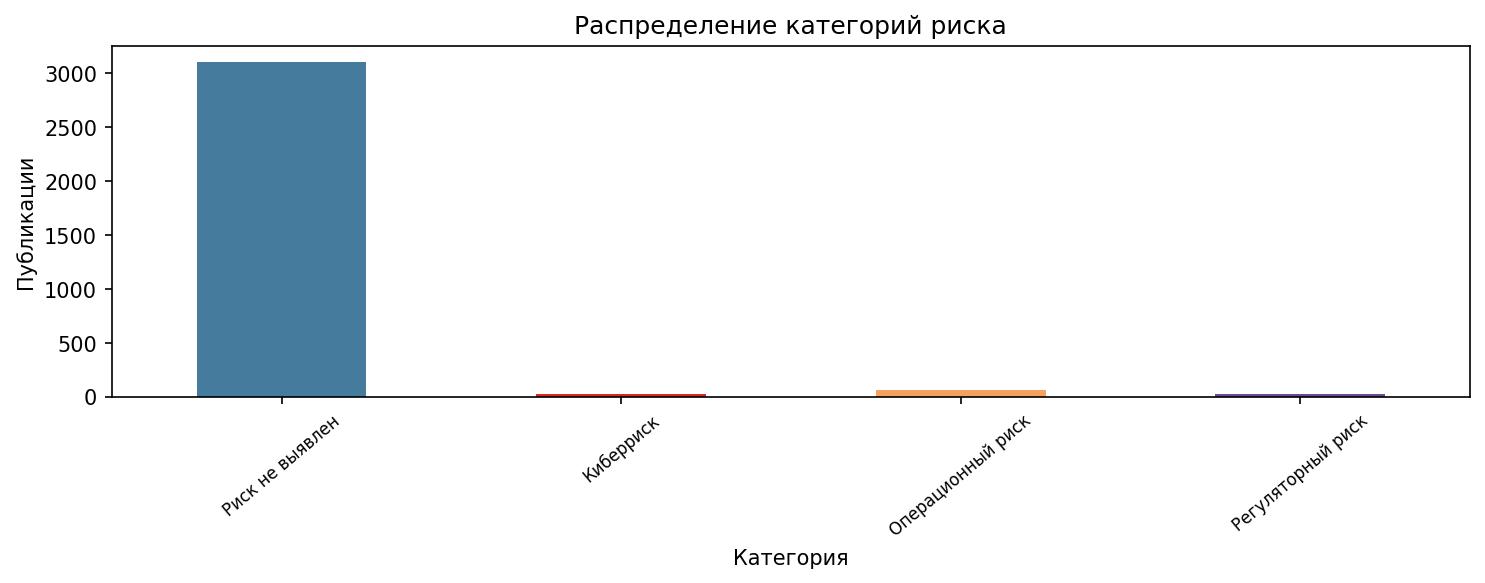

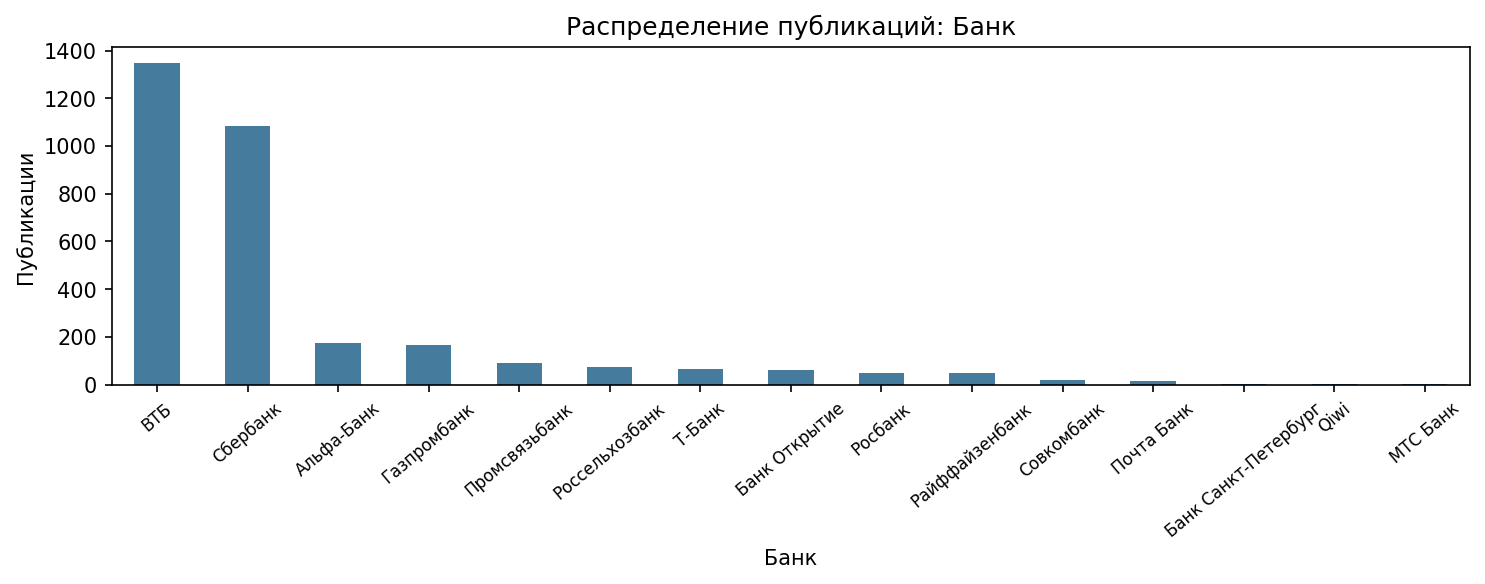

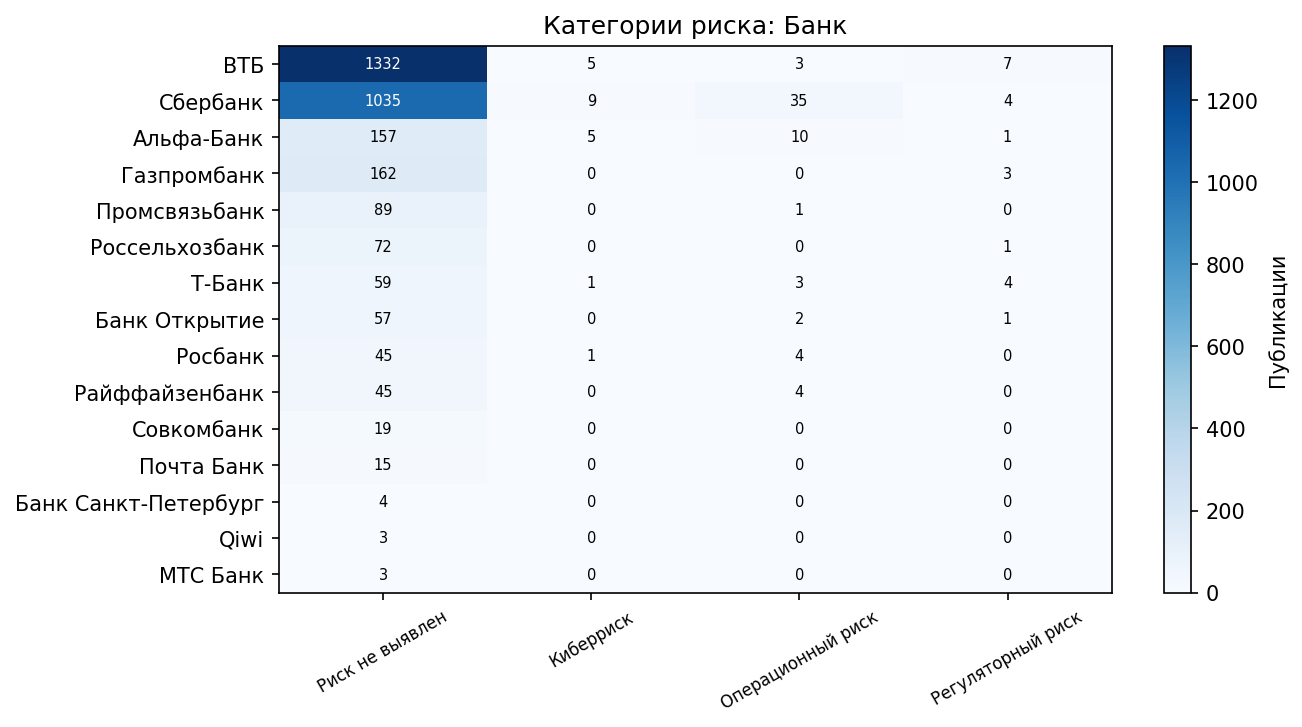

Категория «Риск не выявлен» составляет 96.8% корпуса. Дисбаланс требует отдельного анализа полноты и показателей редких категорий; число публикаций не равно числу независимых событий.

In [13]:
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown
EDA_DIR = OUTPUT_ROOT/'bank-risk-eda'
if not (EDA_DIR/'eda_registry.json').exists():
    EDA_SUMMARY = eda(DATA, EDA_DIR)
else:
    EDA_SUMMARY = read_json(EDA_DIR/'eda_registry.json')

def show_eda(*names):
    for name in names:
        img = EDA_DIR/'plots'/f'{name}.png'
        if img.exists():display(Image(filename=str(img)))

def show_eda_note(name):
    note = read_json(EDA_DIR/'notes.json').get(name,'')
    if note:display(Markdown(note))

show_eda('classes','banks','banks_risk')
show_eda_note('classes')


### 3.1. Временное покрытие и источники


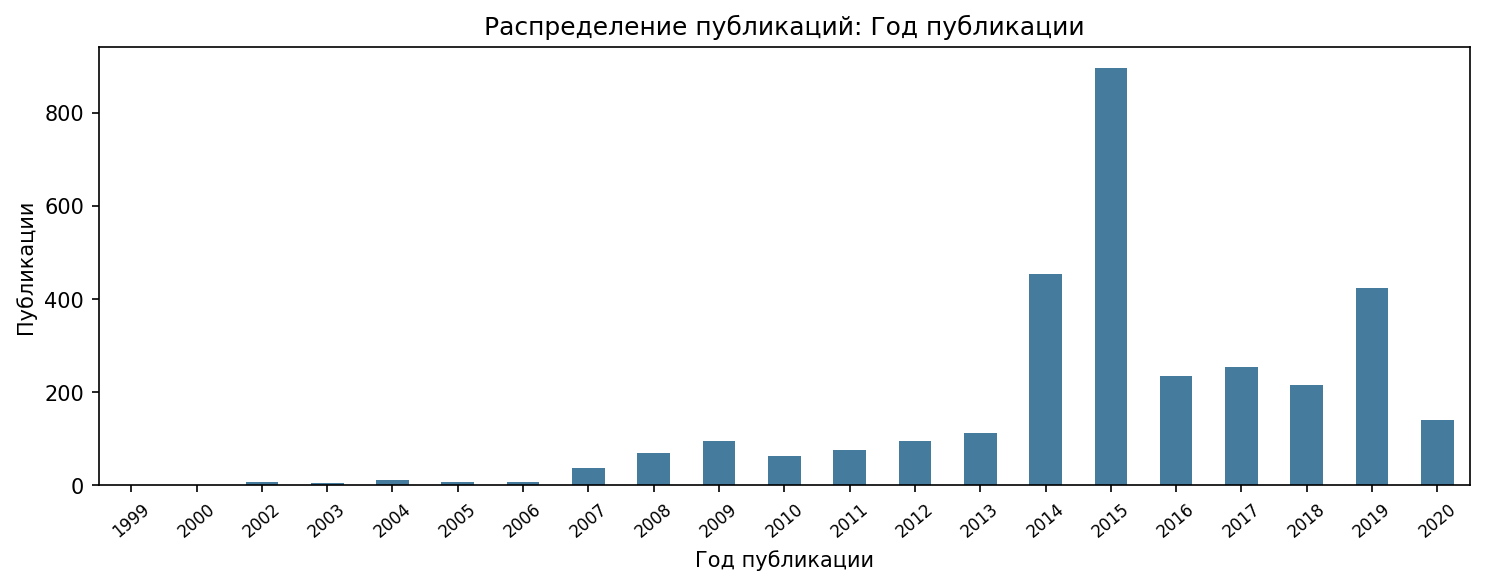

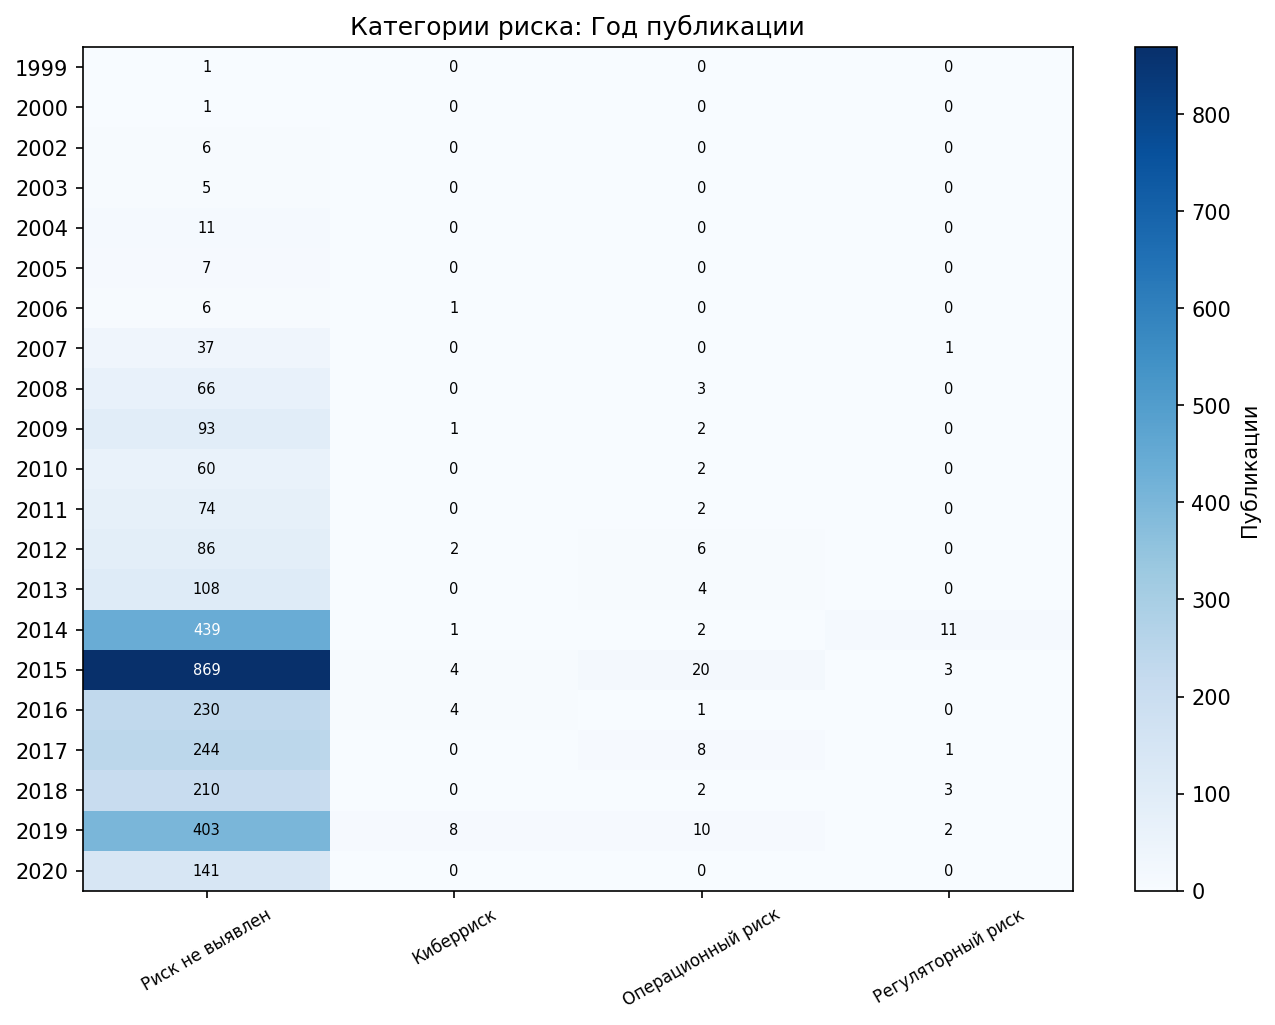

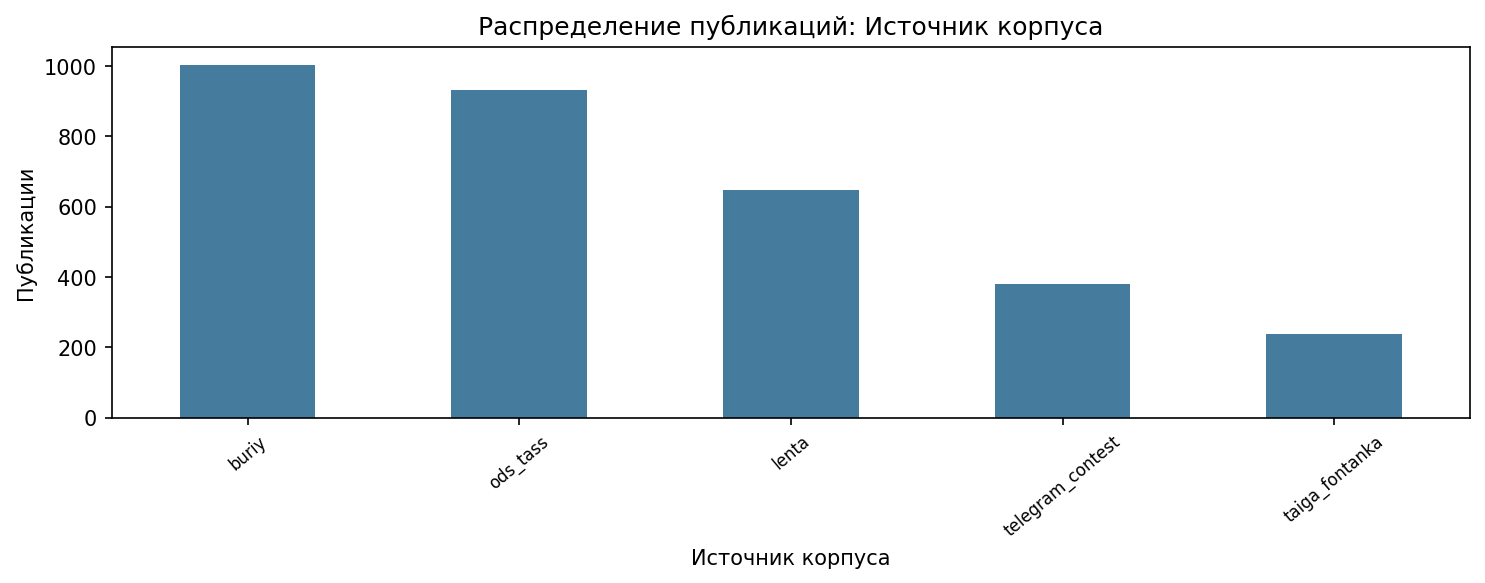

Временное покрытие неоднородно. Изменение числа публикаций не интерпретируется как изменение частоты банковских происшествий; год публикации может отличаться от года события.

In [14]:
show_eda('years','years_risk','sources')
show_eda_note('years')


### 3.2. Длины текстов, слова и биграммы


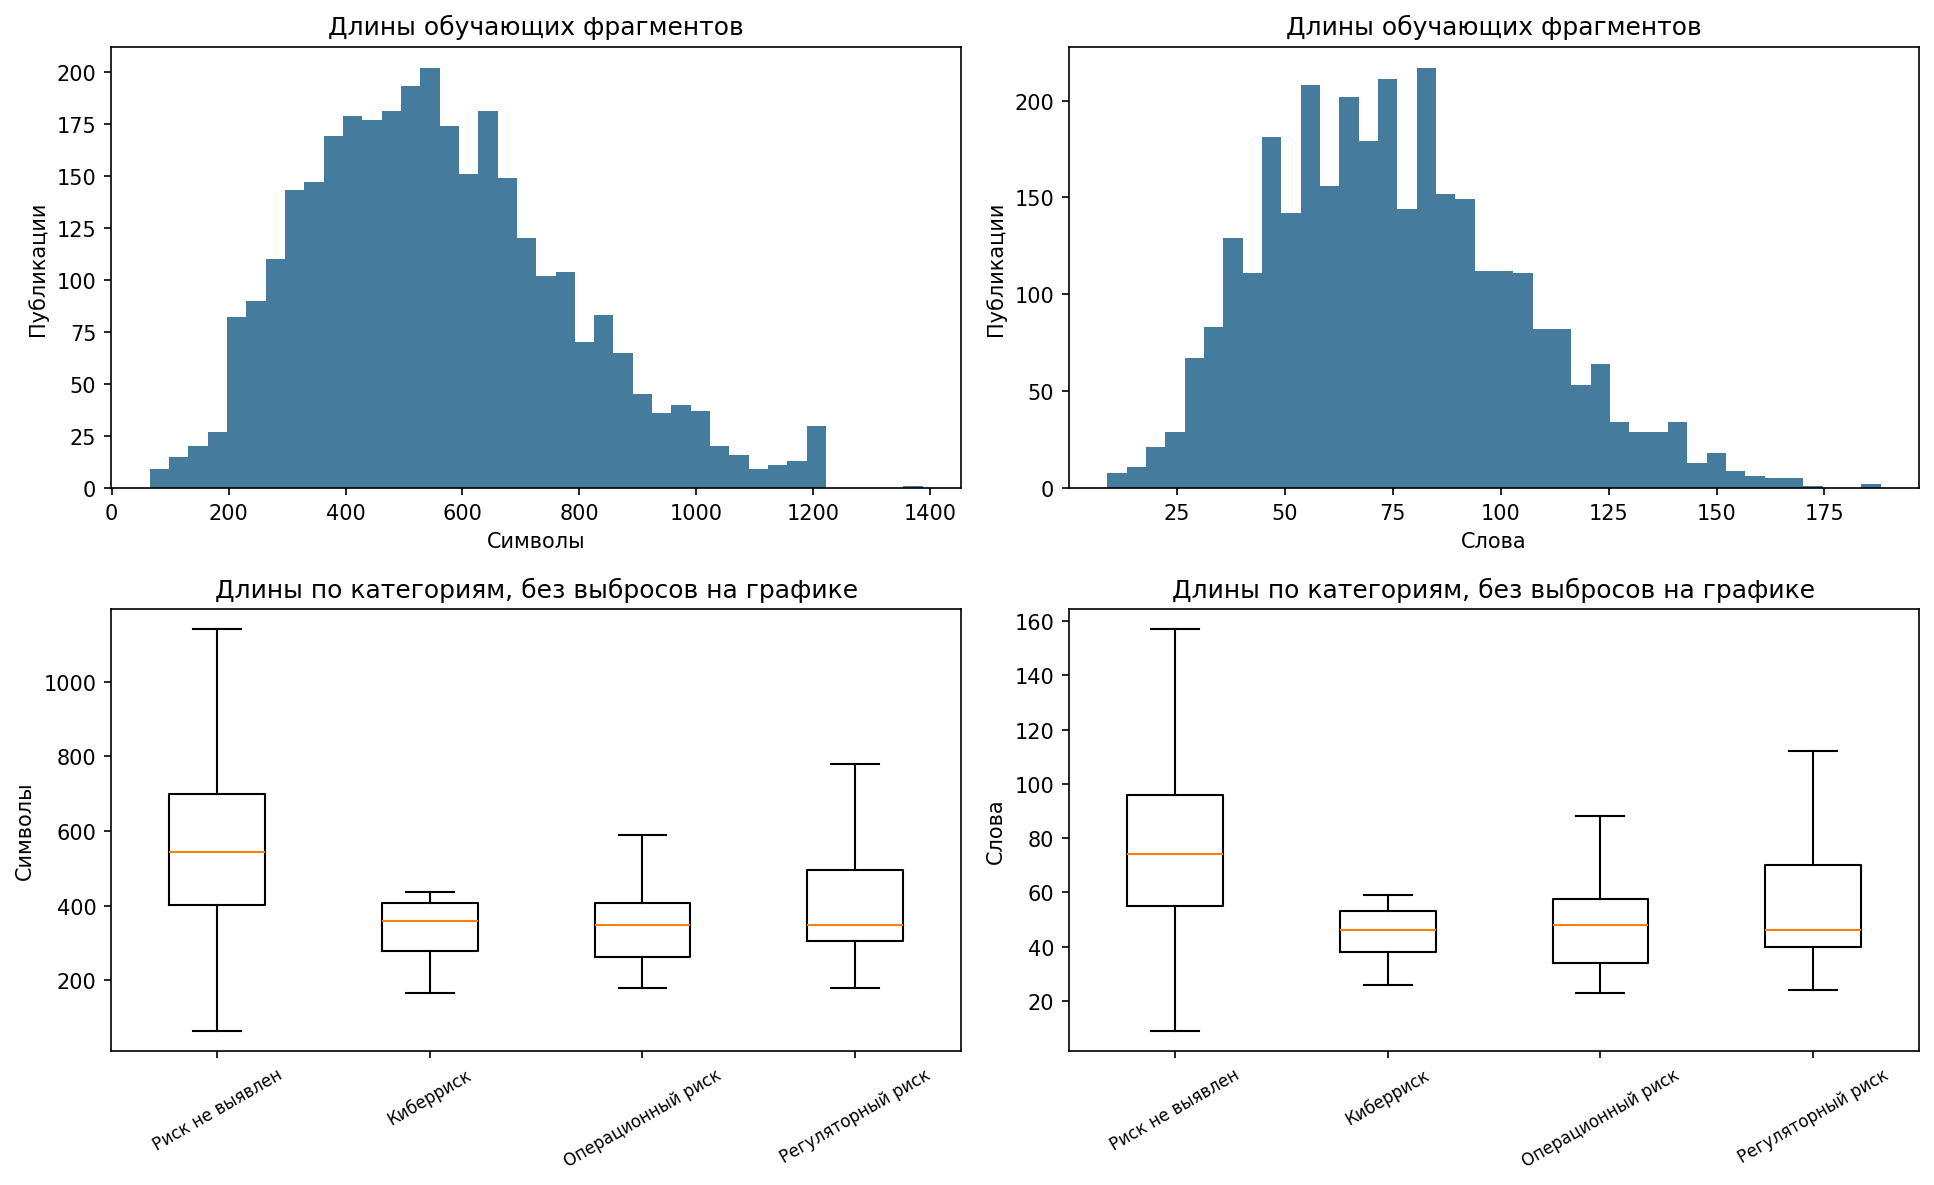

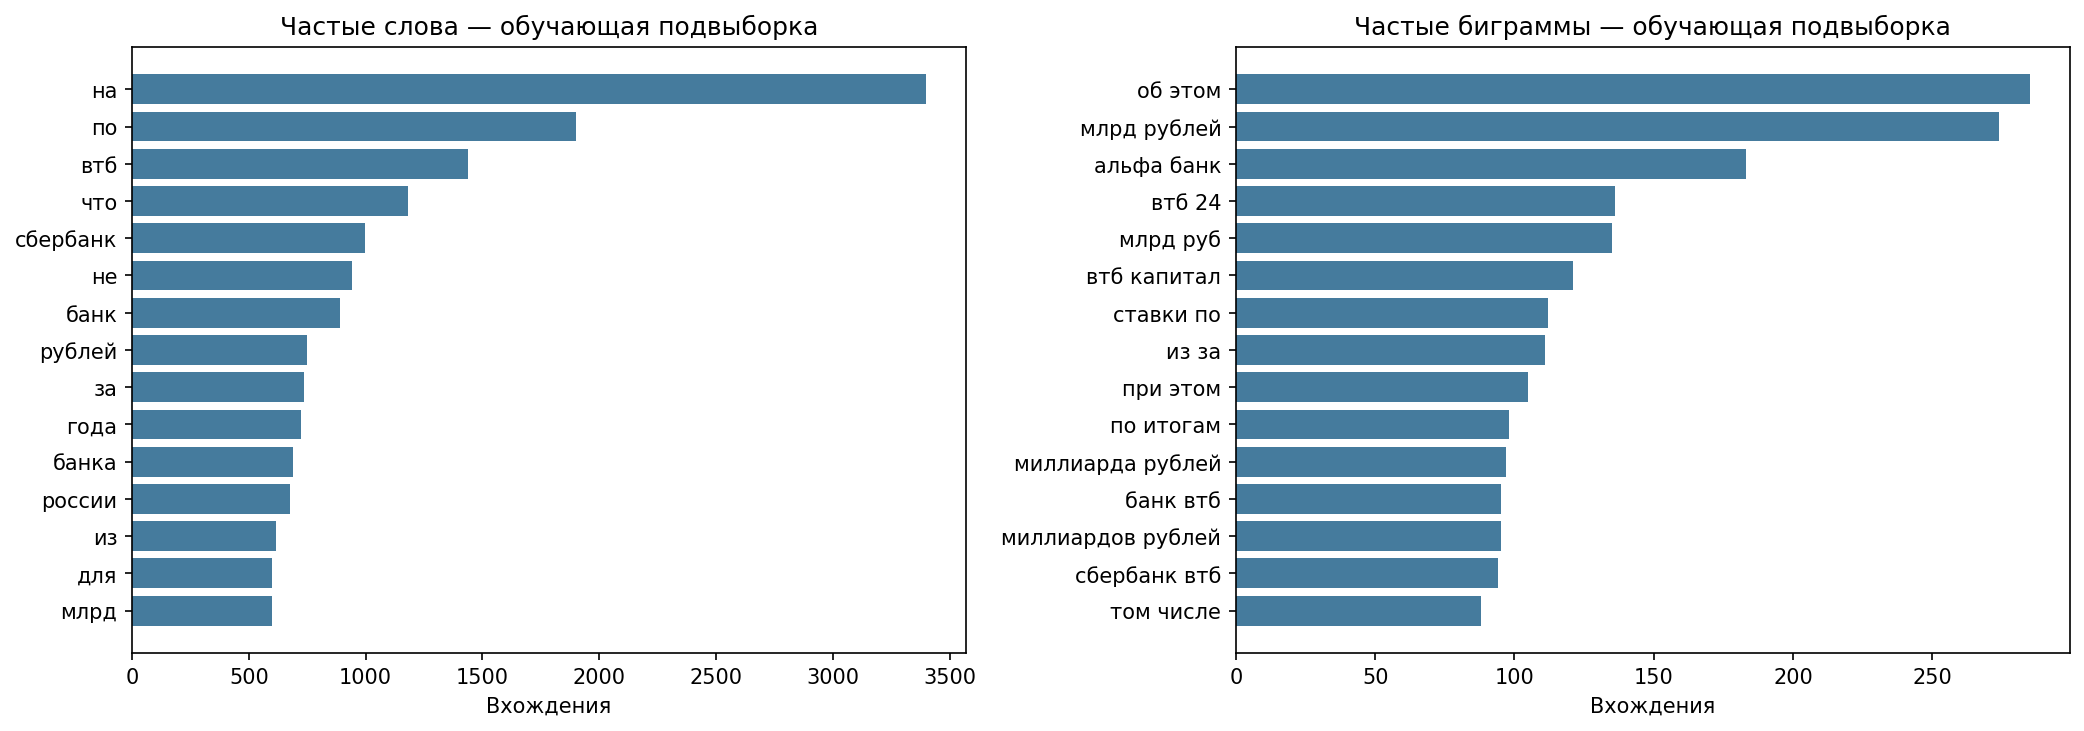

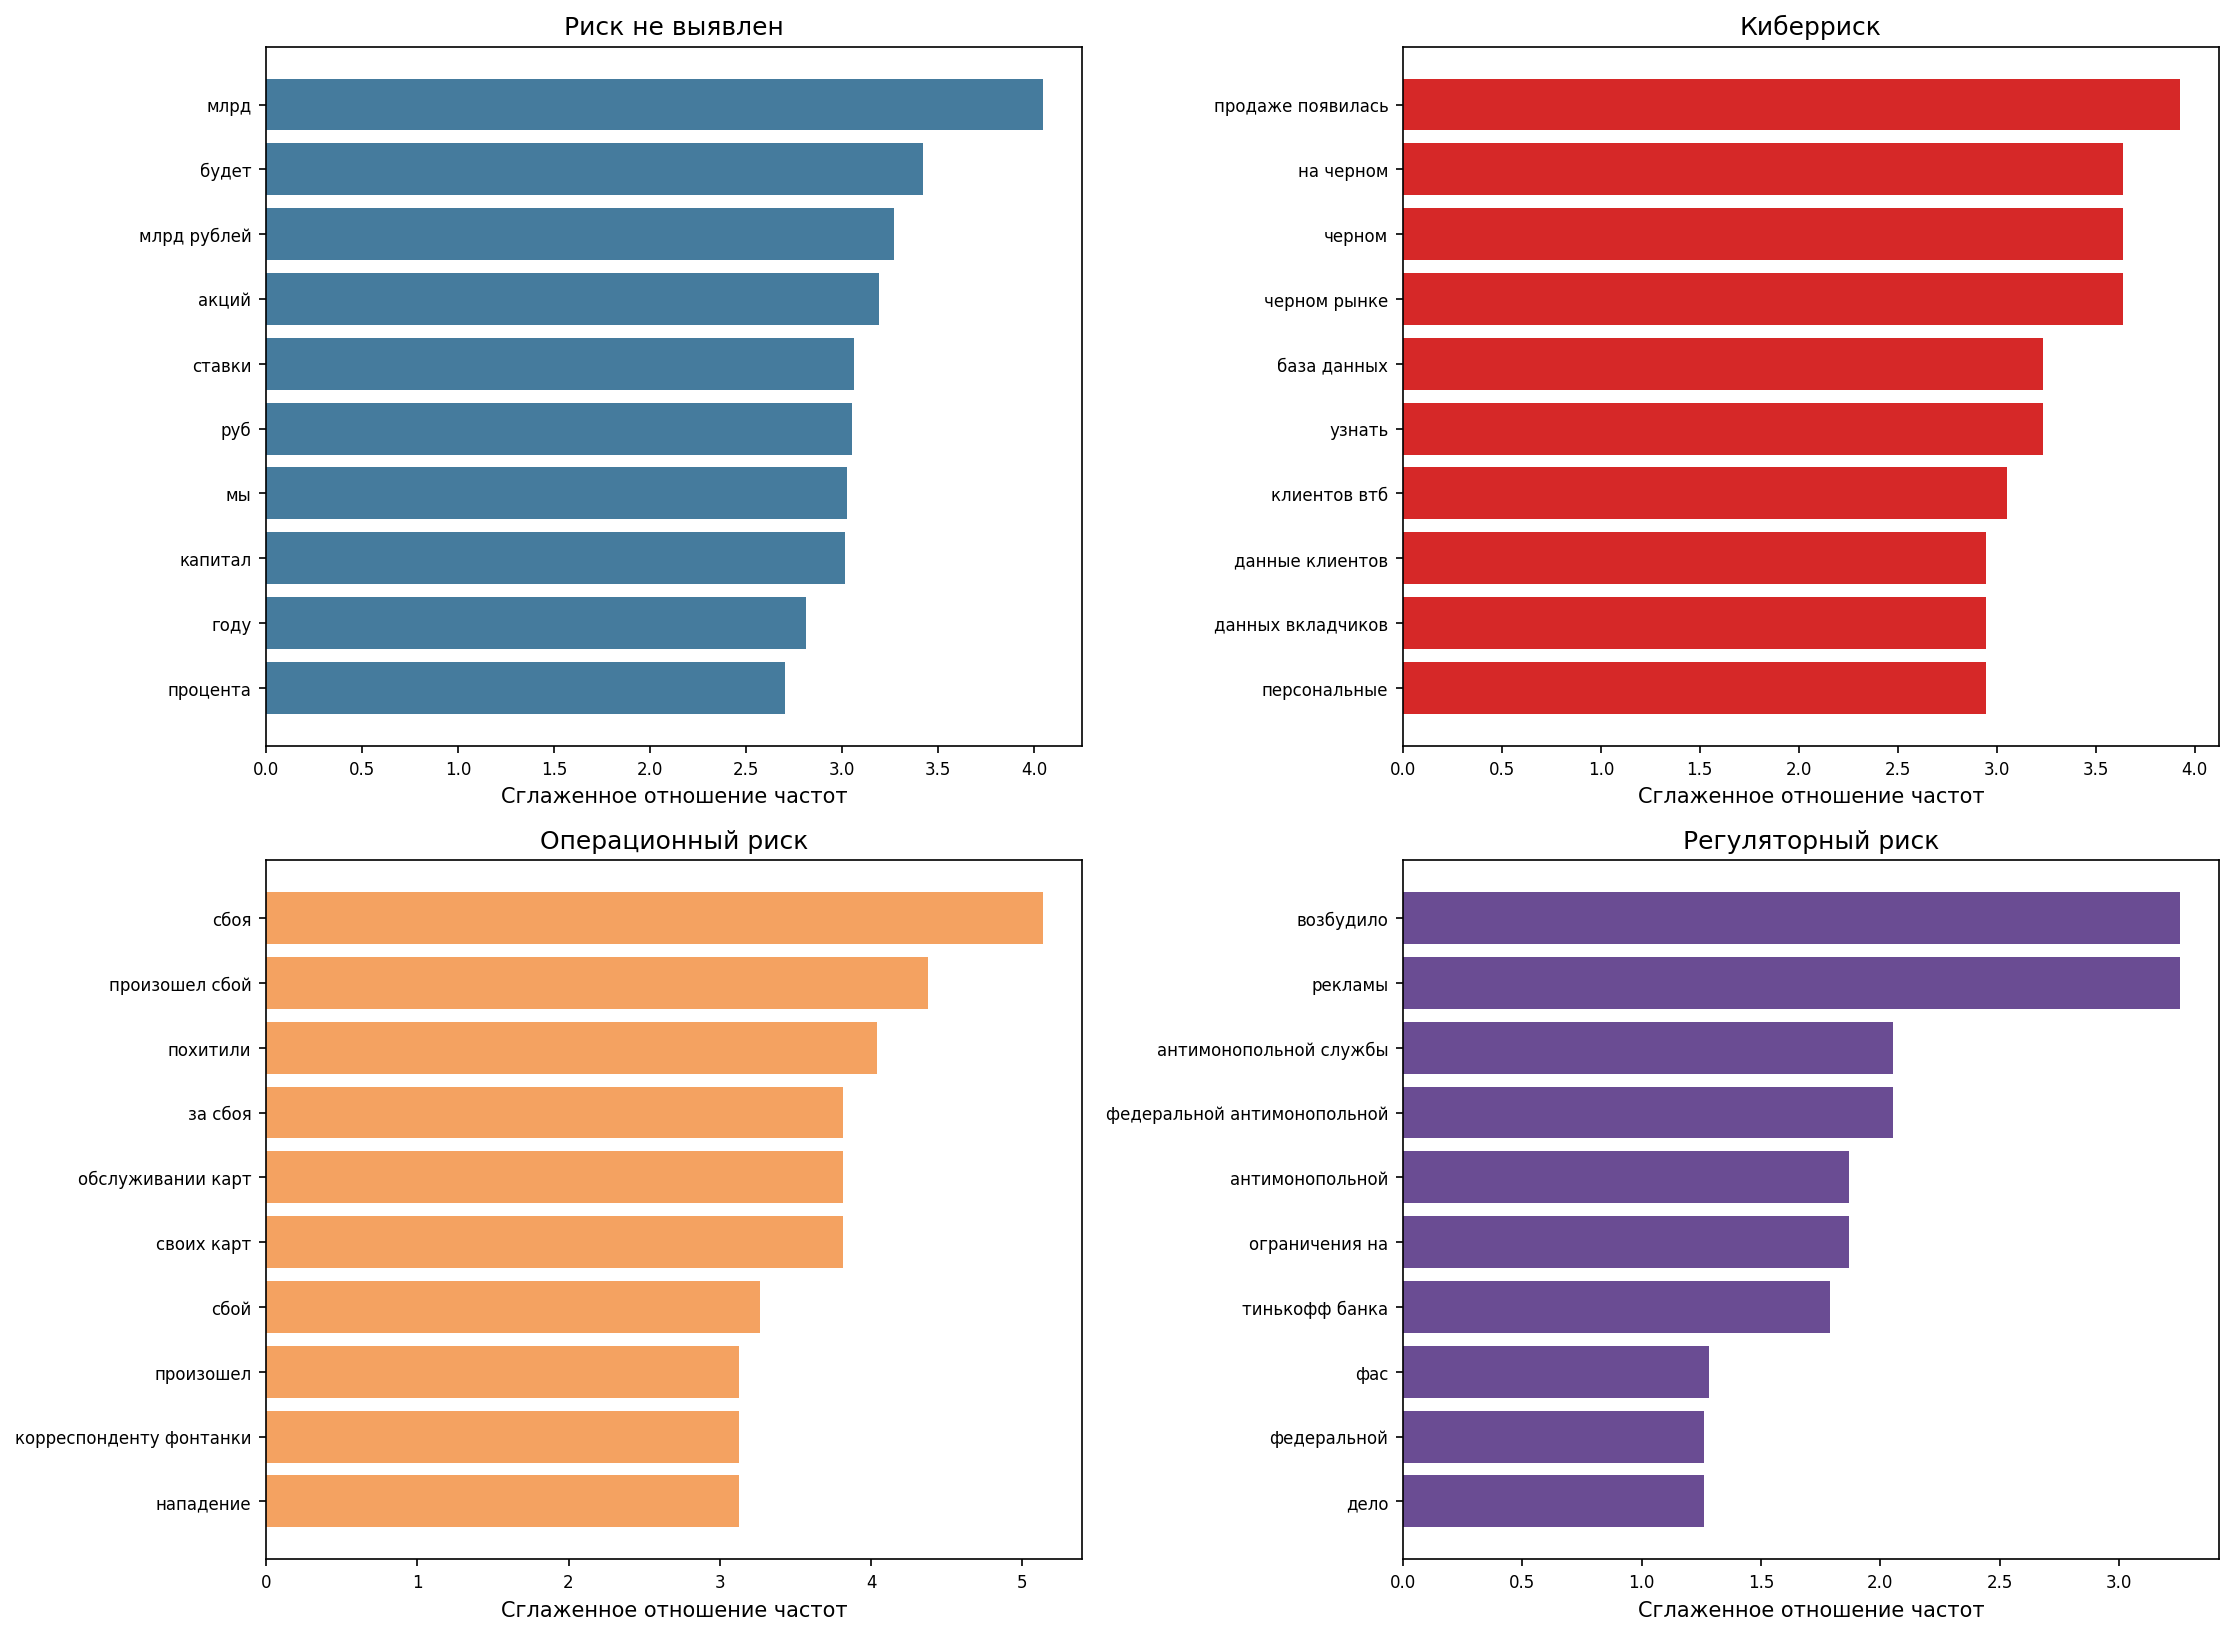

Длины рассчитаны только по обучающим текстам. Ограничение 256 токенов может сокращать вход; число слов служит ориентиром и не является точным числом токенов.

Все частоты и словари рассчитаны только по fit. Характерные выражения описывают лексические ассоциации корпуса и не устанавливают причины риска. При семи примерах категории «Регуляторный риск» такие ассоциации могут быть нестабильны.

In [15]:
show_eda('text_lengths','frequent_ngrams','characteristic_ngrams')
show_eda_note('lengths')
show_eda_note('ngrams')


### 3.3. Повторяющиеся публикации и группы событий

Связанные публикации должны попадать в одну и ту же часть данных: случайное распределение текстов одного события между train и valid завысило бы оценку качества.


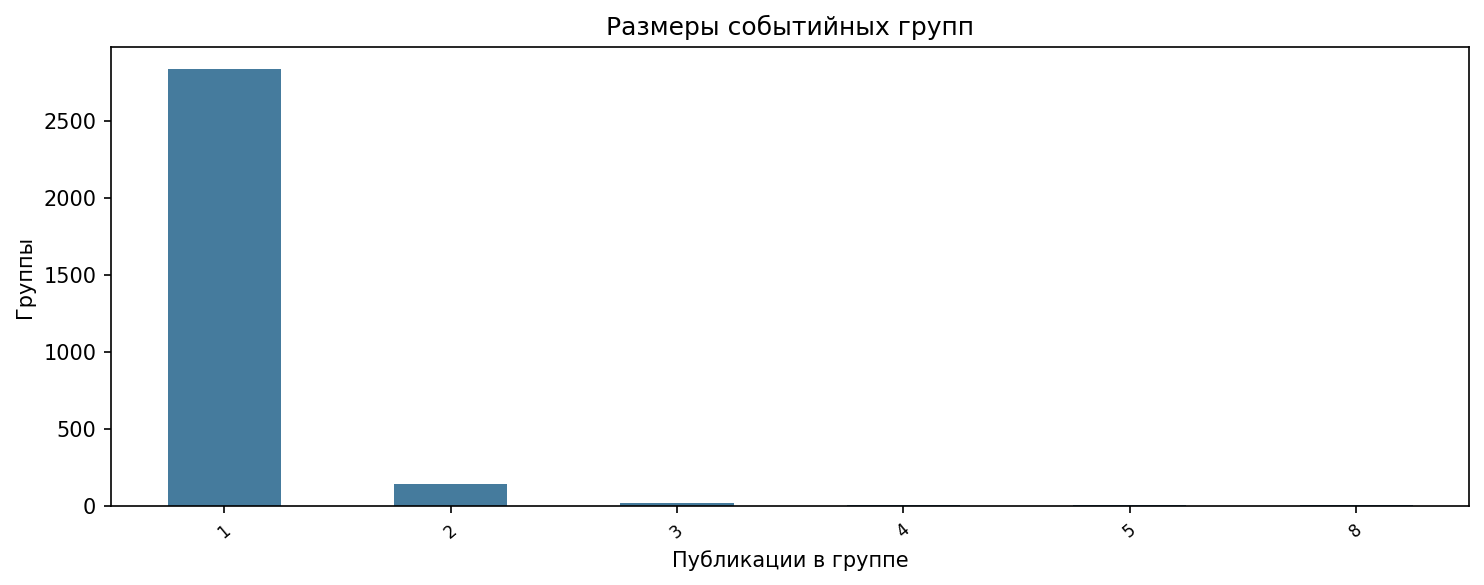

Групп: 3000; одиночных: 94.6%; максимальный размер: 8. Повторы учитываются существующей защищённой группировкой, новый поиск близких текстов не проводится.

In [16]:
show_eda('group_sizes')
show_eda_note('groups')


## 4. Экспериментальный протокол

Обучение использует три непересекающиеся части train: **основную** (fit, 1 901 запись), **контрольную** (stop, 658) и **калибровочную** (calibration, 642). Первая нужна для обучения, вторая — для выбора конфигураций и контрольных точек, третья — для выбора бинарного порога. **Valid** предназначена для внешней оценки после фиксации решений. **Test** удерживается закрытым до завершения всех решений по модели и используется один раз для финальной независимой оценки.

Для классических моделей применяется групповая кросс-валидация, предотвращающая разделение новостей одного события между обучением и проверкой. Сравниваются базовые модели, TF-IDF с логистической регрессией и LinearSVC, а также mDeBERTa. Все конфигурации запускаются по заранее заданному плану.

**Ограничение:** крайне редкие классы, особенно регуляторный риск, делают выводы неустойчивыми. Поэтому дополнительно рассчитываются доверительные интервалы, срезы метрик и анализ отдельных ошибок.


## 5. Классические модели и нейросетевое обучение

В следующем блоке расположен **непосредственно видимый Python-код обучения**: TF-IDF, подбор параметров Logistic Regression / LinearSVC, создание токенизированного датасета, функция потерь и Trainer для mDeBERTa. Никаких скрытых исполняемых файлов нет.


In [17]:
"""Kaggle-only real training; the separate CPU smoke test uses random synthetic weights."""
import gc
import importlib.metadata
import inspect
import os
import platform
import shutil
import time
from pathlib import Path

os.environ.setdefault('USE_TF','0')
os.environ.setdefault('USE_FLAX','0')
os.environ.setdefault('TOKENIZERS_PARALLELISM','false')
import joblib
import numpy as np
import pandas as pd
import torch
from scipy.special import softmax
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from torch.utils.data import Dataset,WeightedRandomSampler
from transformers import (AutoModelForSequenceClassification,AutoTokenizer,Trainer,
                          TrainingArguments,EarlyStoppingCallback,set_seed)





MODEL_ID='microsoft/mdeberta-v3-base'
MODEL_REVISION='a0484667b22365f84929a935b5e50a51f71f159d'
_PRETRAINED_HASHES={}
HP={'model_id':MODEL_ID,'revision':MODEL_REVISION,'epochs':6,'learning_rate':2e-5,
    'weight_decay':.01,'warmup_ratio':.1,'max_length':256,'train_batch_size':4,
    'eval_batch_size':8,'gradient_accumulation_steps':8,'patience':2,
    'loss_normalization':'sum(w_y * CE) / examples_in_accumulated_batch',
    'class_weight_formula':'N_fit / (K * count_fit_class)',
    'oversampling':'replacement, N_fit draws per epoch, inverse class frequency; fit only',
    'tfidf':{'ngram_range':[1,2],'min_df':2,'max_df':.99,'max_features':60000,'sublinear_tf':True},
    'C_grid':[.1,1.,3.],'class_weight_grid':[None,'balanced']}

def environment(require_pins=True):
    versions={name:importlib.metadata.version(name) for name in PINNED}
    mismatch={n:{'expected':v,'actual':versions[n]} for n,v in PINNED.items() if versions[n]!=v}
    if require_pins and mismatch:raise RuntimeError('Pinned dependencies differ; install BEFORE imports and restart kernel: '+str(mismatch))
    if 'eval_strategy' not in inspect.signature(TrainingArguments).parameters or 'processing_class' not in inspect.signature(Trainer).parameters:
        raise RuntimeError('Unsupported Transformers API')
    cuda=torch.cuda.is_available()
    return {'libraries':versions,'python':platform.python_version(),'torch':torch.__version__,
            'cuda_runtime':torch.version.cuda,'cuda':cuda,'gpu_count':torch.cuda.device_count(),
            'gpu':torch.cuda.get_device_name(0) if cuda else None,
            'precision':'bf16' if cuda and torch.cuda.is_bf16_supported() else ('fp16' if cuda else 'fp32'),
            'pin_mismatches':mismatch,'trainer_api':'eval_strategy + processing_class + compute_loss_func'}

def signature(run,experiment_identity):return {'run':run,'experiment_identity_sha256':digest(experiment_identity)}

def classic_texts(frame):
    # Explicit feature selection; no metadata, targets or group identifiers enter X.
    return [r.entity_norm+' [SEP] '+add_title(r.title,r.text_fragment)
            for r in frame[FEATURES].fillna('').astype(str).itertuples(index=False)]

def classic_pipeline(family,params,seed):
    tfidf=TfidfVectorizer(ngram_range=(1,2),min_df=2,max_df=.99,max_features=60000,sublinear_tf=True,dtype=np.float32)
    if family=='Dummy':clf=DummyClassifier(strategy='prior',random_state=seed)
    elif family=='LogisticRegression':clf=LogisticRegression(max_iter=2000,random_state=seed,**params)
    elif family=='LinearSVC':clf=LinearSVC(max_iter=8000,random_state=seed,**params)
    else:raise ValueError(family)
    return Pipeline([('tfidf',tfidf),('classifier',clf)])

def classic_scores(model,frame,task):
    x=classic_texts(frame)
    scores=(model.decision_function(x) if hasattr(model,'decision_function') else model.predict_proba(x))
    scores=np.asarray(scores)
    return scores[:,1] if task=='binary' and scores.ndim==2 else scores

def score_frame(frame,task,scores,threshold=None):
    scores=np.asarray(scores);y=labels_of(frame,task)
    if not np.isfinite(scores).all() or len(scores)!=len(y):raise ValueError('Nonfinite scores or inference length mismatch')
    if task=='binary' and (scores.ndim!=1 or threshold is None):raise ValueError('Binary scores require one dimension and a frozen threshold')
    if task=='multiclass' and scores.shape!=(len(y),4):raise ValueError('Multiclass scores must have all four fixed classes')
    pred=(scores>=threshold).astype(int) if task=='binary' else scores.argmax(1)
    result=frame[['sample_id','leakage_group_id','entity_norm','source','published_year']].copy()
    result['y_true']=y;result['y_pred']=pred
    if task=='binary':result['score']=scores
    else:
        for j,label in enumerate(LABELS):result['score_'+label]=scores[:,j]
    return result


In [18]:
def fit_classic(run,access,folder):
    assert_kaggle_training();start=time.monotonic();fit=access.roles['fit'];task=run['task']
    y=labels_of(fit,task);cv=[];fold_rows=[]
    choices=[{}] if run['family']=='Dummy' else [{'C':c,'class_weight':w} for c in HP['C_grid'] for w in HP['class_weight_grid']]
    best=choices[0]
    folds,fold_plan=choose_folds(fit,task,seed=42)
    for fold,(tr,va) in enumerate(folds):
        for side,ix in [('train',tr),('validation',va)]:
            fold_rows.extend({'sample_id':fit.iloc[j].sample_id,'leakage_group_id':fit.iloc[j].leakage_group_id,'fold':fold,'side':side} for j in ix)
    ranked=[]
    for order,params in enumerate(choices):
        values=[]
        for fold,(tr,va) in enumerate(folds):
            model=classic_pipeline(run['family'],params,run['seed']);model.fit(classic_texts(fit.iloc[tr]),y[tr])
            scores=classic_scores(model,fit.iloc[va],task)
            pred=(scores>=0).astype(int) if task=='binary' else scores.argmax(1)
            result=metrics(y[va],pred,task,scores if task=='binary' else None)
            value=result['ap' if task=='binary' else 'macro_f1'];values.append(value)
            cv.append({'parameter_order':order,'parameters':str(params),'fold':fold,'metric':value,'selection_metric':'ap' if task=='binary' else 'macro_f1'})
        ranked.append((float(np.mean(values)),-order,params))
    best=max(ranked,key=lambda x:(x[0],x[1]))[2]
    save_json(folder/'cv_plan.json',fold_plan)
    save_csv(folder/'cv_results.csv',pd.DataFrame(cv,columns=['parameter_order','parameters','fold','metric','selection_metric']))
    save_csv(folder/'cv_membership.csv',pd.DataFrame(fold_rows,columns=['sample_id','leakage_group_id','fold','side']))
    model=classic_pipeline(run['family'],best,run['seed']);model.fit(classic_texts(fit),y)
    threshold=None
    if task=='binary':
        cal=access.roles['calibration'];threshold,table=choose_threshold(labels_of(cal,task),classic_scores(model,cal,task));save_csv(folder/'threshold_candidates.csv',table)
    joblib.dump(model,folder/'model.joblib',compress=3)
    for role in ['stop','calibration']:
        frame=access.roles[role];save_csv(folder/(role+'_predictions.csv'),score_frame(frame,task,classic_scores(model,frame,task),threshold))
    stop=pd.read_csv(folder/'stop_predictions.csv');stop_metrics=metrics(stop.y_true,stop.y_pred,task,stop.score if task=='binary' else None)
    save_json(folder/'training.json',{'run':run,'selected_parameters':best,'threshold':threshold,'fit_rows':len(fit),
        'fit_groups':fit.leakage_group_id.nunique(),'stop_metrics':stop_metrics,'selection':'fit group CV; binary threshold on calibration',
        'training_seconds':time.monotonic()-start,'status':'COMPLETE','checkpoint':'model.joblib'})

class TokenizedNews(Dataset):
    def __init__(self,frame,tokenizer,mode,task,role,max_length):
        a,b,audit=rendered_inputs(frame,mode)
        self.enc=tokenizer(a,text_pair=b if mode=='bank_context' else None,
            truncation='only_second' if mode=='bank_context' else True,max_length=max_length,padding=False)
        self.y=labels_of(frame,task);self.role=role;self.audit=audit
    def __len__(self):return len(self.y)
    def __getitem__(self,i):return {**{k:v[i] for k,v in self.enc.items()},'labels':int(self.y[i])}

def normalized_ce(weights=None):
    """Trainer 4.57.6: sum across microbatches equals the fixed-denominator batch objective."""
    def loss(outputs,labels,num_items_in_batch=None):
        logits=outputs.logits.float();w=None if weights is None else torch.as_tensor(weights,dtype=logits.dtype,device=logits.device)
        denominator=labels.numel() if num_items_in_batch is None else num_items_in_batch
        return torch.nn.functional.cross_entropy(logits,labels,weight=w,reduction='sum')/denominator
    return loss

class FitSamplerTrainer(Trainer):
    def __init__(self,*args,oversample=False,**kwargs):self.oversample=oversample;super().__init__(*args,**kwargs)
    def _get_train_sampler(self,train_dataset=None):
        ds=self.train_dataset if train_dataset is None else train_dataset
        if not self.oversample:return super()._get_train_sampler(train_dataset)
        if getattr(ds,'role',None)!='fit':raise PermissionError('Oversampling only on frozen fit')
        counts=np.bincount(ds.y);weights=1/counts[ds.y]
        return WeightedRandomSampler(torch.as_tensor(weights,dtype=torch.double),len(ds),replacement=True,
                                     generator=torch.Generator().manual_seed(self.args.data_seed))

def hf_metrics(task):
    def compute(e):
        logits=e.predictions[0] if isinstance(e.predictions,tuple) else e.predictions
        p=softmax(logits,axis=1);result=metrics(e.label_ids,p.argmax(1),task,p[:,1] if task=='binary' else None)
        return {k:result[k] for k in ['ap','f1']} if task=='binary' else {'macro_f1':result['macro_f1']}
    return compute

def training_args(folder,seed,task,env,synthetic=False):
    return TrainingArguments(output_dir=str(folder),num_train_epochs=2 if synthetic else HP['epochs'],
        learning_rate=1e-3 if synthetic else HP['learning_rate'],weight_decay=HP['weight_decay'],warmup_ratio=HP['warmup_ratio'],
        per_device_train_batch_size=2 if synthetic else HP['train_batch_size'],
        per_device_eval_batch_size=4 if synthetic else HP['eval_batch_size'],
        gradient_accumulation_steps=2 if synthetic else HP['gradient_accumulation_steps'],
        eval_strategy='epoch',save_strategy='epoch',logging_strategy='epoch',save_total_limit=1,
        load_best_model_at_end=True,metric_for_best_model='ap' if task=='binary' else 'macro_f1',greater_is_better=True,
        seed=seed,data_seed=seed,full_determinism=True,dataloader_num_workers=0,report_to=[],
        fp16=env['precision']=='fp16',bf16=env['precision']=='bf16',use_cpu=synthetic,
        gradient_checkpointing=not synthetic,gradient_checkpointing_kwargs={'use_reentrant':False},
        save_only_model=True,disable_tqdm=True,optim='adamw_torch',dataloader_pin_memory=not synthetic)


In [19]:
def fit_neural(run,access,folder,env):
    assert_kaggle_training()
    if not torch.cuda.is_available() or torch.cuda.device_count()!=1:raise RuntimeError('Use one visible Kaggle GPU; fixed effective batch is 4 x 8 = 32')
    if tuple(map(int,torch.__version__.split('+')[0].split('.')[:2]))<(2,6):raise RuntimeError('Pinned checkpoint requires torch >= 2.6')
    from transformers import DataCollatorWithPadding
    start=time.monotonic();set_seed(run['seed']);task=run['task'];k=2 if task=='binary' else 4
    tokenizer=AutoTokenizer.from_pretrained(MODEL_ID,revision=MODEL_REVISION)
    datasets={role:TokenizedNews(frame,tokenizer,run['mode'],task,role,HP['max_length']) for role,frame in access.roles.items()}
    model=AutoModelForSequenceClassification.from_pretrained(MODEL_ID,revision=MODEL_REVISION,num_labels=k,use_safetensors=False,
        id2label=dict(enumerate(['no_risk','risk'] if k==2 else LABELS)),label2id={c:i for i,c in enumerate(['no_risk','risk'] if k==2 else LABELS)})
    if model.config._commit_hash!=MODEL_REVISION:raise ValueError('Pretrained commit differs from the frozen revision')
    from huggingface_hub import hf_hub_download
    initial_file=Path(hf_hub_download(MODEL_ID,'pytorch_model.bin',revision=MODEL_REVISION,local_files_only=True)).resolve()
    if str(initial_file) not in _PRETRAINED_HASHES:_PRETRAINED_HASHES[str(initial_file)]=file_sha(initial_file)
    initial_sha=_PRETRAINED_HASHES[str(initial_file)]
    weights=class_weights(datasets['fit'].y,k) if run['balance']=='weighted_loss' else None
    args=training_args(folder/'checkpoints',run['seed'],task,env)
    trainer=FitSamplerTrainer(model=model,args=args,train_dataset=datasets['fit'],eval_dataset=datasets['stop'],
        processing_class=tokenizer,data_collator=DataCollatorWithPadding(tokenizer),compute_metrics=hf_metrics(task),
        compute_loss_func=normalized_ce(weights),oversample=run['balance']=='oversampling',
        callbacks=[EarlyStoppingCallback(early_stopping_patience=HP['patience'])])
    training=trainer.train();best=trainer.state.best_model_checkpoint
    trainer.save_model(str(folder/'model'));tokenizer.save_pretrained(folder/'model')
    threshold=None
    scores_by_role={}
    for role in ['stop','calibration']:
        scores=softmax(trainer.predict(datasets[role]).predictions,axis=1)
        scores_by_role[role]=scores[:,1] if task=='binary' else scores
    if task=='binary':
        threshold,table=choose_threshold(datasets['calibration'].y,scores_by_role['calibration']);save_csv(folder/'threshold_candidates.csv',table)
    for role in ['stop','calibration']:
        save_csv(folder/(role+'_predictions.csv'),score_frame(access.roles[role],task,scores_by_role[role],threshold))
        save_csv(folder/(role+'_text_audit.csv'),pd.concat([access.roles[role][['sample_id']],datasets[role].audit],axis=1))
    stop=pd.read_csv(folder/'stop_predictions.csv');stop_metrics=metrics(stop.y_true,stop.y_pred,task,stop.score if task=='binary' else None)
    save_json(folder/'trainer_log.json',trainer.state.log_history)
    save_json(folder/'training.json',{'run':run,'parameters':HP,'threshold':threshold,'class_weights':weights,
        'fit_counts':np.bincount(datasets['fit'].y,minlength=k),'fit_groups':access.roles['fit'].leakage_group_id.nunique(),
        'best_checkpoint':Path(best).name if best else None,'best_stop_objective':trainer.state.best_metric,
        'stop_metrics':stop_metrics,'training_metrics':training.metrics,'epochs_completed':trainer.state.epoch,
        'training_seconds':time.monotonic()-start,'status':'COMPLETE','checkpoint':'model','environment':env,
        'model_config':model.config.to_dict(),'initial_pretrained_file_sha256':initial_sha,
        'tokenizer':{'name':MODEL_ID,'revision':MODEL_REVISION,'max_length':HP['max_length']},
        'effective_batch_size':HP['train_batch_size']*HP['gradient_accumulation_steps']})
    del trainer,model,datasets;gc.collect();torch.cuda.empty_cache()
    # Only disposable checkpoints created in THIS run; final selected weights remain checksummed.
    checkpoint=(folder/'checkpoints').resolve()
    if not checkpoint.is_relative_to(folder.resolve()):raise ValueError('Unsafe checkpoint path')
    if checkpoint.exists():shutil.rmtree(checkpoint)

def execute_training(plan,access,store,env,max_new_dl=3,retry_failed=False):
    assert_kaggle_training();new_dl=0;rows=[]
    for run in plan:
        sig=signature(run,store.identity);unit='runs/'+run['name'];folder=store.complete(unit,sig)
        if folder is None:
            if run['family']=='mDeBERTa' and new_dl>=max_new_dl:rows.append({'name':run['name'],'status':'PENDING_SESSION_BUDGET'});continue
            partials=[str(root/unit) for root in [store.root,*store.sources]
                      if (root/unit/'run_identity.json').exists() and not (root/unit/'complete.json').exists()]
            if partials and not retry_failed:
                raise RuntimeError('Interrupted/failed training requires RETRY_FAILED=True to restart from the original initialization: '+str(partials))
            folder=store.begin(unit,sig,retry=retry_failed)
            attempt_file=folder/'attempts.json'
            attempts=read_json(attempt_file) if attempt_file.exists() else []
            attempts.append({'start_unix':time.time(),'restart_partial_sources':partials,'same_seed_and_configuration':True,
                             'checkpoint_resume':False,'restart_from_pinned_initial_weights':True})
            save_json(attempt_file,attempts)
            if run['family']=='mDeBERTa':new_dl+=1
            try:
                if run['family']=='mDeBERTa':fit_neural(run,access,folder,env)
                else:fit_classic(run,access,folder)
                attempts[-1]['status']='COMPLETE';save_json(attempt_file,attempts);store.seal(folder,sig)
            except Exception as exc:
                attempts[-1]['status']='FAILED';save_json(attempt_file,attempts)
                save_json(folder/'failed.json',{'status':'FAILED','exception':type(exc).__name__,'message':str(exc),
                    'no_automatic_batch_change':True,'retry_protocol':'explicit retry from original initialization, same seed and parameters'})
                raise
        rows.append({'name':run['name'],'status':'COMPLETE','artifact':str(folder)})
    result=pd.DataFrame(rows);save_csv(store.root/'session_training_status.csv',result);return result


In [20]:
def synthetic_trainer_smoke(root):
    """Real Trainer API, tiny randomly initialized DeBERTa; no Hub call and no bank news."""
    from tokenizers import Tokenizer,models,pre_tokenizers
    from transformers import DebertaV2Config,DebertaV2ForSequenceClassification,PreTrainedTokenizerFast,DataCollatorWithPadding
    root=Path(root);root.mkdir(parents=True,exist_ok=True);reports=[]
    vocab={'[PAD]':0,'[UNK]':1,'[CLS]':2,'[SEP]':3,'news':4,'safe':5,'incident':6,'bank':7}
    backend=Tokenizer(models.WordLevel(vocab,unk_token='[UNK]'));backend.pre_tokenizer=pre_tokenizers.Whitespace()
    tok=PreTrainedTokenizerFast(tokenizer_object=backend,pad_token='[PAD]',unk_token='[UNK]',cls_token='[CLS]',sep_token='[SEP]')
    for task,balance in [('binary','baseline'),('multiclass','weighted_loss'),('multiclass','oversampling')]:
        set_seed(42);labels=(LABELS*2 if task=='multiclass' else ['no_risk','cyber_risk']*4)
        f=pd.DataFrame({'text_fragment':['news bank safe incident']*8,'title':['news']*8,'entity_norm':['bank']*8,'risk_type_4cls':labels})
        # Deliberately unequal fit counts make the weighted objective test meaningful.
        if task=='multiclass':f=pd.concat([f,f.iloc[[0,0,1]]],ignore_index=True)
        ds=TokenizedNews(f,tok,'text',task,'fit',16);ev=TokenizedNews(f.iloc[:8],tok,'text',task,'stop',16)
        k=2 if task=='binary' else 4;config=DebertaV2Config(vocab_size=len(vocab),hidden_size=16,num_hidden_layers=1,num_attention_heads=2,
            intermediate_size=24,max_position_embeddings=32,type_vocab_size=0,num_labels=k,relative_attention=False)
        model=DebertaV2ForSequenceClassification(config);weights=class_weights(ds.y,k) if balance=='weighted_loss' else None
        folder=root/(task+'_'+balance);args=training_args(folder,42,task,{'precision':'fp32'},synthetic=True)
        loss_calls=[];objective=normalized_ce(weights)
        def checked_loss(outputs,labels,num_items_in_batch=None):
            actual=objective(outputs,labels,num_items_in_batch=num_items_in_batch)
            denominator=labels.numel() if num_items_in_batch is None else num_items_in_batch
            w=None if weights is None else torch.tensor(weights,dtype=torch.float32,device=outputs.logits.device)
            expected=torch.nn.functional.cross_entropy(outputs.logits.float(),labels,weight=w,reduction='sum')/denominator
            assert torch.allclose(actual,expected,atol=1e-6)
            loss_calls.append(float(actual.detach()));return actual
        trainer=FitSamplerTrainer(model=model,args=args,train_dataset=ds,eval_dataset=ev,processing_class=tok,
            data_collator=DataCollatorWithPadding(tok),compute_loss_func=checked_loss,compute_metrics=hf_metrics(task),
            oversample=balance=='oversampling',callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
        sampler=trainer._get_train_sampler()
        if balance=='oversampling':
            assert isinstance(sampler,WeightedRandomSampler) and len(list(sampler))==len(ds)
            assert not isinstance(trainer._get_eval_sampler(ev),WeightedRandomSampler)
        trainer.train();pred=trainer.predict(ev);assert pred.predictions.shape==(len(ev),k)
        assert len(loss_calls)>0
        assert trainer.state.best_model_checkpoint is not None
        trainer.save_model(str(folder/'selected'));reloaded=DebertaV2ForSequenceClassification.from_pretrained(folder/'selected',local_files_only=True)
        assert reloaded.config.num_labels==k
        reports.append({'task':task,'balance':balance,'status':'PASS','best_checkpoint_restored':True,
                        'prediction_shape':list(pred.predictions.shape),'pretrained_downloads':0,
                        'trainer_custom_loss_calls_verified':len(loss_calls),'weighted_loss_checked_in_trainer':weights is not None})
    save_json(root/'smoke_results.json',reports);return reports


## 6. Фиксация моделей и внешняя оценка

Исходные функции сопоставления конфигураций, проверки сохранённых предсказаний и статистических сравнений приводятся ниже. Сохранённые результаты можно продолжить при подключении Output прошлых сессий. Значения valid не используются для выбора параметров.


In [21]:
"""Frozen-plan evaluation on valid only, descriptive analyses and group uncertainty."""
import gc
import itertools
import math
import time
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from scipy.special import softmax




def prepare_store(output_parent,access,env,plan,code_hashes,resume_sources=()):
    identity={'notebook_version':VERSION,'data_version':DATA_VERSION,'manifest_sha256':file_sha(access.base/'dataset_manifest.json'),
        'training_contract_sha256':file_sha(access.base/'training_contract.json'),'code_hashes':code_hashes,
        'environment':env,'plan':plan,'parameters':HP,'protocol':{'test_enabled':False,'fixed_main_seed':42,
        'threshold':'max F1 on calibration, highest-threshold tie','cv':'fit only, SGKF seed42, 5 down to 2, all classes required',
        'robustness':{'seed':20261122,'noise_rate':.01,'truncate_fraction':.6,'minimum_words':16,'policies':TRANSFORMS},
        'bootstrap':{'group':'leakage_group_id','replicates':1000,'seed':20261122,'minimum_valid_fraction':.9},
        'selection':'binary mode by mean stop AP; multiclass balancing by mean stop MacroF1; no best seed selection'}}
    root=Path(output_parent)/(VERSION+'-'+digest(identity)[:12])
    return RunStore(root,identity,resume_sources)

def completed_training(plan,store):
    records=[]
    for run in plan:
        folder=store.complete('runs/'+run['name'],signature(run,store.identity))
        if folder is not None:records.append((run,folder,read_json(folder/'training.json')))
    return records

def freeze_training(plan,access,store):
    records=completed_training(plan,store);missing=[r['name'] for r in plan if r['name'] not in {x[0]['name'] for x in records}]
    durations=[r[2]['training_seconds'] for r in records if r[0]['family']=='mDeBERTa']
    save_json(store.root/'resource_plan.json',{'planned_classical':sum(r['family']!='mDeBERTa' for r in plan),
        'planned_neural':sum(r['family']=='mDeBERTa' for r in plan),'completed':len(records),'pending':missing,
        'measured_neural_seconds':durations,'remaining_neural_seconds_linear_estimate':
            np.median(durations)*sum('mDeBERTa' in x for x in missing) if durations else None,
        'estimate_limit':'linear extrapolation from completed new runs, not a guarantee; modes and early stopping differ',
        'storage_note':'~1.1GB per selected FP32 backbone plus tokenizer/checkpoints; FULL may exceed a single session/output quota',
        'preflight':'keep all output shards attached; reduce MAX_NEW_DL_RUNS scheduling only; do not change batch size under same experiment ID'})
    if missing:return None
    binary_modes={};multi_balance={}
    for run,folder,meta in records:
        if run['family']!='mDeBERTa':continue
        destination=binary_modes if run['task']=='binary' else multi_balance
        key=run['mode'] if run['task']=='binary' else run['balance']
        objective=meta.get('best_stop_objective')
        if objective is None:raise ValueError('Neural run lacks the checkpoint selection objective')
        destination.setdefault(key,[]).append(float(objective))
    def pick(values,order):
        return max((x for x in order if x in values),key=lambda x:(float(np.mean(values[x])),-order.index(x)))
    freeze={'all_training_complete':True,'dataset_manifest_sha':file_sha(access.base/'dataset_manifest.json'),
        'identity_sha256':store.identity_sha,'complete_run_hashes':{r['name']:file_sha(p/'complete.json') for r,p,m in records},
        'thresholds':{r['name']:m['threshold'] for r,p,m in records},'main_seed':42,
        'selected_binary_mode_train_only':pick(binary_modes,['text','text_without_title','bank_context']),
        'selected_multiclass_balancing_train_only':pick(multi_balance,['baseline','weighted_loss','oversampling']),
        'binary_stop_selection_values':binary_modes,'multiclass_stop_selection_values':multi_balance,
        'test_enabled':False,'valid_for_selection':False}
    for root in [store.root,*store.sources]:
        previous=root/'frozen_plan.json'
        if previous.exists() and read_json(previous)!=clean_json(freeze):raise ValueError('Conflicting frozen protocol; no new selection after valid')
    path=store.root/'frozen_plan.json'
    if not path.exists():save_json(path,freeze,exclusive=True)
    return path

def is_main(run):return run['family']!='mDeBERTa' or run['seed']==42

class Predictor:
    def __init__(self,run,folder):
        self.run=run;self.folder=Path(folder);self.tokenizer=None;self.model=None
        self.threshold=read_json(self.folder/'training.json')['threshold']
    def __enter__(self):
        if self.run['family']=='mDeBERTa':
            import torch
            from transformers import AutoTokenizer,AutoModelForSequenceClassification
            if not torch.cuda.is_available():raise RuntimeError('Real neural inference requires Kaggle GPU')
            self.tokenizer=AutoTokenizer.from_pretrained(self.folder/'model',local_files_only=True)
            self.model=AutoModelForSequenceClassification.from_pretrained(self.folder/'model',local_files_only=True).to('cuda').eval()
        else:self.model=joblib.load(self.folder/'model.joblib')
        return self
    def __exit__(self,*args):
        del self.model;gc.collect()
        if self.tokenizer is not None:
            import torch
            torch.cuda.empty_cache()
    def scores(self,frame):
        if self.run['family']!='mDeBERTa':return classic_scores(self.model,frame,self.run['task'])
        import torch
        a,b,_=rendered_inputs(frame,self.run['mode']);logits=[]
        for start in range(0,len(frame),HP['eval_batch_size']):
            end=start+HP['eval_batch_size'];inputs=self.tokenizer(a[start:end],
                text_pair=b[start:end] if self.run['mode']=='bank_context' else None,
                truncation='only_second' if self.run['mode']=='bank_context' else True,
                max_length=HP['max_length'],padding=True,return_tensors='pt').to('cuda')
            with torch.inference_mode():logits.append(self.model(**inputs).logits.float().cpu().numpy())
        p=softmax(np.concatenate(logits),axis=1);return p[:,1] if self.run['task']=='binary' else p

def prediction_signature(run,folder,frame,policy,freeze):
    return {'frozen_plan_sha256':file_sha(freeze),'training_complete_sha256':file_sha(folder/'complete.json'),
        'run':run,'policy':policy,'feature_and_id_sha256':digest(frame[['sample_id','text_fragment','title','entity_norm']].to_dict('records'))}


In [22]:
def prediction_folder(store,run,folder,frame,policy,freeze):
    unit='evaluations/'+run['name']+'/'+policy;sig=prediction_signature(run,folder,frame,policy,freeze)
    complete=store.complete(unit,sig)
    if complete is not None:return complete,sig,True
    for root in [store.root,*store.sources]:
        if (root/unit/'started.json').exists():
            raise RuntimeError('Interrupted valid inference: '+str(root/unit)+'. No automatic second pass; inspect this unit and explicitly document recovery in a new evaluation protocol.')
    return store.root/unit,sig,False

def evaluate(plan,access,store,valid,freeze,robustness=False):
    if freeze is None or valid is None:return pd.DataFrame()
    if not read_json(freeze)['all_training_complete']:raise PermissionError('Training plan not frozen')

    assert_kaggle_training()
    transformations={'clean':valid}
    if robustness:
        for policy in TRANSFORMS:
            transformations[policy],audit=perturb(valid,policy)
            save_csv(store.root/'tables'/(policy+'_input_audit.csv'),audit)
    rows=[]
    for run,folder,meta in completed_training(plan,store):
        policies=TRANSFORMS if robustness and is_main(run) else ([] if robustness else ['clean'])
        pending=[]
        for policy in policies:
            dest,sig,done=prediction_folder(store,run,folder,transformations[policy],policy,freeze)
            if done:rows.append({'name':run['name'],'policy':policy,'status':'REUSED_CHECKSUM_VERIFIED'});continue
            pending.append((policy,dest,sig))
        if not pending:continue
        with Predictor(run,folder) as predictor:
            for policy,dest,sig in pending:
                dest=store.begin('evaluations/'+run['name']+'/'+policy,sig)
                save_json(dest/'started.json',{'status':'STARTED','signature_sha256':digest(sig)},exclusive=True)
                start=time.monotonic();scores=predictor.scores(transformations[policy])
                # Analysis metadata always refer to ORIGINAL bank/year/source, even when the bank input is masked.
                predictions=score_frame(valid,run['task'],scores,predictor.threshold)
                save_csv(dest/'predictions.csv',predictions)
                result=metrics(predictions.y_true,predictions.y_pred,run['task'],predictions.score if run['task']=='binary' else None)
                save_json(dest/'metrics.json',result)
                save_json(dest/'inference.json',{'status':'COMPLETE','seconds':time.monotonic()-start,'policy':policy,
                    'threshold_unchanged':predictor.threshold,'test_accessed':False})
                store.seal(dest,sig);rows.append({'name':run['name'],'policy':policy,'status':'COMPLETE'})
    table=pd.DataFrame(rows);save_csv(store.root/'tables'/('robustness_execution.csv' if robustness else 'valid_execution.csv'),table);return table

def load_prediction(run,folder,frame,policy,freeze,store):
    dest,sig,done=prediction_folder(store,run,folder,frame,policy,freeze)
    if not done:raise RuntimeError('Missing cached prediction for '+run['name']+'/'+policy)
    return pd.read_csv(dest/'predictions.csv',keep_default_na=False,float_precision='round_trip')

def flatten_result(result):
    row=scalar_metrics(result)
    for item in result['classes']:
        for key in ['precision','recall','f1','support','error_fraction']:row[key+'_'+item['class']]=item[key]
    return row

def clean_comparison(plan,store,valid,freeze):
    rows=[]
    for run,folder,meta in completed_training(plan,store):
        p=load_prediction(run,folder,valid,'clean',freeze,store)
        result=metrics(p.y_true,p.y_pred,run['task'],p.score if run['task']=='binary' else None)
        rows.append({**run,**flatten_result(result),'groups':p.leakage_group_id.nunique(),
            'threshold':meta['threshold'],'training_seconds':meta['training_seconds'],'evaluation':'preliminary valid; not independent final test'})
    table=pd.DataFrame(rows);save_csv(store.root/'tables'/'model_comparison_valid.csv',table);return table

def stability(comparison,store):
    neural=comparison.loc[comparison.family.eq('mDeBERTa')];rows=[]
    for keys,group in neural.groupby(['task','mode','balance'],sort=False):
        for metric in ['ap','f1','macro_f1','f1_cyber_risk','f1_operational_risk','f1_regulatory_risk','training_seconds']:
            if metric not in group or group[metric].isna().all():continue
            v=group[metric].dropna();rows.append({'task':keys[0],'mode':keys[1],'balance':keys[2],'metric':metric,
                'seed_count':len(group),'seeds':','.join(map(str,sorted(group.seed))),
                'full_three_seed_plan':set(group.seed)==set(SEEDS),'mean':v.mean(),'std_ddof1':v.std(ddof=1),
                'min':v.min(),'max':v.max(),'regulatory_zero_f1_fraction':
                    group.f1_regulatory_risk.eq(0).mean() if keys[0]=='multiclass' else np.nan})
    result=pd.DataFrame(rows);save_csv(store.root/'tables'/'seed_stability.csv',result);return result

def robustness_table(plan,store,valid,freeze):
    rows=[]
    for run,folder,meta in completed_training(plan,store):
        if not is_main(run):continue
        original=load_prediction(run,folder,valid,'clean',freeze,store)
        base=flatten_result(metrics(original.y_true,original.y_pred,run['task'],original.score if run['task']=='binary' else None))
        for policy in TRANSFORMS:
            frame,_=perturb(valid,policy);p=load_prediction(run,folder,frame,policy,freeze,store)
            altered=flatten_result(metrics(p.y_true,p.y_pred,run['task'],p.score if run['task']=='binary' else None))
            metric_names=['precision','recall','f1','ap','pr_auc_trapezoidal','macro_f1','weighted_f1']
            metric_names += [prefix+'_'+label for label in LABELS for prefix in ['precision','recall','f1']]
            for metric in metric_names:
                if metric in base:rows.append({'name':run['name'],'task':run['task'],'policy':policy,'metric':metric,
                    'clean':base[metric],'perturbed':altered[metric],'delta':altered[metric]-base[metric]})
    result=pd.DataFrame(rows);save_csv(store.root/'tables'/'robustness_deltas.csv',result);return result

def slices(plan,store,valid,freeze):
    rows=[]
    for run,folder,meta in completed_training(plan,store):
        if not is_main(run):continue
        p=load_prediction(run,folder,valid,'clean',freeze,store)
        for dimension in ['entity_norm','published_year','source']:
            for value,group in p.groupby(dimension,dropna=False,sort=True):
                r=metrics(group.y_true,group.y_pred,run['task'],group.score if run['task']=='binary' else None)
                support=np.asarray(r['class_support']);positive=support[support>0]
                warning=[]
                if len(group)<30 or group.leakage_group_id.nunique()<20:warning.append('small sample/groups')
                if positive.min()<5:warning.append('some observed class support <5: descriptive only')
                if (support==0).any():warning.append('absent class: relevant metrics undefined')
                rows.append({'name':run['name'],'task':run['task'],'dimension':dimension,'value':str(value),
                    'n':len(group),'groups':group.leakage_group_id.nunique(),'class_distribution':str({x['class']:x['support'] for x in r['classes']}),
                    'warning':'; '.join(warning),**flatten_result(r)})
    result=pd.DataFrame(rows);save_csv(store.root/'tables'/'valid_slices.csv',result);return result


In [23]:
def primary_values(pred,task,weights=None):
    result=flatten_result(metrics(pred.y_true,pred.y_pred,task,pred.score if task=='binary' else None,weights))
    keys=['ap','f1'] if task=='binary' else ['macro_f1','f1_cyber_risk','f1_operational_risk','f1_regulatory_risk']
    return {k:result[k] for k in keys}

def group_bootstrap(a,task,b=None,repeats=1000,seed=20261122):
    if b is not None:
        if not np.array_equal(a.sample_id,b.sample_id) or not np.array_equal(a.y_true,b.y_true) or not np.array_equal(a.leakage_group_id,b.leakage_group_id):
            raise ValueError('Paired bootstrap requires the same ordered observations and groups')
    groups,inverse=np.unique(a.leakage_group_id.to_numpy(),return_inverse=True);rng=np.random.default_rng(seed)
    initial=primary_values(a,task);second=primary_values(b,task) if b is not None else None
    values={key:[] for key in initial}
    for _ in range(repeats):
        counts=np.bincount(rng.integers(0,len(groups),len(groups)),minlength=len(groups));w=counts[inverse]
        left=primary_values(a,task,w);right=primary_values(b,task,w) if b is not None else None
        for key in values:values[key].append(left[key] if b is None else left[key]-right[key])
    rows=[]
    for key,v in values.items():
        good=np.asarray(v)[np.isfinite(v)];enough=len(good)>=max(100,math.ceil(.9*repeats))
        lo,hi=np.quantile(good,[.025,.975]) if enough else [np.nan,np.nan]
        warning=('some undefined replicates omitted: CI is conditional on metric being defined' if enough and len(good)<repeats
                 else ('' if enough else 'too few defined replicates: CI suppressed'))
        rows.append({'metric':key,'observed':initial[key] if b is None else initial[key]-second[key],
            'ci_2.5':lo,'ci_97.5':hi,'valid_replicates':len(good),'requested_replicates':repeats,
            'independent_groups':len(groups),'warning':warning,
            'interpretation':'conditional exploratory valid uncertainty; multiple comparisons unadjusted; no automatic superiority claim'})
    return pd.DataFrame(rows)

def planned_pairs(plan):
    def lookup(task,family,mode='text',balance=None):
        return next((r for r in plan if r['task']==task and r['family']==family and r['mode']==mode and r['seed']==42 and (balance is None or r['balance']==balance)),None)
    pairs=[]
    for task in ['binary','multiclass']:
        lr=lookup(task,'LogisticRegression');svm=lookup(task,'LinearSVC');dl=lookup(task,'mDeBERTa',balance='baseline')
        pairs.extend([(lr,svm),(lr,dl)])
    base=lookup('multiclass','mDeBERTa',balance='baseline')
    for balance in ['weighted_loss','oversampling']:pairs.append((lookup('multiclass','mDeBERTa',balance=balance),base))
    for mode in ['text_without_title','bank_context']:pairs.append((lookup('binary','mDeBERTa',mode),lookup('binary','mDeBERTa')))
    return [(a,b) for a,b in pairs if a is not None and b is not None]

def uncertainty(plan,store,valid,freeze,repeats=1000):
    cache={};single=[];paired=[]
    for run,folder,meta in completed_training(plan,store):
        if not is_main(run):continue
        p=load_prediction(run,folder,valid,'clean',freeze,store);cache[run['name']]=p
        ci=group_bootstrap(p,run['task'],repeats=repeats);ci['name']=run['name'];single.append(ci)
    for a,b in planned_pairs(plan):
        pa,pb=cache[a['name']],cache[b['name']];population='full_valid'
        if a['task']=='binary' and a['mode']!=b['mode']:
            _,_,audit=rendered_inputs(valid,'text_without_title');eligible=audit.paired_title_eligible.to_numpy(bool)
            pa=pa.loc[eligible].reset_index(drop=True);pb=pb.loc[eligible].reset_index(drop=True)
            population='reliably_removed_title_common_subset'
        if len(pa)==0:
            ci=pd.DataFrame([{'warning':'no eligible observations; paired CI unavailable','metric':'ap'}])
        else:ci=group_bootstrap(pa,a['task'],pb,repeats=repeats)
        ci['model_a']=a['name'];ci['model_b']=b['name'];ci['analysis_population']=population;paired.append(ci)
    one=pd.concat(single,ignore_index=True);pair=pd.concat(paired,ignore_index=True)
    save_csv(store.root/'tables'/'group_bootstrap.csv',one);save_csv(store.root/'tables'/'paired_group_bootstrap.csv',pair);return one,pair

def title_ablation(plan,store,valid,freeze):
    _,_,audit=rendered_inputs(valid,'text_without_title');eligible=audit.paired_title_eligible.to_numpy(bool);rows=[]
    save_csv(store.root/'tables'/'valid_title_removal_audit.csv',pd.concat([valid[['sample_id']].reset_index(drop=True),audit],axis=1))
    for run,folder,meta in completed_training(plan,store):
        if run['family']!='mDeBERTa' or run['task']!='binary':continue
        p=load_prediction(run,folder,valid,'clean',freeze,store).loc[eligible].reset_index(drop=True)
        r=metrics(p.y_true,p.y_pred,'binary',p.score)
        rows.append({**run,'eligible_rows':len(p),'eligible_groups':p.leakage_group_id.nunique(),
            'same_subset_for_every_mode':True,'threshold_recalibrated':False,**flatten_result(r)})
    result=pd.DataFrame(rows);save_csv(store.root/'tables'/'paired_title_eligible_metrics.csv',result);return result

def error_analysis(plan,store,valid,freeze):
    source=valid.set_index('sample_id');errors=[];cache={};paired=[];reg=[]
    for run,folder,meta in completed_training(plan,store):
        if not is_main(run):continue
        p=load_prediction(run,folder,valid,'clean',freeze,store);cache[run['name']]=p
        for row in p.itertuples(index=False):
            if row.y_true==row.y_pred:continue
            labels=['no_risk','risk'] if run['task']=='binary' else LABELS
            item={'model':run['name'],'sample_id':row.sample_id,'bank':row.entity_norm,
                'true_label':labels[row.y_true],'predicted_label':labels[row.y_pred],
                'error_type':('FP' if row.y_pred==1 else 'FN') if run['task']=='binary' else 'multiclass',
                'excerpt':str(source.loc[row.sample_id,'text_fragment'])[:500],
                'interpretation':'example only; cause not established; no further tuning from valid inspection'}
            errors.append(item)
            if run['task']=='multiclass' and (row.y_true==3 or row.y_pred==3):reg.append(item)
    for a,b in planned_pairs(plan):
        pa=cache[a['name']];pb=cache[b['name']]
        _,_,audit=rendered_inputs(valid,'text_without_title');title_pair=a['mode']!=b['mode']
        for i in range(len(pa)):
            ea=pa.iloc[i].y_pred!=pa.iloc[i].y_true;eb=pb.iloc[i].y_pred!=pb.iloc[i].y_true
            if title_pair and not audit.iloc[i].paired_title_eligible:continue
            if not ea and not eb:continue
            sid=pa.iloc[i].sample_id;labels=['no_risk','risk'] if a['task']=='binary' else LABELS
            paired.append({'model_a':a['name'],'model_b':b['name'],'sample_id':sid,
                'pattern':'both_wrong' if ea and eb else ('only_a_wrong' if ea else 'only_b_wrong'),
                'bank':pa.iloc[i].entity_norm,'true_label':labels[int(pa.iloc[i].y_true)],
                'a_pred':labels[int(pa.iloc[i].y_pred)],'b_pred':labels[int(pb.iloc[i].y_pred)],
                'reliably_removed_title_subset':title_pair,'excerpt':str(source.loc[sid,'text_fragment'])[:500]})
    save_csv(store.root/'tables'/'errors.csv',pd.DataFrame(errors));save_csv(store.root/'tables'/'regulatory_errors.csv',pd.DataFrame(reg))
    save_csv(store.root/'tables'/'paired_errors.csv',pd.DataFrame(paired));return pd.DataFrame(errors)


In [24]:
def plots(plan,store,valid,freeze,comparison):
    import matplotlib.pyplot as plt
    from sklearn.metrics import precision_recall_curve
    plotdir=store.root/'plots';plotdir.mkdir(exist_ok=True)
    fig,ax=plt.subplots(figsize=(9,6))
    for run,folder,meta in completed_training(plan,store):
        if not is_main(run):continue
        p=load_prediction(run,folder,valid,'clean',freeze,store)
        if run['task']=='binary':
            precision,recall,_=precision_recall_curve(p.y_true,p.score)
            ax.plot(recall,precision,label=run['family']+' '+run['mode'])
        cm=np.asarray(metrics(p.y_true,p.y_pred,run['task'])['confusion_matrix']);labels=['no_risk','risk'] if run['task']=='binary' else LABELS
        f,a=plt.subplots(figsize=(7,6));im=a.imshow(cm,cmap='Blues');f.colorbar(im,ax=a)
        a.set(xticks=range(len(labels)),yticks=range(len(labels)),xticklabels=labels,yticklabels=labels,xlabel='Predicted',ylabel='True',title=run['name'])
        a.tick_params(axis='x',rotation=40)
        for i,j in itertools.product(range(len(labels)),repeat=2):a.text(j,i,str(int(cm[i,j])),ha='center',va='center')
        f.tight_layout();f.savefig(plotdir/(run['name']+'_confusion.png'),dpi=150);plt.close(f)
    ax.set(xlabel='Recall',ylabel='Precision',title='Preliminary valid PR curves');ax.legend(fontsize=7);fig.tight_layout();fig.savefig(plotdir/'binary_pr_curves.png',dpi=150);plt.close(fig)
    for task,metric in [('binary','ap'),('multiclass','macro_f1')]:
        subset=comparison[comparison.task.eq(task)];fig,ax=plt.subplots(figsize=(11,5))
        ax.bar(range(len(subset)),subset[metric]);ax.set_xticks(range(len(subset)),subset.name,rotation=85,fontsize=6)
        ax.set(ylabel=metric,title='Preliminary valid: '+task);fig.tight_layout();fig.savefig(plotdir/(task+'_comparison.png'),dpi=150);plt.close(fig)

def generated_conclusions(comparison,seed_table,store,freeze):
    f=read_json(freeze);lines=['# Results of this run only','',
        'Preliminary valid evaluation; not an independent final test. No results were copied from the historical notebook.','',
        'Train-only selected binary mode: '+f['selected_binary_mode_train_only']+'.',
        'Train-only selected multiclass balancing: '+f['selected_multiclass_balancing_train_only']+'.','',
        'The table below is descriptive: valid rankings do not select configurations or seeds.','',
        '| Model | Task | AP | Macro F1 | Regulatory F1 |','|---|---|---:|---:|---:|']
    def fmt(value):return 'undefined' if value is None or pd.isna(value) else f'{value:.4f}'
    for _,r in comparison.iterrows():lines.append('| '+str(r['name'])+' | '+r.task+' | '+fmt(r.get('ap'))+' | '+fmt(r.get('macro_f1'))+' | '+fmt(r.get('f1_regulatory_risk'))+' |')
    lines.extend(['','## Multiclass balancing and seed variability',''])
    neural=comparison[comparison.family.eq('mDeBERTa') & comparison.task.eq('multiclass')]
    for balance,group in neural.groupby('balance',sort=False):
        vals=group.macro_f1;reg=group.f1_regulatory_risk
        lines.append(f'{balance}: {len(group)} seed(s); observed Macro F1 mean={fmt(vals.mean())}, '
            f'SD={fmt(vals.std(ddof=1))}, range=[{fmt(vals.min())}, {fmt(vals.max())}]; '
            f'regulatory F1 mean={fmt(reg.mean())}, zero-F1 frequency={fmt(reg.eq(0).mean())}.')
    baseline=neural[neural.balance.eq('baseline')].set_index('seed')
    for balance in ['weighted_loss','oversampling']:
        other=neural[neural.balance.eq(balance)].set_index('seed');common=baseline.index.intersection(other.index)
        if len(common):
            delta=other.loc[common,'macro_f1']-baseline.loc[common,'macro_f1']
            lines.append(f'{balance} minus baseline: observed mean paired-seed Macro F1 delta={fmt(delta.mean())}, '
                         f'paired seeds={list(map(int,common))}; this does not establish a general improvement.')
    if len(neural)<9:lines.append('FULL balancing × three-seed study is incomplete in this profile; no full seed-stability conclusion.')
    title_path=store.root/'tables'/'paired_title_eligible_metrics.csv'
    if title_path.exists():
        title=pd.read_csv(title_path)
        lines.extend(['','## Inputs on the common reliably removed-title subset',''])
        for mode,group in title.groupby('mode',sort=False):
            lines.append(f'{mode}: eligible N={int(group.eligible_rows.iloc[0])}, seeds={len(group)}, '
                         f'observed AP mean={fmt(group.ap.mean())}, F1 mean={fmt(group.f1.mean())}; frozen thresholds unchanged.')
    robust_path=store.root/'tables'/'robustness_deltas.csv'
    if robust_path.exists():
        robust=pd.read_csv(robust_path)
        lines.extend(['','## Fixed robustness policies',''])
        for task,key in [('binary','ap'),('multiclass','macro_f1')]:
            subset=robust[robust.task.eq(task) & robust.metric.eq(key)]
            for policy,group in subset.groupby('policy',sort=False):
                lines.append(f'{task}, {policy}: observed {key} delta range across the predefined main models '
                    f'[{fmt(group.delta.min())}, {fmt(group.delta.max())}]. No robustness-based retuning was performed.')
    lines.extend(['','Seed variability is saved separately from paired group-bootstrap uncertainty. A nonzero observed difference does not establish superiority.',
        'Rare-class results are limited by only seven regulatory fit rows and very few independent cyber/regulatory valid events.',
        'Oversampling repeats observations; it creates no new independent evidence. Source means corpus provenance, not necessarily the news publisher.',
        'Robustness and error inspection are diagnostic only, without model/threshold retuning. Test remains locked.'])
    (store.root/'COMPUTED_CONCLUSIONS.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')
    save_json(store.root/'evaluation_status.json',{'status':'PRELIMINARY_VALID_COMPLETE','test_accessed':False,'model_count':len(comparison),
        'configured_plan_evaluation_complete':True,'independent_final_metrics':False,
        'full_three_seed_research_complete':sum(comparison.family.eq('mDeBERTa'))==18})

def train_eda(access,output):
    output=Path(output);output.mkdir(parents=True,exist_ok=True)
    rows=[]
    for role,frame in access.roles.items():
        for label in LABELS:
            part=frame[frame.risk_type_4cls.eq(label)]
            rows.append({'role':role,'class':label,'rows':len(part),'independent_groups':part.leakage_group_id.nunique()})
    table=pd.DataFrame(rows);save_csv(output/'train_role_support.csv',table)
    save_csv(output/'train_metadata_distributions.csv',pd.concat([
        access.train[col].value_counts(dropna=False).rename_axis('value').reset_index(name='rows').assign(dimension=col)
        for col in ['entity_norm','published_year','source']],ignore_index=True))
    return table


In [25]:
"""Research shell around the byte-identical, fully checked protocol-1 computation engine.

The research identity is NEW. Original engine and run identities are never rewritten.
CORE and FULL remain different engine plans; there is no cross-plan checkpoint migration.
"""
import inspect, json, math, time
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve



ANALYSIS_PLAN = {'bootstrap_repeats': 1000, 'bootstrap_seed': 20261122, 'bootstrap_minimum_valid_fraction': 0.9, 'main_seed': 42, 'operating_precision_targets': [0.8, 0.9], 'minimum_calibration_positives': 10, 'minimum_calibration_positive_groups': 5, 'minimum_predicted_alerts': 10, 'minimum_predicted_alert_groups': 5, 'operating_ties': 'max recall, then precision, then highest threshold', 'noise_seed': 20261122, 'group_permutation_repeats': 2000, 'group_permutation_target': 'difference in error count, not F1 or AP', 'multiplicity': 'Holm across all predefined error-count comparisons; metric CIs descriptive and unadjusted', 'selection_by_valid': False, 'test_enabled': False}

def ensure_prediction_identity(pred, reference, task):
    if pred.sample_id.duplicated().any() or set(pred.sample_id) != set(reference.sample_id):
        raise ValueError('Prediction ID coverage mismatch')
    pred = pred.set_index('sample_id').loc[reference.sample_id].reset_index()
    if not np.array_equal(pred.y_true.to_numpy(int), labels_of(reference, task)):
        raise ValueError('Stored targets differ')
    if not np.array_equal(pred.leakage_group_id.astype(str), reference.leakage_group_id.astype(str).reset_index(drop=True)):
        raise ValueError('Stored groups differ')
    if task == 'binary' and (not np.isfinite(pred.score.to_numpy(float)).all()):
        raise ValueError('Invalid binary scores')
    return pred

def operating_threshold(calibration, target_precision):
    """Select only on calibration; adequate support is a preregistered gate, not a guarantee."""
    y = calibration.y_true.to_numpy(int)
    scores = calibration.score.to_numpy(float)
    pos = int(y.sum())
    pos_groups = calibration.loc[calibration.y_true.eq(1), 'leakage_group_id'].nunique()
    base = {'target_precision': float(target_precision), 'source_role': 'calibration', 'threshold': None, 'calibration_positives': pos, 'calibration_positive_groups': pos_groups, 'generalization_guarantee': False}
    if pos < ANALYSIS_PLAN['minimum_calibration_positives'] or pos_groups < ANALYSIS_PLAN['minimum_calibration_positive_groups']:
        return {**base, 'status': 'INSUFFICIENT_CALIBRATION_POSITIVE_SUPPORT'}
    candidates = []
    order = np.argsort(-scores, kind='stable')
    sy = y[order]
    ss = scores[order]
    groups = calibration.leakage_group_id.to_numpy()[order]
    cumulative = np.cumsum(sy)
    seen = set()
    for j in range(len(order)):
        seen.add(groups[j])
        if j + 1 < len(order) and ss[j + 1] == ss[j]:
            continue
        alerts = j + 1
        tp = int(cumulative[j])
        precision = tp / alerts
        recall = tp / pos
        if alerts >= ANALYSIS_PLAN['minimum_predicted_alerts'] and len(seen) >= ANALYSIS_PLAN['minimum_predicted_alert_groups'] and (precision >= target_precision):
            candidates.append({'threshold': float(ss[j]), 'calibration_precision': precision, 'calibration_recall': recall, 'calibration_alerts': alerts, 'calibration_alert_groups': len(seen)})
    if not candidates:
        return {**base, 'status': 'TARGET_NOT_ATTAINED_WITH_REQUIRED_SUPPORT'}
    chosen = max(candidates, key=lambda r: (r['calibration_recall'], r['calibration_precision'], r['threshold']))
    return {**base, **chosen, 'status': 'CALIBRATION_FEASIBLE_NOT_VALID_GUARANTEED'}

def pair_plan(plan):

    def find(task, family='mDeBERTa', mode='text', balance=None, seed=42):
        return next((r for r in plan if r['task'] == task and r['family'] == family and (r['mode'] == mode) and (r['seed'] == seed) and (balance is None or r['balance'] == balance)), None)
    pairs = []

    def add(a, b, population='full_valid'):
        if a and b:
            pairs.append({'a': a['name'], 'b': b['name'], 'task': a['task'], 'population': population})
    for task in ['binary', 'multiclass']:
        lr = find(task, 'LogisticRegression')
        svm = find(task, 'LinearSVC')
        dl = find(task, balance='baseline')
        add(lr, svm)
        add(lr, dl)
        add(svm, dl)
    for seed in SEEDS:
        for mode in ['text_without_title', 'bank_context']:
            for population in ['full_valid', 'strict_title_common_subset']:
                add(find('binary', mode=mode, seed=seed), find('binary', seed=seed), population)
        for balance in ['weighted_loss', 'oversampling']:
            add(find('multiclass', balance=balance, seed=seed), find('multiclass', balance='baseline', seed=seed))
    return pairs


In [38]:
def freeze_research(context, engine_freeze):
    access = context['access']
    engine = context['engine']
    plan = context['plan']
    if engine_freeze is None:
        return None
    records = completed_training(plan, engine)
    if len(records) != len(plan):
        raise PermissionError('Entire fixed engine plan must finish before research freeze')
    operating = {}
    training_sources = {}
    for run, folder, meta in records:
        training_sources[run['name']] = {'complete_sha256': file_sha(folder / 'complete.json'), 'training_json_sha256': file_sha(folder / 'training.json')}
        if run['task'] != 'binary':
            continue
        calibration = pd.read_csv(folder / 'calibration_predictions.csv', keep_default_na=False, float_precision='round_trip')
        calibration = ensure_prediction_identity(calibration, access.roles['calibration'], 'binary')
        operating[run['name']] = [operating_threshold(calibration, t) for t in ANALYSIS_PLAN['operating_precision_targets']]
    obj = {'research_identity_sha256': digest(context['identity']), 'engine_frozen_plan_sha256': file_sha(engine_freeze), 'source_training_artifacts': training_sources, 'analysis_plan': ANALYSIS_PLAN, 'paired_comparisons': pair_plan(plan), 'operating_scenarios': operating, 'valid_used_for_selection': False, 'test_enabled': False, 'all_training_complete': True}
    path = context['output'] / 'frozen_research_plan.json'
    if path.exists() and read_json(path) != clean_json(obj):
        raise ValueError('Frozen research decisions cannot change after evaluation')
    if not path.exists():
        save_json(path, obj, exclusive=True)
    return path

def open_valid(context, engine_freeze, research_freeze):
    obj = read_json(research_freeze)
    if obj['research_identity_sha256'] != digest(context['identity']) or obj['engine_frozen_plan_sha256'] != file_sha(engine_freeze):
        raise PermissionError('Research and engine freezes differ')
    return context['access'].open_valid(engine_freeze)

def cached_predictions(context, valid, engine_freeze, policy='clean', main_only=False):
    engine = context['engine']
    result = {}
    transformed = valid if policy == 'clean' else perturb(valid, policy)[0]
    for run, folder, meta in completed_training(context['plan'], engine):
        if main_only and (not is_main(run)):
            continue
        p = load_prediction(run, folder, transformed, policy, engine_freeze, engine)
        result[run['name']] = ensure_prediction_identity(p, valid, run['task'])
    return result

def sample_group_support(pred, task):
    labels = ['no_risk', 'risk'] if task == 'binary' else LABELS
    return [{'class': label, 'rows': int(pred.y_true.eq(j).sum()), 'independent_groups': pred.loc[pred.y_true.eq(j), 'leakage_group_id'].nunique()} for j, label in enumerate(labels)]


## 7. Дополнительный анализ, ошибки и доверительные интервалы

Полные вычисления Precision, Recall, F1, AP, Macro F1, группового bootstrap, анализа устойчивости, мониторинговых порогов и срезов приведены открытым кодом.


In [27]:
"""Predeclared analyses of cached valid scores. Actual bank scoring is Kaggle-only."""
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve





def metric_values(pred, task, weights=None):
    r = metrics(pred.y_true, pred.y_pred, task, pred.score if task == 'binary' else None, weights)
    result = flatten_result(r)
    if task == 'binary':
        keys = ['precision', 'recall', 'f1', 'ap']
    else:
        keys = ['macro_f1', 'weighted_f1'] + [prefix + '_' + label for label in LABELS for prefix in ['precision', 'recall', 'f1']]
    return {key: result[key] for key in keys}

def cluster_intervals(a, task, b=None, repeats=1000, seed=20261122):
    if b is not None:
        if not all((np.array_equal(a[c], b[c]) for c in ['sample_id', 'y_true', 'leakage_group_id'])):
            raise ValueError('Unpaired observations/groups')
    if a.empty:
        return pd.DataFrame([{'metric': 'undefined', 'observed': np.nan, 'ci_low': np.nan, 'ci_high': np.nan, 'warning': 'empty population', 'valid_replicates': 0}])
    groups, inverse = np.unique(a.leakage_group_id.to_numpy(), return_inverse=True)
    rng = np.random.default_rng(seed)
    initial = metric_values(a, task)
    other = metric_values(b, task) if b is not None else None
    draws = {k: [] for k in initial}
    for _ in range(repeats):
        counts = np.bincount(rng.integers(0, len(groups), len(groups)), minlength=len(groups))
        weights = counts[inverse]
        left = metric_values(a, task, weights)
        right = metric_values(b, task, weights) if b is not None else None
        for k in draws:
            draws[k].append(left[k] if right is None else left[k] - right[k])
    rows = []
    for key, values in draws.items():
        finite = np.asarray(values)[np.isfinite(values)]
        enough = len(finite) >= max(100, math.ceil(0.9 * repeats))
        interval = np.quantile(finite, [0.025, 0.975]) if enough else [np.nan, np.nan]
        warnings = []
        if not enough:
            warnings.append('Интервал не приведён из-за недостаточного числа определённых повторов')
        elif len(finite) < repeats:
            warnings.append('Интервал условен на определённость метрики; число исключённых повторов приведено')
        support = sample_group_support(a, task)
        if any((0 < x['independent_groups'] < 5 for x in support)):
            warnings.append('Для отдельных категорий доступно менее пяти независимых групп')
        rows.append({'metric': key, 'observed': initial[key] if other is None else initial[key] - other[key], 'ci_low': interval[0], 'ci_high': interval[1], 'valid_replicates': len(finite), 'requested_replicates': repeats, 'groups': len(groups), 'class_group_support': str(support), 'warning': '; '.join(warnings), 'interpretation': 'Описательный условный интервал без поправки на множественность сравнений метрик'})
    return pd.DataFrame(rows)

def error_count_permutation(a, b, repeats=2000, seed=20261122):
    if not all((np.array_equal(a[c], b[c]) for c in ['sample_id', 'y_true', 'leakage_group_id'])):
        raise ValueError('Unpaired error-count test')
    if a.empty:
        return {'p_value': np.nan, 'error_count_delta': np.nan, 'status': 'empty population'}
    delta = (a.y_pred.ne(a.y_true).astype(int) - b.y_pred.ne(b.y_true).astype(int)).to_numpy()
    group = pd.DataFrame({'group': a.leakage_group_id, 'delta': delta}).groupby('group').delta.sum().to_numpy()
    observed = abs(group.sum())
    rng = np.random.default_rng(seed)
    extreme = 0
    for _ in range(repeats):
        extreme += abs(np.dot(rng.choice([-1, 1], len(group)), group)) >= observed
    return {'p_value': (extreme + 1) / (repeats + 1), 'error_count_delta': int(group.sum()), 'groups': len(group), 'status': 'exploratory; assumes exchangeability of model errors within complete groups; not a test of AP or F1'}

def holm(values):
    values = np.asarray(values, float)
    out = np.full(len(values), np.nan)
    indices = np.flatnonzero(np.isfinite(values))
    order = indices[np.argsort(values[indices], kind='stable')]
    running = 0.0
    for j, i in enumerate(order):
        running = max(running, (len(values) - j) * values[i])
        out[i] = min(1.0, running)
    return out

def count_sensitivity(pred):
    r = metrics(pred.y_true, pred.y_pred, 'binary', pred.score)
    tp, fp, fn, tn = (int(r[k]) for k in ['tp', 'fp', 'fn', 'tn'])
    rows = []
    variants = [('one_FN_to_TP', tp + 1, fp, fn - 1, tn, fn > 0), ('one_TP_to_FN', tp - 1, fp, fn + 1, tn, tp > 0), ('one_FP_to_TN', tp, fp - 1, fn, tn + 1, fp > 0), ('one_TN_to_FP', tp, fp + 1, fn, tn - 1, tn > 0)]
    for scenario, t, p, n, z, possible in variants:
        f = 2 * t / (2 * t + p + n) if possible and 2 * t + p + n else np.nan
        rec = t / (t + n) if possible and t + n else np.nan
        rows.append({'scenario': scenario, 'possible_with_observed_counts': possible, 'tp': t if possible else np.nan, 'fp': p if possible else np.nan, 'fn': n if possible else np.nan, 'tn': z if possible else np.nan, 'f1': f, 'recall': rec, 'f1_delta': f - r['f1'], 'recall_delta': rec - r['recall'], 'interpretation': 'Контрфактическое изменение одной ошибки без изменения разметки и сохранённых прогнозов'})
    return pd.DataFrame(rows)


In [28]:
class ResearchResults:

    def __init__(self, context, valid, engine_freeze, research_freeze):
        assert_kaggle_training()
        self.context = context
        self.plan = context['plan']
        self.valid = valid
        self.engine_freeze = engine_freeze
        self.freeze = read_json(research_freeze)
        self.output = context['output'] / 'results'
        self.predictions = cached_predictions(context, valid, engine_freeze)
        self.records = {r['name']: (r, p, m) for r, p, m in completed_training(self.plan, context['engine'])}
        self.tables = {}
        self.figures = {}
        self._directories()

    def _directories(self):
        (self.output / 'tables').mkdir(parents=True, exist_ok=True)
        (self.output / 'plots').mkdir(exist_ok=True)

    @classmethod
    def synthetic(cls, frame, plan, predictions, output, operating=None):
        if not frame.source.eq('synthetic').all() or not frame.sample_id.str.startswith('synthetic_').all():
            raise PermissionError('Synthetic scoring tests require explicit artificial records')
        obj = cls.__new__(cls)
        obj.context = None
        obj.plan = plan
        obj.valid = frame
        obj.predictions = predictions
        obj.freeze = {'paired_comparisons': pair_plan(plan), 'operating_scenarios': operating or {}}
        obj.output = Path(output)
        obj.records = {r['name']: (r, None, {'training_seconds': 0, 'status': 'SYNTHETIC', 'threshold': 0.5 if r['task'] == 'binary' else None}) for r in plan}
        obj.tables = {}
        obj.figures = {}
        obj._directories()
        return obj

    def table(self, name, frame):
        self.tables[name] = frame
        save_csv(self.output / 'tables' / (name + '.csv'), frame)
        return frame

    def figure(self, name, fig):
        fig.tight_layout()
        path = self.output / 'plots' / (name + '.png')
        fig.savefig(path, dpi=150, bbox_inches='tight')
        plt.close(fig)
        self.figures[name] = path

    def show(self, tables=(), plots=()):
        from IPython.display import display, Markdown, Image
        for name in tables:
            if name in self.tables:
                display(Markdown('**' + name + '**'))
                display(self.tables[name].head(100))
        for name in plots:
            if name in self.figures:
                display(Image(filename=str(self.figures[name])))

    def comparison(self):
        rows = []
        perclass = []
        confusions = []
        for run in self.plan:
            p = self.predictions[run['name']]
            r = metrics(p.y_true, p.y_pred, run['task'], p.score if run['task'] == 'binary' else None)
            row = {**run, **flatten_result(r), 'groups': p.leakage_group_id.nunique(), 'training_seconds': self.records[run['name']][2]['training_seconds'], 'evaluation': 'Внешняя валидационная оценка при зафиксированных параметрах', 'alerts': int(p.y_pred.eq(1).sum()) if run['task'] == 'binary' else np.nan, 'missed_risk_news': int(r['fn']) if run['task'] == 'binary' else np.nan}
            rows.append(row)
            for support, item in zip(sample_group_support(p, run['task']), r['classes']):
                perclass.append({'name': run['name'], 'task': run['task'], 'seed': run['seed'], **item, 'independent_groups': support['independent_groups'], 'warning': 'very small class support' if support['independent_groups'] < 5 else ''})
            labels = ['no_risk', 'risk'] if run['task'] == 'binary' else LABELS
            for i, true in enumerate(labels):
                for j, predicted in enumerate(labels):
                    confusions.append({'name': run['name'], 'task': run['task'], 'seed': run['seed'], 'true_class': true, 'predicted_class': predicted, 'count': r['confusion_matrix'][i][j]})
        table = self.table('model_comparison', pd.DataFrame(rows))
        self.table('per_class_metrics', pd.DataFrame(perclass))
        self.table('confusion_counts', pd.DataFrame(confusions))
        for task, key in [('binary', 'f1'), ('multiclass', 'macro_f1')]:
            part = table[table.task.eq(task)]
            fig, ax = plt.subplots(figsize=(13, 5))
            ax.bar(range(len(part)), part[key], color='#457b9d')
            ax.set_xticks(range(len(part)), part['name'], rotation=80, fontsize=7)
            ax.set(title='Предварительная valid: ' + task, ylabel=key)
            self.figure('comparison_' + task, fig)
        for run in self.plan:
            p = self.predictions[run['name']]
            cm = np.asarray(metrics(p.y_true, p.y_pred, run['task'])['confusion_matrix'])
            labels = ['no_risk', 'risk'] if run['task'] == 'binary' else LABELS
            fig, ax = plt.subplots(figsize=(7, 6))
            im = ax.imshow(cm, cmap='Blues')
            fig.colorbar(im, ax=ax)
            ax.set(xticks=range(len(labels)), xticklabels=labels, yticks=range(len(labels)), yticklabels=labels, title=run['name'], xlabel='Предсказано', ylabel='Разметка')
            ax.tick_params(axis='x', rotation=35)
            for i in range(len(labels)):
                for j in range(len(labels)):
                    ax.text(j, i, str(int(cm[i, j])), ha='center', va='center', color='white' if cm[i, j] > 0.5 * cm.max() else 'black')
            self.figure('confusion_' + run['name'], fig)
        return table

    def stability(self):
        table = self.tables['model_comparison']
        rows = []
        for keys, part in table[table.family.eq('mDeBERTa')].groupby(['task', 'mode', 'balance'], sort=False):
            metrics = ['precision', 'recall', 'f1', 'ap', 'macro_f1', 'weighted_f1', 'training_seconds'] + [prefix + '_' + label for label in LABELS for prefix in ['precision', 'recall', 'f1']]
            for key in metrics:
                if key not in part or part[key].isna().all():
                    continue
                value = part[key].dropna()
                rows.append({'task': keys[0], 'mode': keys[1], 'balance': keys[2], 'metric': key, 'seeds': ','.join(map(str, sorted(part.seed))), 'seed_count': len(part), 'all_three_seeds': set(part.seed) == set(SEEDS), 'mean': value.mean(), 'std_ddof1': value.std(ddof=1), 'min': value.min(), 'max': value.max(), 'regulatory_zero_f1_fraction': part.f1_regulatory_risk.eq(0).mean() if keys[0] == 'multiclass' else np.nan})
        result = self.table('seed_stability', pd.DataFrame(rows))
        fig, ax = plt.subplots(figsize=(9, 5))
        multi = table[table.family.eq('mDeBERTa') & table.task.eq('multiclass')]
        for i, balance in enumerate(['baseline', 'weighted_loss', 'oversampling']):
            p = multi[multi.balance.eq(balance)]
            ax.scatter([i] * len(p), p.macro_f1, label=balance)
            for _, r in p.iterrows():
                ax.annotate(str(r.seed), (i, r.macro_f1), xytext=(5, 3), textcoords='offset points', fontsize=8)
        ax.set(xticks=range(3), xticklabels=['baseline', 'weighted_loss', 'oversampling'], ylabel='Macro F1', title='Разброс по предзаданным seed')
        self.figure('multiclass_seed_stability', fig)
        return result

    def ablation(self):
        _, _, audit = rendered_inputs(self.valid, 'text_without_title')
        eligible = audit.paired_title_eligible.to_numpy(bool)
        rows = []
        self.table('valid_title_removal_audit', pd.concat([self.valid[['sample_id']].reset_index(drop=True), audit], axis=1))
        for run in self.plan:
            if run['family'] != 'mDeBERTa' or run['task'] != 'binary':
                continue
            for population, mask in [('full_valid_policy', np.ones(len(eligible), bool)), ('strict_title_common_subset', eligible)]:
                p = self.predictions[run['name']].loc[mask].reset_index(drop=True)
                rows.append({**run, 'population': population, 'rows': len(p), 'groups': p.leakage_group_id.nunique(), 'same_ids_across_modes': True, 'threshold_recalibrated': False, **flatten_result(metrics(p.y_true, p.y_pred, 'binary', p.score))})
        result = self.table('ablation_populations', pd.DataFrame(rows))
        aggregate = []
        if len(result):
            for keys, part in result.groupby(['mode', 'population']):
                for metric in ['precision', 'recall', 'f1', 'ap']:
                    aggregate.append({'mode': keys[0], 'population': keys[1], 'metric': metric, 'seed_count': len(part), 'mean': part[metric].mean(), 'std_ddof1': part[metric].std(ddof=1), 'min': part[metric].min(), 'max': part[metric].max()})
        self.table('ablation_seed_summary', pd.DataFrame(aggregate))
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        modes = {'text': '#457b9d', 'text_without_title': '#d62828', 'bank_context': '#6a4c93'}
        styles = {42: '-', 123: '--', 2026: ':'}
        for ax, population, mask in zip(axes, ['Политика на всей valid', 'Строгая общая подвыборка'], [np.ones(len(eligible), bool), eligible]):
            for run in self.plan:
                if run['task'] != 'binary' or run['family'] != 'mDeBERTa':
                    continue
                p = self.predictions[run['name']].loc[mask]
                if p.y_true.nunique() < 2:
                    continue
                precision, recall, _ = precision_recall_curve(p.y_true, p.score)
                ax.plot(recall, precision, color=modes[run['mode']], linestyle=styles[run['seed']], label=run['mode'] + ' ' + str(run['seed']))
            ax.set(title=population, xlabel='Recall', ylabel='Precision')
            ax.legend(fontsize=7)
        self.figure('ablation_pr_curves', fig)
        return result

    def regulatory_diagnostics(self):
        rows = []
        tradeoffs = []
        for run in self.plan:
            if run['task'] != 'multiclass' or run['family'] != 'mDeBERTa':
                continue
            p = self.predictions[run['name']]
            true = p.y_true.eq(3)
            predicted = p.y_pred.eq(3)
            rows.append({**run, 'valid_regulatory_rows': int(true.sum()), 'valid_regulatory_groups': p.loc[true, 'leakage_group_id'].nunique(), 'regulatory_predicted_rows': int(predicted.sum()), 'regulatory_true_positives': int((true & predicted).sum()), 'regulatory_false_positives': int((~true & predicted).sum()), 'regulatory_false_negatives': int((true & ~predicted).sum()), 'class_weights_from_training_artifact': str(self.records[run['name']][2].get('class_weights')), 'fit_regulatory_rows': int(self.context['access'].roles['fit'].risk_type_4cls.eq('regulatory_risk').sum()) if self.context else None, 'diagnostic': 'no regulatory predictions; investigate fit support/optimization, not automatically a software error' if not predicted.any() else 'inspect errors and per-class tradeoffs; no automatic technical-error conclusion'})
            if run['balance'] == 'baseline':
                continue
            baseline = next((r for r in self.plan if r['task'] == 'multiclass' and r['family'] == 'mDeBERTa' and (r['balance'] == 'baseline') and (r['seed'] == run['seed'])), None)
            if baseline is None:
                continue
            a = metrics(p.y_true, p.y_pred, 'multiclass')
            bpred = self.predictions[baseline['name']]
            b = metrics(bpred.y_true, bpred.y_pred, 'multiclass')
            for left, right in zip(a['classes'], b['classes']):
                tradeoffs.append({'name': run['name'], 'baseline': baseline['name'], 'seed': run['seed'], 'class': left['class'], **{key + '_delta': left[key] - right[key] for key in ['precision', 'recall', 'f1']}, 'support': left['support'], 'macro_f1_delta': a['macro_f1'] - b['macro_f1'], 'interpretation': 'Наблюдаемые изменения категорий при одинаковой инициализации; внешняя выборка не используется для выбора'})
        self.table('regulatory_zero_f1_diagnostics', pd.DataFrame(rows))
        return self.table('balancing_per_class_tradeoffs', pd.DataFrame(tradeoffs))

    def monitoring(self, calibration_predictions):
        rows = []
        curves = []
        valid_curves = []
        binary = [r for r in self.plan if r['task'] == 'binary']
        fig, axes = plt.subplots(math.ceil(len(binary) / 3), 3, figsize=(15, 4 * math.ceil(len(binary) / 3)), squeeze=False)
        prfig, prax = plt.subplots(figsize=(10, 6))
        for ax, run in zip(axes.flat, binary):
            name = run['name']
            p = self.predictions[name]
            cal = calibration_predictions[name]
            precision, recall, thresholds = precision_recall_curve(cal.y_true, cal.score)
            ax.plot(thresholds, precision[:-1], label='Precision')
            ax.plot(thresholds, recall[:-1], label='Recall')
            ax.set(title=run['family'] + ' ' + run['mode'] + ' ' + str(run['seed']), xlabel='Порог в собственной шкале scores', ylabel='Метрика')
            ax.legend()
            curves.extend(({'name': name, 'role': 'calibration', 'threshold': t, 'precision': pr, 'recall': re} for t, pr, re in zip(thresholds, precision[:-1], recall[:-1])))
            vp, vr, vt = precision_recall_curve(p.y_true, p.score)
            valid_curves.extend(({'name': name, 'role': 'valid', 'threshold': t, 'precision': pr, 'recall': re} for t, pr, re in zip(np.r_[vt, np.nan], vp, vr)))
            base = metrics(p.y_true, p.y_pred, 'binary', p.score)
            rows.append({'name': name, 'scenario': 'calibration_max_F1', 'status': 'FROZEN_ORIGINAL', 'target_precision': np.nan, 'threshold': self.records[name][2]['threshold'], **flatten_result(base), 'alerts': int(p.y_pred.eq(1).sum()), 'missed_risk_news': int(base['fn'])})
            for scenario in self.freeze['operating_scenarios'].get(name, []):
                row = {'name': name, 'scenario': 'target_precision_' + str(scenario['target_precision']), **scenario}
                if scenario['threshold'] is not None:
                    pred = p.score.ge(scenario['threshold']).to_numpy(int)
                    r = metrics(p.y_true, pred, 'binary', p.score)
                    row.update({**flatten_result(r), 'alerts': int(pred.sum()), 'missed_risk_news': int(r['fn']), 'observed_target_met_on_valid': bool(np.isfinite(r['precision']) and r['precision'] >= scenario['target_precision'])})
                rows.append(row)
            if is_main(run):
                pp, rr, _ = precision_recall_curve(p.y_true, p.score)
                prax.plot(rr, pp, label=run['family'] + ' ' + run['mode'])
        for ax in list(axes.flat)[len(binary):]:
            ax.set_visible(False)
        self.figure('calibration_precision_recall_vs_threshold', fig)
        prax.set(title='PR-кривые основных моделей: предварительная valid', xlabel='Recall', ylabel='Precision')
        prax.legend(fontsize=8)
        self.figure('main_binary_pr_curves', prfig)
        self.table('calibration_threshold_curves', pd.DataFrame(curves))
        self.table('valid_pr_curve_points', pd.DataFrame(valid_curves))
        return self.table('operating_scenarios_valid', pd.DataFrame(rows))

    def uncertainty(self, repeats=None):
        repeats = repeats or ANALYSIS_PLAN['bootstrap_repeats']
        single = []
        paired = []
        tests = []
        _, _, audit = rendered_inputs(self.valid, 'text_without_title')
        eligible = audit.paired_title_eligible.to_numpy(bool)
        for run in self.plan:
            if not is_main(run):
                continue
            p = self.predictions[run['name']]
            ci = cluster_intervals(p, run['task'], repeats=repeats)
            ci['name'] = run['name']
            single.append(ci)
        for pair in self.freeze['paired_comparisons']:
            a = self.predictions[pair['a']]
            b = self.predictions[pair['b']]
            if pair['population'] == 'strict_title_common_subset':
                a = a.loc[eligible].reset_index(drop=True)
                b = b.loc[eligible].reset_index(drop=True)
            ci = cluster_intervals(a, pair['task'], b, repeats)
            ci = ci.assign(**pair)
            ci['direction_interpretation'] = ci.apply(lambda row: 'Интервал не определён; вывод о направлении различия отсутствует' if pd.isna(row.ci_low) else 'Интервал содержит ноль; направление различия не установлено' if row.ci_low <= 0 <= row.ci_high else 'Направление интерпретируется с учётом поддержки и множественности сравнений', axis=1)
            paired.append(ci)
            tests.append({**pair, **error_count_permutation(a, b, repeats=ANALYSIS_PLAN['group_permutation_repeats'])})
        ptests = pd.DataFrame(tests)
        if len(ptests):
            ptests['p_value_holm'] = holm(ptests.p_value)
        self.table('paired_error_count_permutation', ptests)
        one = self.table('group_bootstrap_intervals', pd.concat(single, ignore_index=True))
        pairs = self.table('paired_group_bootstrap_intervals', pd.concat(paired, ignore_index=True))
        operating = []
        for run in self.plan:
            if run['task'] != 'binary' or not is_main(run):
                continue
            for scenario in self.freeze['operating_scenarios'].get(run['name'], []):
                if scenario['threshold'] is None:
                    continue
                p = self.predictions[run['name']].copy()
                p['y_pred'] = p.score.ge(scenario['threshold']).astype(int)
                ci = cluster_intervals(p, 'binary', repeats=repeats)
                ci = ci[ci.metric.ne('ap')]
                ci = ci.assign(name=run['name'], target_precision=scenario['target_precision'], threshold=scenario['threshold'], threshold_source='frozen calibration')
                operating.append(ci)
        self.table('operating_scenario_intervals', pd.concat(operating, ignore_index=True) if operating else pd.DataFrame(columns=['name', 'metric', 'warning']))
        selected = pairs[pairs.metric.isin(['f1', 'ap', 'macro_f1'])].copy()
        fig, ax = plt.subplots(figsize=(10, max(5, 0.27 * len(selected))))
        for i, (_, r) in enumerate(selected.iterrows()):
            if pd.notna(r.ci_low):
                ax.plot([r.ci_low, r.ci_high], [i, i], color='#457b9d')
            ax.scatter(r.observed, i, color='#d62828', s=16)
        ax.axvline(0, color='black', linestyle='--')
        ax.set_yticks(range(len(selected)), [r['a'] + ' − ' + r['b'] + ' | ' + r['population'] + ' | ' + r['metric'] for _, r in selected.iterrows()], fontsize=6)
        ax.set(title='Предзаданные парные различия и условные 95% CI', xlabel='Метрика A минус метрика B')
        self.figure('paired_intervals', fig)
        return (one, pairs)

    def error_sensitivity(self):
        rows = []
        group_rows = []
        for run in self.plan:
            if not is_main(run):
                continue
            p = self.predictions[run['name']]
            task = run['task']
            if task == 'binary':
                s = count_sensitivity(p)
                s['name'] = run['name']
                rows.append(s)
            base = flatten_result(metrics(p.y_true, p.y_pred, task))
            keys = ['f1', 'recall'] if task == 'binary' else ['macro_f1', 'f1_cyber_risk', 'f1_operational_risk', 'f1_regulatory_risk']
            for group, ix in p.groupby('leakage_group_id').groups.items():
                weights = np.ones(len(p))
                weights[np.asarray(list(ix), int)] = 0
                r = flatten_result(metrics(p.y_true, p.y_pred, task, weights=weights))
                group_rows.append({'name': run['name'], 'omitted_group': group, 'omitted_rows': len(ix), **{key + '_delta': r[key] - base[key] for key in keys}, 'interpretation': 'Оценка влияния исключения одной группы без переобучения и выбора модели'})
        self.table('one_error_count_sensitivity', pd.concat(rows, ignore_index=True))
        return self.table('leave_one_group_out_sensitivity', pd.DataFrame(group_rows))

    def robustness(self, synthetic_predictions=None):
        if self.context is None and synthetic_predictions is None:
            raise ValueError('Synthetic robustness needs explicit artificial predictions')
        rows = []
        audit_rows = []
        for policy in TRANSFORMS:
            changed, audit = perturb(self.valid, policy)
            altered = synthetic_predictions[policy] if self.context is None else cached_predictions(self.context, self.valid, self.engine_freeze, policy, main_only=True)
            actually_changed = audit.changed.astype(bool)
            text_changed = audit.original_text.ne(audit.transformed_text) | audit.original_title.ne(audit.transformed_title)
            audit_rows.append({'policy': policy, 'rows': len(audit), 'changed_any_input': int(actually_changed.sum()), 'changed_text_or_title': int(text_changed.sum()), 'unchanged_text_or_title': int((~text_changed).sum()), 'status_counts': str(audit.status.value_counts().to_dict()), 'bank_match_count': audit.bank_matches.sum()})
            save_csv(self.output / 'tables' / (policy + '_input_audit.csv'), audit)
            for run in self.plan:
                if not is_main(run):
                    continue
                name = run['name']
                left = metric_values(self.predictions[name], run['task'])
                right = metric_values(altered[name], run['task'])
                for metric in left:
                    rows.append({'name': name, 'task': run['task'], 'policy': policy, 'metric': metric, 'clean': left[metric], 'perturbed': right[metric], 'delta': right[metric] - left[metric], 'changed_inputs': int(actually_changed.sum()), 'changed_texts': int(text_changed.sum()), 'threshold_changed': False})
        result = self.table('robustness_sensitivity', pd.DataFrame(rows))
        self.table('robustness_application_counts', pd.DataFrame(audit_rows))
        focus = result[result.task.eq('binary') & result.metric.eq('f1') | result.task.eq('multiclass') & result.metric.eq('macro_f1')]
        fig, ax = plt.subplots(figsize=(14, 6))
        focus.pivot(index='name', columns='policy', values='delta').plot.bar(ax=ax)
        ax.set(title='Чувствительность: изменение F1 / Macro F1', ylabel='Искажённый вход минус исходный')
        ax.tick_params(axis='x', labelsize=7)
        self.figure('robustness_sensitivity', fig)
        return result

    def slices(self):
        rows = []
        for run in self.plan:
            if not is_main(run):
                continue
            p = self.predictions[run['name']]
            for dimension in ['entity_norm', 'published_year', 'source']:
                for value, part in p.groupby(dimension, dropna=False):
                    r = metrics(part.y_true, part.y_pred, run['task'], part.score if run['task'] == 'binary' else None)
                    counts = sample_group_support(part, run['task'])
                    warnings = []
                    if len(part) < 30 or part.leakage_group_id.nunique() < 20:
                        warnings.append('small slice')
                    if any((x['rows'] == 0 for x in counts)):
                        warnings.append('absent class: metrics undefined')
                    if any((0 < x['independent_groups'] < 5 for x in counts)):
                        warnings.append('very few independent class groups')
                    rows.append({'name': run['name'], 'task': run['task'], 'dimension': dimension, 'value': str(value), 'rows': len(part), 'groups': part.leakage_group_id.nunique(), 'class_support': str(counts), 'warning': '; '.join(warnings), **flatten_result(r)})
        result = self.table('metric_slices', pd.DataFrame(rows))
        for dimension in ['entity_norm', 'published_year', 'source']:
            part = result[result.dimension.eq(dimension) & result.task.eq('binary')]
            fig, ax = plt.subplots(figsize=(12, 5))
            part.pivot(index='value', columns='name', values='recall').plot.bar(ax=ax)
            ax.set(title='Описательный Recall по ' + dimension, ylabel='Recall: отсутствующая поддержка = NaN')
            ax.legend(fontsize=6)
            self.figure('slice_' + dimension, fig)
        return result

    def errors(self):
        source = self.valid.set_index('sample_id')
        errors = []
        paired = []
        reg = []
        for run in self.plan:
            if not is_main(run):
                continue
            labels = ['no_risk', 'risk'] if run['task'] == 'binary' else LABELS
            p = self.predictions[run['name']]
            for row in p[p.y_true.ne(p.y_pred)].itertuples(index=False):
                item = {'name': run['name'], 'sample_id': row.sample_id, 'entity_norm': row.entity_norm, 'true': labels[row.y_true], 'predicted': labels[row.y_pred], 'error_type': ('FP' if row.y_pred else 'FN') if run['task'] == 'binary' else 'multiclass', 'excerpt': str(source.loc[row.sample_id, 'text_fragment'])[:500], 'cause': 'Причина не установлена; пример для анализа без дополнительного подбора'}
                errors.append(item)
                if run['task'] == 'multiclass' and (row.y_true == 3 or row.y_pred == 3):
                    reg.append(item)
        _, _, audit = rendered_inputs(self.valid, 'text_without_title')
        eligible = audit.paired_title_eligible.to_numpy(bool)
        for pair in self.freeze['paired_comparisons']:
            a = self.predictions[pair['a']]
            b = self.predictions[pair['b']]
            for i in range(len(a)):
                if pair['population'] == 'strict_title_common_subset' and (not eligible[i]):
                    continue
                ea = a.iloc[i].y_pred != a.iloc[i].y_true
                eb = b.iloc[i].y_pred != b.iloc[i].y_true
                if not ea and (not eb):
                    continue
                sid = a.iloc[i].sample_id
                labels = ['no_risk', 'risk'] if pair['task'] == 'binary' else LABELS
                paired.append({**pair, 'sample_id': sid, 'pattern': 'both_wrong' if ea and eb else 'only_a_wrong' if ea else 'only_b_wrong', 'true': labels[int(a.iloc[i].y_true)], 'a_prediction': labels[int(a.iloc[i].y_pred)], 'b_prediction': labels[int(b.iloc[i].y_pred)], 'entity_norm': a.iloc[i].entity_norm, 'excerpt': str(source.loc[sid, 'text_fragment'])[:500]})
        self.table('errors', pd.DataFrame(errors))
        self.table('regulatory_errors', pd.DataFrame(reg))
        self.table('paired_errors', pd.DataFrame(paired))
        return pd.DataFrame(errors)

    def cost(self):
        rows = []
        for run in self.plan:
            _, folder, meta = self.records[run['name']]
            storage = sum((p.stat().st_size for p in folder.rglob('*') if p.is_file())) if folder is not None else 0
            rows.append({**run, 'training_seconds': meta['training_seconds'], 'hours': meta['training_seconds'] / 3600, 'artifact_bytes': storage, 'epochs_completed': meta.get('epochs_completed'), 'best_checkpoint': meta.get('best_checkpoint', meta.get('checkpoint')), 'time_scope': 'Измеренное время обучения и кросс-валидации; длительность иных конфигураций может отличаться'})
        table = self.table('computational_cost', pd.DataFrame(rows))
        fig, ax = plt.subplots(figsize=(13, 5))
        ax.bar(range(len(table)), table.hours, color='#6a4c93')
        ax.set_xticks(range(len(table)), table['name'], rotation=80, fontsize=7)
        ax.set(title='Измеренная вычислительная стоимость', ylabel='Часы')
        self.figure('computational_cost', fig)
        return table

    def conclusions(self):
        table = self.tables['model_comparison']
        lines = ['# Итоговые выводы', '', 'Показатели относятся к внешней валидационной выборке. Внутренняя оценка на stop используется для выбора конфигураций и не заменяет внешнюю оценку.', '']
        if self.context is None:
            lines[:0] = ['# SYNTHETIC ONLY — технический искусственный пример', 'Все числа ниже созданы из искусственных scores. Это не банковские модельные результаты и не исследовательские выводы.', '']

        def fmt(v):
            return 'не определено' if pd.isna(v) else f'{v:.4f}'
        for task, key in [('binary', 'f1'), ('multiclass', 'macro_f1')]:
            lines.append('## ' + task)
            for _, r in table[table.task.eq(task)].iterrows():
                extra = f'TP={int(r.tp)}, FP={int(r.fp)}, FN={int(r.fn)}, TN={int(r.tn)}' if task == 'binary' else 'regulatory F1=' + fmt(r.f1_regulatory_risk)
                lines.append(f"- {r['name']}: наблюдаемое {key}={fmt(r[key])}; {extra}; групп={int(r.groups)}.")
        lines.extend(['', '## Балансировка категорий и устойчивость результатов'])
        multi = table[table.family.eq('mDeBERTa') & table.task.eq('multiclass')]
        for balance, group in multi.groupby('balance', sort=False):
            lines.append(f'- {balance}: инициализации={list(map(int, group.seed))}, среднее Macro F1={fmt(group.macro_f1.mean())}, SD={fmt(group.macro_f1.std(ddof=1))}; доля запусков с нулевым F1 категории regulatory_risk: {fmt(group.f1_regulatory_risk.eq(0).mean())}.')
        for label in LABELS:
            column = 'f1_' + label
            if column in multi:
                lines.append('- Диапазон F1 ' + label + ': ' + fmt(multi[column].min()) + ' … ' + fmt(multi[column].max()) + '. Показатели интерпретируются совместно с полнотой и поддержкой каждой категории.')
        if len(multi) < 9:
            lines.append('Доступный набор инициализаций неполон; его недостаточно для вывода об устойчивости полного плана.')
        pairs = self.tables.get('paired_group_bootstrap_intervals', pd.DataFrame())
        if len(pairs):
            lines.extend(['', '## Парные различия моделей'])
            for _, r in pairs[pairs.metric.isin(['f1', 'ap', 'macro_f1'])].iterrows():
                lines.append(f'- {r.a} − {r.b}, {r.population}, {r.metric}: delta={fmt(r.observed)}, 95% CI=[{fmt(r.ci_low)}, {fmt(r.ci_high)}]. {r.direction_interpretation}. {r.warning}')
        operating = self.tables.get('operating_scenarios_valid', pd.DataFrame())
        if len(operating):
            lines.extend(['', '## Операционные сценарии'])
            unsupported = operating.status.isin(['INSUFFICIENT_CALIBRATION_POSITIVE_SUPPORT', 'TARGET_NOT_ATTAINED_WITH_REQUIRED_SUPPORT']).sum()
            lines.append(f'Сценариев, не поддержанных calibration: {int(unsupported)}. Достижение целевой Precision 0.80 или 0.90 на внешних данных не гарантируется. Интерпретация учитывает фактическую полноту, число предупреждений и пропусков.')
        lines.extend(['', '## Ограничения интерпретации', 'Несколько ошибок могут существенно изменять Recall и F1. Влияние отдельных решений и событийных групп характеризуется контрфактическими расчётами без изменения эталонных меток.', 'Разброс по инициализациям и неопределённость группового бутстрэпа характеризуют разные источники вариации. Ненулевая точечная разность не является достаточным основанием для вывода о превосходстве.', 'Влияние банковского контекста и заголовка рассматривается для полной политики и строгой общей подвыборки. Интервалы, содержащие ноль, ограничивают выводы о направленном эффекте.', 'Классические и нейросетевые методы используют различающиеся представления входа. Сравнение характеризует конвейеры обработки и не изолирует эффект архитектуры.', 'Небольшое число независимых событий, неоднозначность разметки и смещения корпуса ограничивают обобщение результатов. Тестовая выборка закрыта для модельной оценки.'])
        path = self.output / 'COMPUTED_CONCLUSIONS.md'
        path.write_text('\n\n'.join(lines) + '\n', encoding='utf-8')
        self.finish()
        return path

    def finish(self):
        save_json(self.output / 'results_registry.json', {'tables': {n: len(v) for n, v in self.tables.items()}, 'figures': list(self.figures), 'prediction_source': 'checksum-verified original engine cache' if self.context is not None else 'SYNTHETIC_ONLY', 'test_accessed': False, 'training_or_threshold_selection_on_valid': False})


In [29]:
"""Readable figure labels layered over the unchanged numerical research implementation."""



def readable(value,multiline=False,task=False):
    text=str(value)
    if ' | ' in text and ' − ' in text:
        names,population,metric=text.split(' | ',2);a,b=names.split(' − ',1)
        fields=a.split('__');kind='Бинарная' if fields[0]=='binary' else '4 категории'
        population={'full_valid':'вся выборка','strict_title_common_subset':'общая подвыборка'}.get(population,population)
        return f"{kind}: {run_label(a,seed=False)} − {run_label(b,seed=False)}; seed {fields[-1]}; {population}; {METRIC.get(metric,metric)}"
    if len(text.split('__'))==5:return run_label(text,multiline=multiline,task=task)
    if text in CLASS:return CLASS[text]
    if text in METRIC:return METRIC[text]
    if text in MODE:return MODE[text]
    if text in {'baseline','weighted_loss','oversampling'}:return {'baseline':'Стандартная','weighted_loss':'Взвешенная','oversampling':'Повторная выборка'}[text]
    text=text.replace('Предварительная valid: binary','Бинарная классификация: предварительная валидационная оценка')
    text=text.replace('Предварительная valid: multiclass','Четыре категории: предварительная валидационная оценка')
    text=text.replace('PR-кривые основных моделей: предварительная valid','PR-кривые: предварительная валидационная оценка')
    text=text.replace('Предзаданные парные различия и условные 95% CI','Предзаданные парные различия и условные 95%-е интервалы')
    for source,target in [('entity_norm','банкам'),('published_year','годам'),('source','источникам')]:
        if text=='Описательный Recall по '+source:text='Описательный Recall по '+target
    for mode,label in sorted(MODE.items(),key=lambda x:-len(x[0])):
        text=text.replace('mDeBERTa '+mode,'mDeBERTa: '+label.lower())
    return text

class ReadableResults(ResearchResults):
    def figure(self,name,fig):
        for ax in fig.axes:
            xticks=ax.get_xticklabels();xvalues=[t.get_text() for t in xticks]
            if any(len(v.split('__'))==5 for v in xvalues):
                ax.set_xticks(ax.get_xticks(),[readable(v,multiline=True,task=name=='computational_cost') for v in xvalues],rotation=0,fontsize=7)
                fig.set_size_inches(max(13,.95*len(xvalues)),max(5,fig.get_size_inches()[1]),forward=True)
            elif any(readable(v)!=v for v in xvalues):
                ax.set_xticks(ax.get_xticks(),[readable(v) for v in xvalues],rotation=30,fontsize=8)
            yticks=ax.get_yticklabels();yvalues=[t.get_text() for t in yticks]
            if any(readable(v)!=v for v in yvalues):
                ax.set_yticks(ax.get_yticks(),[readable(v) for v in yvalues],fontsize=7 if name=='paired_intervals' else 9)
            ax.set_title(readable(ax.get_title()));ax.set_xlabel(readable(ax.get_xlabel()));ax.set_ylabel(readable(ax.get_ylabel()))
            legend=ax.get_legend()
            if legend:
                for label in legend.get_texts():label.set_text(readable(label.get_text()))
        super().figure(name,fig)


In [30]:
"""Resumable, hash-checked inference journals. Completed rows are reused; no threshold tuning."""
import json,time
from pathlib import Path
import numpy as np
import pandas as pd




CHUNK_ROWS=64
def _chunk_sources(store,unit,signature,index,ids):
    found=[]
    for root in [store.root,*store.sources]:
        folder=root/unit;identity=folder/'run_identity.json'
        if identity.exists() and read_json(identity)['signature_sha256']!=digest(signature):raise ValueError('Несовместимая незавершённая оценка')
        path=folder/'chunks'/f'{index:05d}.csv';marker=path.with_suffix('.json')
        if not marker.exists():continue
        record=read_json(marker)
        if record['signature_sha256']!=digest(signature) or record['sha256']!=file_sha(path):raise ValueError('Повреждён сохранённый блок прогнозов')
        p=pd.read_csv(path,keep_default_na=False,float_precision='round_trip')
        if list(p.sample_id)!=list(ids):raise ValueError('Идентификаторы блока прогнозов не совпадают')
        values=p.drop(columns='sample_id').to_numpy(float)
        if not np.isfinite(values).all():raise ValueError('Некорректные сохранённые оценки модели')
        found.append((record['sha256'],values))
    if len({x[0] for x in found})>1:raise ValueError('Обнаружены противоречащие копии прогнозов')
    return found[0][1] if found else None

def evaluate_unit(store,run,folder,frame,original,policy,freeze,can_continue=lambda:True,predictor_factory=None):
    assert_kaggle_training()
    signature=prediction_signature(run,folder,frame,policy,freeze)
    unit='evaluations/'+run['name']+'/'+policy
    complete=store.complete(unit,signature)
    if complete is not None:return True
    dest=store.begin(unit,signature,retry=True);chunks=[];pending=[]
    for index,start in enumerate(range(0,len(frame),CHUNK_ROWS)):
        part=frame.iloc[start:start+CHUNK_ROWS].reset_index(drop=True)
        scores=_chunk_sources(store,unit,signature,index,part.sample_id)
        chunks.append(scores)
        if scores is None:pending.append((index,part))
    if pending:
        if not can_continue():return False
        factory=predictor_factory or Predictor
        with factory(run,folder) as predictor:
            for index,part in pending:
                if not can_continue():return False
                scores=np.asarray(predictor.scores(part),float)
                if run['task']=='binary':scores=scores.reshape(-1,1)
                if scores.shape!=(len(part),1 if run['task']=='binary' else 4) or not np.isfinite(scores).all():raise ValueError('Некорректный выход модели')
                data=pd.DataFrame(scores,columns=['score'] if run['task']=='binary' else ['score_'+c for c in LABELS]);data.insert(0,'sample_id',part.sample_id.to_numpy())
                path=dest/'chunks'/f'{index:05d}.csv';save_csv(path,data)
                save_json(path.with_suffix('.json'),{'signature_sha256':digest(signature),'sha256':file_sha(path),'rows':len(part)})
                chunks[index]=scores
    scores=np.concatenate(chunks,axis=0)
    if run['task']=='binary':scores=scores[:,0]
    threshold=read_json(folder/'training.json')['threshold']
    predictions=score_frame(original,run['task'],scores,threshold)
    save_csv(dest/'predictions.csv',predictions)
    save_json(dest/'scores_done.json',{'sha256':file_sha(dest/'predictions.csv'),'all_rows_complete':True})
    result=metrics(predictions.y_true,predictions.y_pred,run['task'],predictions.score if run['task']=='binary' else None)
    save_json(dest/'metrics.json',result)
    save_json(dest/'inference.json',{'status':'COMPLETE','policy':policy,'threshold_unchanged':threshold,'test_accessed':False,
        'recovery':'only missing committed score blocks computed','rows':len(frame)})
    store.seal(dest,signature);return True


## 8. Запуск полного плана исследований

Ниже задан порядок выполнения, ограничения по времени и сохранение результатов. При недостатке времени Kaggle уже завершённые модели сохраняются. Следующая сессия после подключения Output продолжает эксперимент, не пересчитывая завершённые конфигурации.

При наличии нескольких GPU Kaggle используется один GPU, чтобы сохранить неизменный размер пакета обучения. Ошибки предварительной проверки GPU, возникшие до начала обучения, допускают безопасный повтор; прочие ошибки не скрываются.


In [31]:
import shutil, gc, time, json
SESSION_SECONDS=10*3600
OUTPUT_SOFT_BYTES=15*1024**3


In [32]:
class ExperimentSession:
    def __init__(self):
        self.request = {'manifest_sha':MANIFEST_SHA256,
                        'code_hashes':{'research_eda.py':NOTEBOOK_CODE_SHA256,'open_notebook.py':NOTEBOOK_CODE_SHA256},
                        'session':{'started_unix':SESSION_STARTED},
                        'input_root':str(INPUT_ROOT), 'output_parent':str(OUTPUT_ROOT)}
        self.state_path=OUTPUT_ROOT/'bank-risk-session-state.json'
        self.state={'phase':'starting','paused':False,'results':None}
        self.access=DATA
        self.env=environment(require_pins=False)
        if KAGGLE and not self.env['cuda']:
            raise RuntimeError('В Kaggle необходимо включить GPU (Settings → Accelerator).')
        self.plan=run_plan('FULL')
        hashes=self.request['code_hashes']
        self.store=prepare_store(OUTPUT_ROOT,self.access,self.env,self.plan,hashes)
        compatible=[];incompatible=[]
        for path in sorted(INPUT_ROOT.rglob('experiment_manifest.json')):
            try:obj=read_json(path)
            except (OSError,ValueError):continue
            identity=obj.get('identity',{})
            if identity.get('notebook_version')!=VERSION:continue
            if obj.get('identity_sha256')==self.store.identity_sha and identity==self.store.identity:
                compatible.append(path.parent)
            else:incompatible.append(str(path.parent))
        if incompatible and not compatible:
            raise ValueError('Подключены несовместимые результаты этой версии исследования: '+str(incompatible))
        self.store=prepare_store(OUTPUT_ROOT,self.access,self.env,self.plan,hashes,compatible)
        output=self.store.root/'research'
        output.mkdir(parents=True,exist_ok=True)
        self.context={'engine':self.store,'output':output,
                      'identity':{'engine_identity':self.store.identity_sha,
                                  'analysis_plan':ANALYSIS_PLAN,'code_hashes':hashes},
                      'plan':self.plan,'access':self.access}
        self.state.update(output=str(self.store.root),completed=len(self.completed()),planned=len(self.plan))
        save_json(self.store.root/'environment.json',self.env)
        self.flush()
    def flush(self,**kwargs):self.state.update(kwargs);save_json(self.state_path,self.state)
    def completed(self):return completed_training(self.plan,self.store)
    def elapsed(self):return max(0,time.time()-self.request['session']['started_unix'])
    def size(self):return sum(p.stat().st_size for p in self.store.root.rglob('*') if p.is_file())
    def pause(self,reason):
        message='Вычисления сохранены. '+reason+' Сохранённые Output Kaggle используются для продолжения эксперимента в следующей сессии.'
        self.flush(paused=True,pause_message=message,progress='Обучение и оценка продолжатся с сохранённых результатов.')
    def budget(self,training_run=False):
        times=[m['training_seconds'] for r,p,m in self.completed() if r['family']=='mDeBERTa']
        reserve=max(1800,1.25*max(times)) if times and training_run else (2700 if training_run else 300)
        if self.elapsed()+reserve>=SESSION_SECONDS:self.pause('Достигнут безопасный предел длительности сессии.');return False
        if training_run and self.size()+1.3*1024**3>OUTPUT_SOFT_BYTES:self.pause('Для весов следующего запуска требуется новая сессия.');return False
        if shutil.disk_usage(self.store.root).free<(6*1024**3 if training_run else 512*1024**2):self.pause('Недостаточно свободного дискового пространства.');return False
        return True
    def prepare(self):
        signature={'data':self.request['manifest_sha'],'eda_code':self.request['code_hashes']['research_eda.py']}
        existing=self.store.complete('eda',signature)
        if existing is None:
            folder=self.store.begin('eda',signature,retry=True);shutil.copytree(EDA_DIR,folder,dirs_exist_ok=True);self.store.seal(folder,signature);existing=folder
        # EDA copies are small; local display has a stable path regardless of which shard supplied them.
        if existing.resolve()!=(self.store.root/'eda').resolve() and not(self.store.root/'eda').exists():shutil.copytree(existing,self.store.root/'eda')
        self.flush(phase='prepare',progress='Исследовательский анализ данных выполнен.')
    def train(self,neural):
        assert_kaggle_training()
        for run in self.plan:
            if (run['family']=='mDeBERTa')!=neural:continue
            sig=signature(run,self.store.identity);unit='runs/'+run['name']
            if self.store.complete(unit,sig) is not None:continue
            for source in [self.store.root,*self.store.sources]:
                failure=source/unit/'failed.json'
                if failure.exists():
                    failure_info = read_json(failure)
                    # A previous 2-GPU preflight failed before loading a model.
                    # Retry this one known harmless failure with one GPU visible.
                    # Never erase a failed marker in read-only saved Kaggle outputs.
                    gpu_preflight_error = 'Use one visible Kaggle GPU; fixed effective batch is 4 x 8 = 32'
                    if (failure_info.get('message') == gpu_preflight_error
                            and self.env.get('gpu_count') == 1):
                        if source.resolve() == self.store.root.resolve():
                            failure.unlink()
                        continue
                    raise RuntimeError('В сохранённом запуске зарегистрирована ошибка обучения. Завершённые модели сохранены; причина требует устранения до продолжения: '+failure_info.get('message',''))
            if not self.budget(training_run=neural):return
            self.flush(phase='training',progress=f"Обучение: {len(self.completed())}/{len(self.plan)} конфигураций завершено. {run['family']}, {run['task']}, seed={run['seed']}.")
            # An interrupted unfinished fit is restarted from the same pinned initialization; completed fits are never repeated.
            execute_training([run],self.access,self.store,self.env,max_new_dl=1,retry_failed=True)
            self.flush(completed=len(self.completed()),progress=f'Завершено конфигураций: {len(self.completed())}/{len(self.plan)}.')
    def freezes(self):
        engine=freeze_training(self.plan,self.access,self.store)
        if engine is None:return None,None
        research=freeze_research(self.context,engine);return engine,research
    def evaluate(self):
        assert_kaggle_training()
        if len(self.completed())!=len(self.plan):self.pause('Полный план обучения ещё не завершён.');return
        engine,research=self.freezes();valid=open_valid(self.context,engine,research)
        for policy in ['clean',*TRANSFORMS]:
            frame=valid if policy=='clean' else perturb(valid,policy)[0]
            for run,folder,meta in self.completed():
                if policy!='clean' and not is_main(run):continue
                self.flush(phase='evaluation',progress='Внешняя оценка: '+run['family']+', '+run['task']+', '+policy+'.')
                if not evaluate_unit(self.store,run,folder,frame,valid,policy,engine,can_continue=lambda:self.budget()):return
        self.flush(phase='evaluation',evaluation_complete=True,progress='Оценка и исследования устойчивости завершены.')
    def analyse(self):
        assert_kaggle_training()
        if len(self.completed())!=len(self.plan):self.pause('Полный план обучения ещё не завершён.');return
        engine,research=self.freezes();valid=open_valid(self.context,engine,research)
        # Analysis cannot trigger inference or select missing results. All evaluation markers must already be complete.
        try:
            cached_predictions(self.context,valid,engine)
            for p in TRANSFORMS:cached_predictions(self.context,valid,engine,p,main_only=True)
        except RuntimeError:self.pause('Оценка сохранена частично и будет продолжена.');return
        signature={'research_freeze_sha256':file_sha(research),'engine_freeze_sha256':file_sha(engine)}
        existing=self.store.complete('research',signature)
        if existing is not None:self.flush(results=str(existing/'results'),progress='Все результаты доступны.');return
        if not self.budget():return
        self.store.begin('research',signature,retry=True)
        result=ReadableResults(self.context,valid,engine,research)
        result.comparison();result.stability();result.ablation();result.regulatory_diagnostics()
        calibration={}
        for run,folder,meta in self.completed():
            if run['task']=='binary':calibration[run['name']]=ensure_prediction_identity(pd.read_csv(folder/'calibration_predictions.csv',keep_default_na=False,float_precision='round_trip'),self.access.roles['calibration'],'binary')
        result.monitoring(calibration);result.robustness();result.slices();result.uncertainty();result.error_sensitivity();result.errors();result.cost();result.conclusions()
        self.store.seal(self.context['output'],signature)
        self.flush(phase='complete',results=str(result.output),progress='Исследование завершено. Таблицы, графики, веса и выводы сохранены.')


In [33]:
# В Kaggle эксперимент начинается автоматически после подготовки данных и EDA.
# Контрольные проверки встроены в основной экспериментальный протокол; сохранённые конфигурации обнаруживаются автоматически.
if KAGGLE:
    EXPERIMENT=ExperimentSession()
    EXPERIMENT.prepare()
    print('Данные и EDA готовы. План:',len(EXPERIMENT.plan),'модели/конфигурации.')
else:
    EXPERIMENT=None
    print('Локально доступны исходные данные и EDA; реальное обучение разрешено только в Kaggle.')


Данные и EDA готовы. План: 24 модели/конфигурации.


### 8.1. Dummy, логистическая регрессия и LinearSVC

Классические модели подбираются исключительно внутри fit с учётом событийных групп. Датасет valid не используется для выбора гиперпараметров.


In [34]:
if EXPERIMENT is not None:
    EXPERIMENT.train(neural=False)
    print('Классические конфигурации завершены:',len(EXPERIMENT.completed()))


Классические конфигурации завершены: 19


### 8.2. mDeBERTa: бинарная абляция и многоклассовая балансировка

Проводятся три представления текста и три значения случайной инициализации (42, 123 и 2026). Для четырёх классов сравниваются обычная кросс-энтропия, взвешенная функция потерь и повторная выборка. Веса каждой завершённой модели сохраняются.


In [35]:
if EXPERIMENT is not None:
    EXPERIMENT.train(neural=True)
    done=len(EXPERIMENT.completed())
    print(f'Завершено {done}/{len(EXPERIMENT.plan)} конфигураций.')
    if EXPERIMENT.state.get('paused'):
        print(EXPERIMENT.state['pause_message'])


tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

/kaggle/temp/bankrisk_open_packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


pytorch_model.bin:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/mdeberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


... (7 outputs left out)

/kaggle/temp/bankrisk_open_packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(
Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/mdeberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accor

{'loss': 1.4287, 'grad_norm': 3.5615181922912598, 'learning_rate': 1.8580246913580248e-05, 'epoch': 1.0}
{'eval_loss': 1.9526787996292114, 'eval_macro_f1': 0.28204633204633206, 'eval_runtime': 16.2413, 'eval_samples_per_second': 40.514, 'eval_steps_per_second': 5.11, 'epoch': 1.0}
{'loss': 1.8148, 'grad_norm': 364.4120178222656, 'learning_rate': 1.4876543209876545e-05, 'epoch': 2.0}
{'eval_loss': 2.143632411956787, 'eval_macro_f1': 0.45811247412792167, 'eval_runtime': 16.1629, 'eval_samples_per_second': 40.71, 'eval_steps_per_second': 5.135, 'epoch': 2.0}
{'loss': 1.7219, 'grad_norm': 5.441465854644775, 'learning_rate': 1.1172839506172841e-05, 'epoch': 3.0}
{'eval_loss': 2.4354093074798584, 'eval_macro_f1': 0.38714757822988743, 'eval_runtime': 16.1566, 'eval_samples_per_second': 40.727, 'eval_steps_per_second': 5.137, 'epoch': 3.0}
{'loss': 1.6091, 'grad_norm': 563.7249755859375, 'learning_rate': 7.469135802469136e-06, 'epoch': 4.0}
{'eval_loss': 2.4581151008605957, 'eval_macro_f1': 0.

/kaggle/temp/bankrisk_open_packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(
Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/mdeberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accor

{'loss': 1.2512, 'grad_norm': 10.117079734802246, 'learning_rate': 1.8580246913580248e-05, 'epoch': 1.0}
{'eval_loss': 1.2936972379684448, 'eval_macro_f1': 0.38023979699857996, 'eval_runtime': 16.0868, 'eval_samples_per_second': 40.903, 'eval_steps_per_second': 5.16, 'epoch': 1.0}
{'loss': 0.3323, 'grad_norm': 0.9474430084228516, 'learning_rate': 1.4876543209876545e-05, 'epoch': 2.0}
{'eval_loss': 0.1807403266429901, 'eval_macro_f1': 0.5740857996585089, 'eval_runtime': 16.0701, 'eval_samples_per_second': 40.946, 'eval_steps_per_second': 5.165, 'epoch': 2.0}
{'loss': 0.028, 'grad_norm': 0.14308875799179077, 'learning_rate': 1.1172839506172841e-05, 'epoch': 3.0}
{'eval_loss': 0.10827086865901947, 'eval_macro_f1': 0.6635071090047394, 'eval_runtime': 16.1666, 'eval_samples_per_second': 40.701, 'eval_steps_per_second': 5.134, 'epoch': 3.0}
{'loss': 0.0144, 'grad_norm': 0.14021086692810059, 'learning_rate': 7.469135802469136e-06, 'epoch': 4.0}
{'eval_loss': 0.12577810883522034, 'eval_macro_f

## 9. Внешняя оценка и анализ результатов

После выполнения полного фиксированного плана выбираются конфигурации по внутренним stop-показателям, фиксируются пороги, а затем впервые открывается valid. Здесь выполняются сравнения моделей, PR-кривые, мониторинговые сценарии, интервалы неопределённости и анализ ошибок. Пока полный план не завершён, никакие результаты на valid не рассчитываются.


In [39]:
if EXPERIMENT is not None and not EXPERIMENT.state.get('paused'):
    EXPERIMENT.evaluate()
    if not EXPERIMENT.state.get('paused'):
        EXPERIMENT.analyse()

def table_result(name, rows=20):
    if EXPERIMENT is None or EXPERIMENT.state.get('results') is None:return
    file=Path(EXPERIMENT.state['results'])/'tables'/f'{name}.csv'
    if file.exists():
        frame=pd.read_csv(file)
        display(frame.head(rows))

def plot_result(name):
    if EXPERIMENT is None or EXPERIMENT.state.get('results') is None:return
    file=Path(EXPERIMENT.state['results'])/'plots'/f'{name}.png'
    if file.exists():display(Image(filename=str(file)))

if EXPERIMENT is not None and EXPERIMENT.state.get('results'):
    table_result('model_comparison',30)
else:
    print('Внешняя оценка появится после завершения всех конфигураций. Показатели valid и test не подменяются прежними.')


The tokenizer you are loading from '/kaggle/input/notebooks/victordoynikov/notebook7ca3ddf3ae/bank-risk-one-open-notebook-v1-6e7286445cd5/runs/binary__mDeBERTa__text__baseline__42/model' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
The tokenizer you are loading from '/kaggle/input/notebooks/victordoynikov/notebook7ca3ddf3ae/bank-risk-one-open-notebook-v1-6e7286445cd5/runs/binary__mDeBERTa__text_without_title__baseline__42/model' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
The tokenizer you are loading from '/kaggle/input/

,task,family,mode,balance,seed,name,n,macro_f1,macro_f1_observed_classes,weighted_f1,...,precision_operational_risk,recall_operational_risk,f1_operational_risk,support_operational_risk,error_fraction_operational_risk,precision_regulatory_risk,recall_regulatory_risk,f1_regulatory_risk,support_regulatory_risk,error_fraction_regulatory_risk
0,binary,Dummy,text,classical_grid,42,binary__Dummy__text__classical_grid__42,641.0,0.030257,0.030257,0.001888,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,binary,LogisticRegression,text,classical_grid,42,binary__LogisticRegression__text__classical_gr...,641.0,0.735394,0.735394,0.972264,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,binary,LinearSVC,text,classical_grid,42,binary__LinearSVC__text__classical_grid__42,641.0,0.735394,0.735394,0.972264,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,multiclass,Dummy,text,classical_grid,42,multiclass__Dummy__text__classical_grid__42,641.0,0.246038,0.246038,0.953445,...,NaN,0.000000,0.000000,12.0,1.000000,NaN,0.0,0.000000,5.0,1.0
4,multiclass,LogisticRegression,text,classical_grid,42,multiclass__LogisticRegression__text__classica...,641.0,0.601362,0.601362,0.973791,...,0.583333,0.583333,0.583333,12.0,0.416667,1.000000,0.2,0.333333,5.0,0.8
5,multiclass,LinearSVC,text,classical_grid,42,multiclass__LinearSVC__text__classical_grid__42,641.0,0.364664,0.364664,0.966048,...,0.800000,0.333333,0.470588,12.0,0.666667,NaN,0.0,0.000000,5.0,1.0
6,binary,mDeBERTa,text,baseline,42,binary__mDeBERTa__text__baseline__42,641.0,0.775650,0.775650,0.975499,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,binary,mDeBERTa,text_without_title,baseline,42,binary__mDeBERTa__text_without_title__baseline...,641.0,0.779700,0.779700,0.974974,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,binary,mDeBERTa,bank_context,baseline,42,binary__mDeBERTa__bank_context__baseline__42,641.0,0.818722,0.818722,0.979672,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,binary,mDeBERTa,text,baseline,123,binary__mDeBERTa__text__baseline__123,641.0,0.799938,0.799938,0.976981,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 9.1. Метрики мониторинга и матрицы ошибок


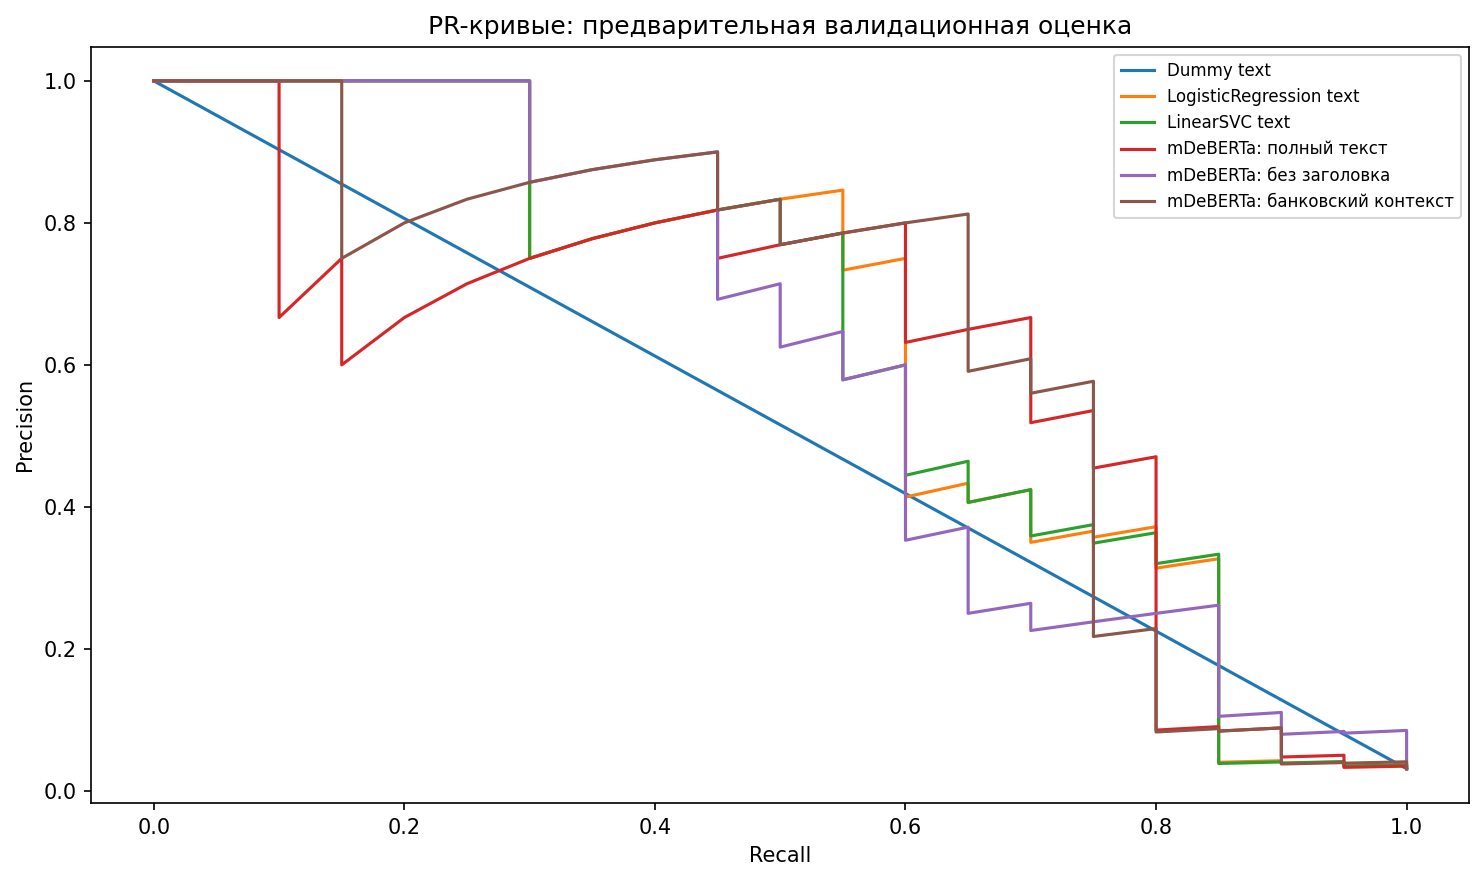

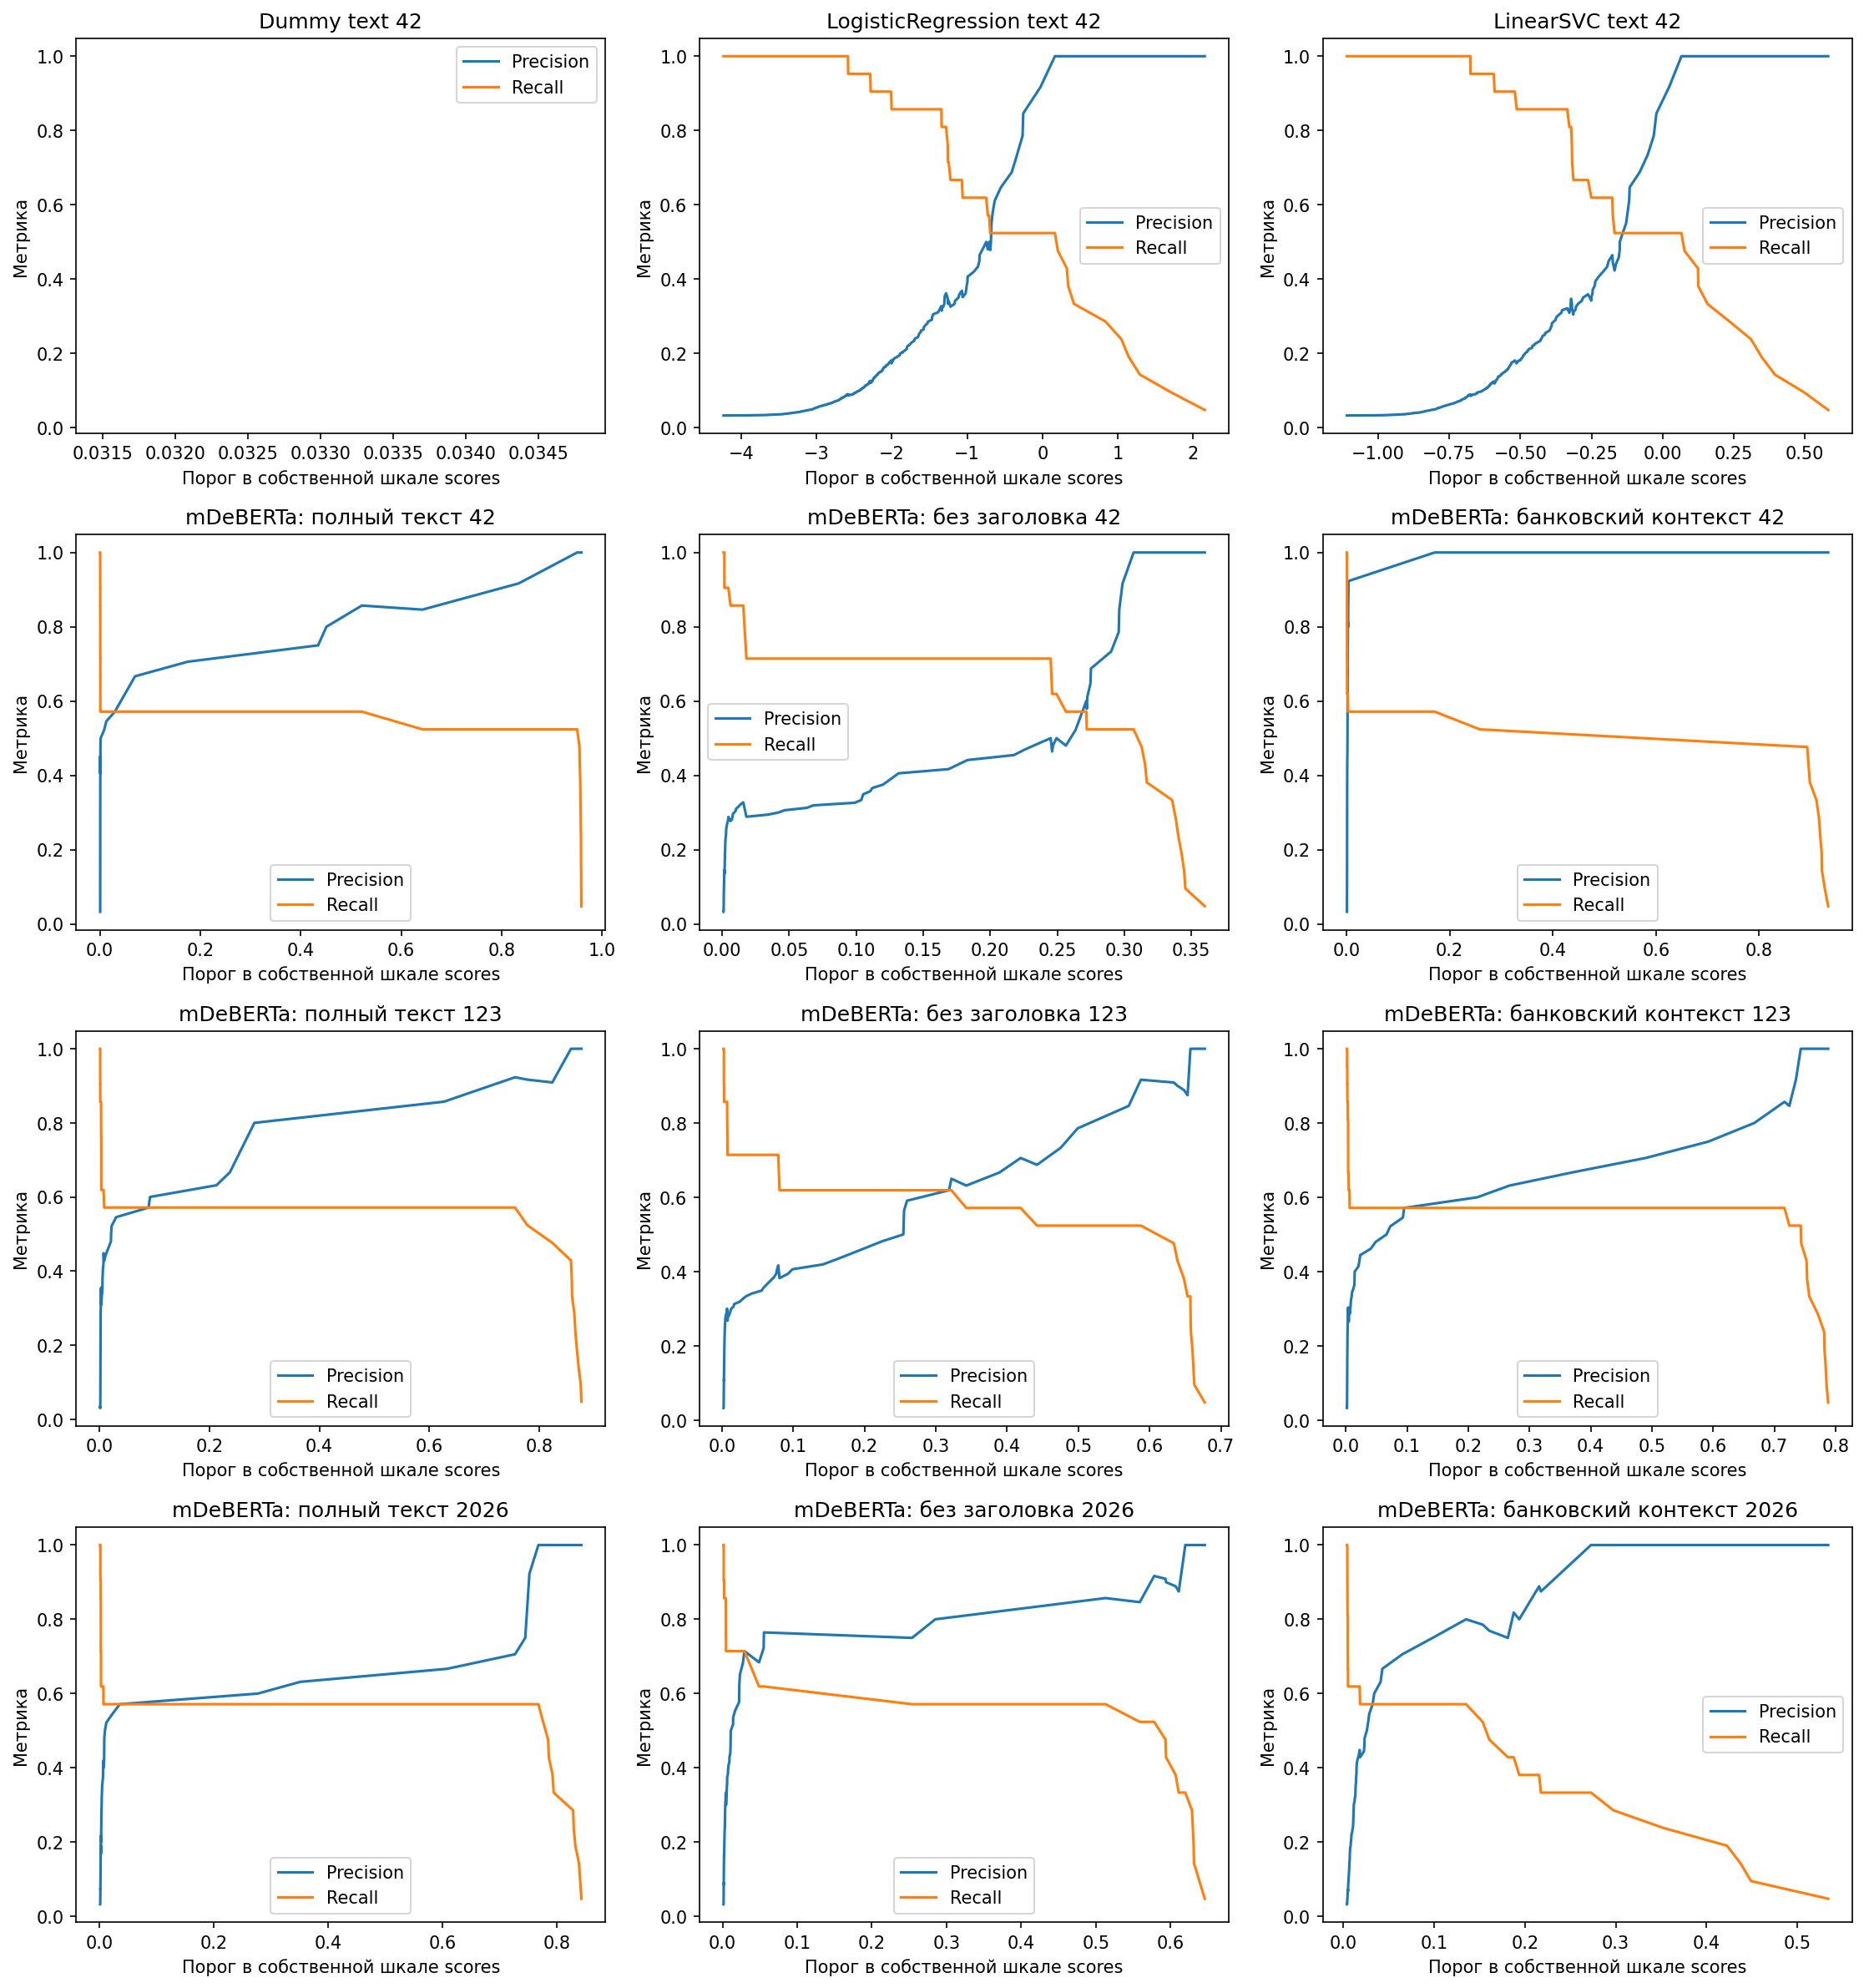

,name,scenario,status,target_precision,threshold,n,macro_f1,macro_f1_observed_classes,weighted_f1,tn,...,missed_risk_news,calibration_positive_groups,calibration_positives,generalization_guarantee,source_role,calibration_alert_groups,calibration_alerts,calibration_precision,calibration_recall,observed_target_met_on_valid
0,binary__Dummy__text__classical_grid__42,calibration_max_F1,FROZEN_ORIGINAL,NaN,0.033140,641.0,0.030257,0.030257,0.001888,0.0,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,binary__Dummy__text__classical_grid__42,target_precision_0.8,TARGET_NOT_ATTAINED_WITH_REQUIRED_SUPPORT,0.8,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,15.0,21.0,False,calibration,NaN,NaN,NaN,NaN,NaN
2,binary__Dummy__text__classical_grid__42,target_precision_0.9,TARGET_NOT_ATTAINED_WITH_REQUIRED_SUPPORT,0.9,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,15.0,21.0,False,calibration,NaN,NaN,NaN,NaN,NaN
3,binary__LogisticRegression__text__classical_gr...,calibration_max_F1,FROZEN_ORIGINAL,NaN,0.165242,641.0,0.735394,0.735394,0.972264,619.0,...,13.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,binary__LogisticRegression__text__classical_gr...,target_precision_0.8,CALIBRATION_FEASIBLE_NOT_VALID_GUARANTEED,0.8,0.165242,641.0,0.735394,0.735394,0.972264,619.0,...,13.0,15.0,21.0,False,calibration,10.0,11.0,1.000000,0.523810,False
5,binary__LogisticRegression__text__classical_gr...,target_precision_0.9,CALIBRATION_FEASIBLE_NOT_VALID_GUARANTEED,0.9,0.165242,641.0,0.735394,0.735394,0.972264,619.0,...,13.0,15.0,21.0,False,calibration,10.0,11.0,1.000000,0.523810,False
6,binary__LinearSVC__text__classical_grid__42,calibration_max_F1,FROZEN_ORIGINAL,NaN,0.066233,641.0,0.735394,0.735394,0.972264,619.0,...,13.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,binary__LinearSVC__text__classical_grid__42,target_precision_0.8,CALIBRATION_FEASIBLE_NOT_VALID_GUARANTEED,0.8,0.066233,641.0,0.735394,0.735394,0.972264,619.0,...,13.0,15.0,21.0,False,calibration,10.0,11.0,1.000000,0.523810,False
8,binary__LinearSVC__text__classical_grid__42,target_precision_0.9,CALIBRATION_FEASIBLE_NOT_VALID_GUARANTEED,0.9,0.066233,641.0,0.735394,0.735394,0.972264,619.0,...,13.0,15.0,21.0,False,calibration,10.0,11.0,1.000000,0.523810,False
9,binary__mDeBERTa__text__baseline__42,calibration_max_F1,FROZEN_ORIGINAL,NaN,0.950411,641.0,0.775650,0.775650,0.975499,618.0,...,11.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [40]:
plot_result('main_binary_pr_curves')
plot_result('calibration_precision_recall_vs_threshold')
table_result('operating_scenarios_valid',20)


### 9.2. Абляция заголовка, балансировка и устойчивость к seed


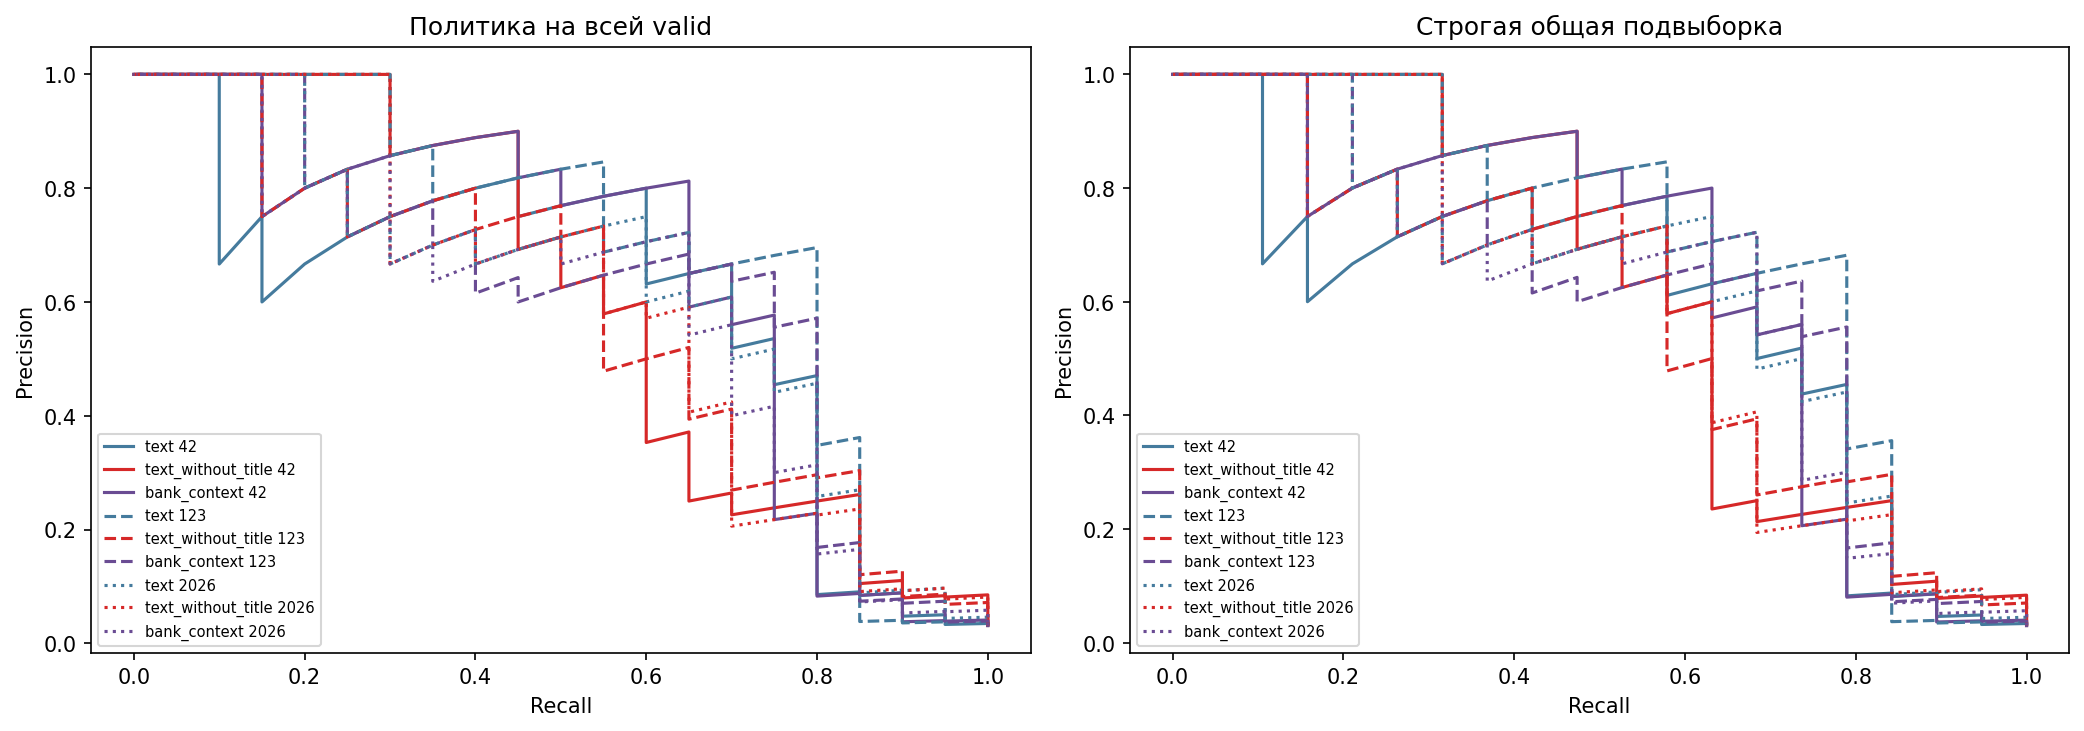

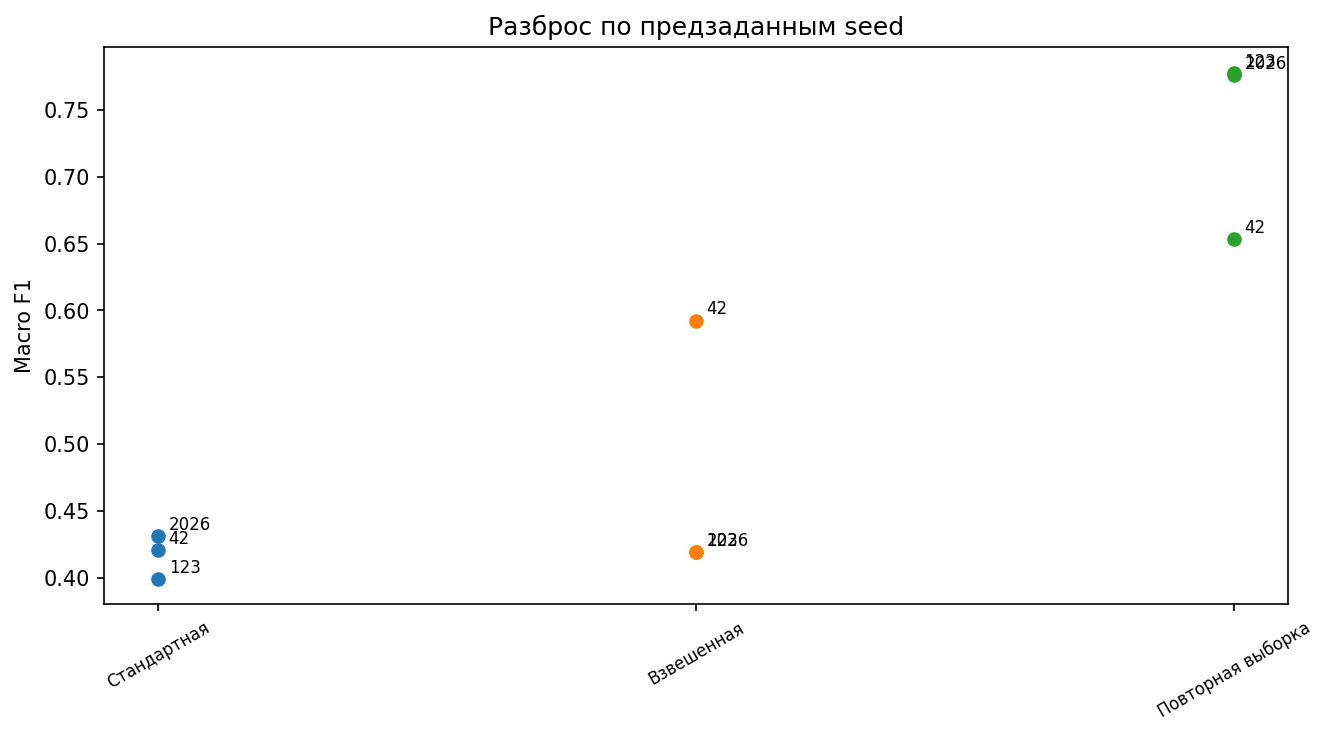

,mode,population,metric,seed_count,mean,std_ddof1,min,max
0,bank_context,full_valid_policy,precision,3,0.684127,0.094080,0.600000,0.785714
1,bank_context,full_valid_policy,recall,3,0.466667,0.076376,0.400000,0.550000
2,bank_context,full_valid_policy,f1,3,0.553782,0.081096,0.500000,0.647059
3,bank_context,full_valid_policy,ap,3,0.628254,0.025871,0.601278,0.652857
4,bank_context,strict_title_common_subset,precision,3,0.678632,0.085248,0.600000,0.769231
5,bank_context,strict_title_common_subset,recall,3,0.473684,0.052632,0.421053,0.526316
6,bank_context,strict_title_common_subset,f1,3,0.556847,0.059395,0.516129,0.625000
7,bank_context,strict_title_common_subset,ap,3,0.625375,0.016083,0.609494,0.641653
8,text,full_valid_policy,precision,3,0.701389,0.043368,0.666667,0.750000
9,text,full_valid_policy,recall,3,0.466667,0.076376,0.400000,0.550000


,name,baseline,seed,class,precision_delta,recall_delta,f1_delta,support,macro_f1_delta,interpretation
0,multiclass__mDeBERTa__text__weighted_loss__42,multiclass__mDeBERTa__text__baseline__42,42,no_risk,0.004661,-0.008052,-0.001675,621.0,0.171742,Наблюдаемые изменения категорий при одинаковой...
1,multiclass__mDeBERTa__text__weighted_loss__42,multiclass__mDeBERTa__text__baseline__42,42,cyber_risk,NaN,1.000000,0.666667,3.0,0.171742,Наблюдаемые изменения категорий при одинаковой...
2,multiclass__mDeBERTa__text__weighted_loss__42,multiclass__mDeBERTa__text__baseline__42,42,operational_risk,-0.017857,0.083333,0.021978,12.0,0.171742,Наблюдаемые изменения категорий при одинаковой...
3,multiclass__mDeBERTa__text__weighted_loss__42,multiclass__mDeBERTa__text__baseline__42,42,regulatory_risk,NaN,0.000000,0.000000,5.0,0.171742,Наблюдаемые изменения категорий при одинаковой...
4,multiclass__mDeBERTa__text__oversampling__42,multiclass__mDeBERTa__text__baseline__42,42,no_risk,0.006237,-0.011272,-0.002511,621.0,0.232881,Наблюдаемые изменения категорий при одинаковой...
5,multiclass__mDeBERTa__text__oversampling__42,multiclass__mDeBERTa__text__baseline__42,42,cyber_risk,NaN,0.666667,0.666667,3.0,0.232881,Наблюдаемые изменения категорий при одинаковой...
6,multiclass__mDeBERTa__text__oversampling__42,multiclass__mDeBERTa__text__baseline__42,42,operational_risk,-0.063910,0.166667,0.017370,12.0,0.232881,Наблюдаемые изменения категорий при одинаковой...
7,multiclass__mDeBERTa__text__oversampling__42,multiclass__mDeBERTa__text__baseline__42,42,regulatory_risk,NaN,0.200000,0.250000,5.0,0.232881,Наблюдаемые изменения категорий при одинаковой...
8,multiclass__mDeBERTa__text__weighted_loss__123,multiclass__mDeBERTa__text__baseline__123,123,no_risk,0.009386,-0.004831,0.002329,621.0,0.020283,Наблюдаемые изменения категорий при одинаковой...
9,multiclass__mDeBERTa__text__weighted_loss__123,multiclass__mDeBERTa__text__baseline__123,123,cyber_risk,NaN,0.000000,0.000000,3.0,0.020283,Наблюдаемые изменения категорий при одинаковой...


In [41]:
plot_result('ablation_pr_curves')
plot_result('multiclass_seed_stability')
table_result('ablation_seed_summary')
table_result('balancing_per_class_tradeoffs')


### 9.3. Устойчивость к искажениям текста и срезы по банкам, годам и источникам


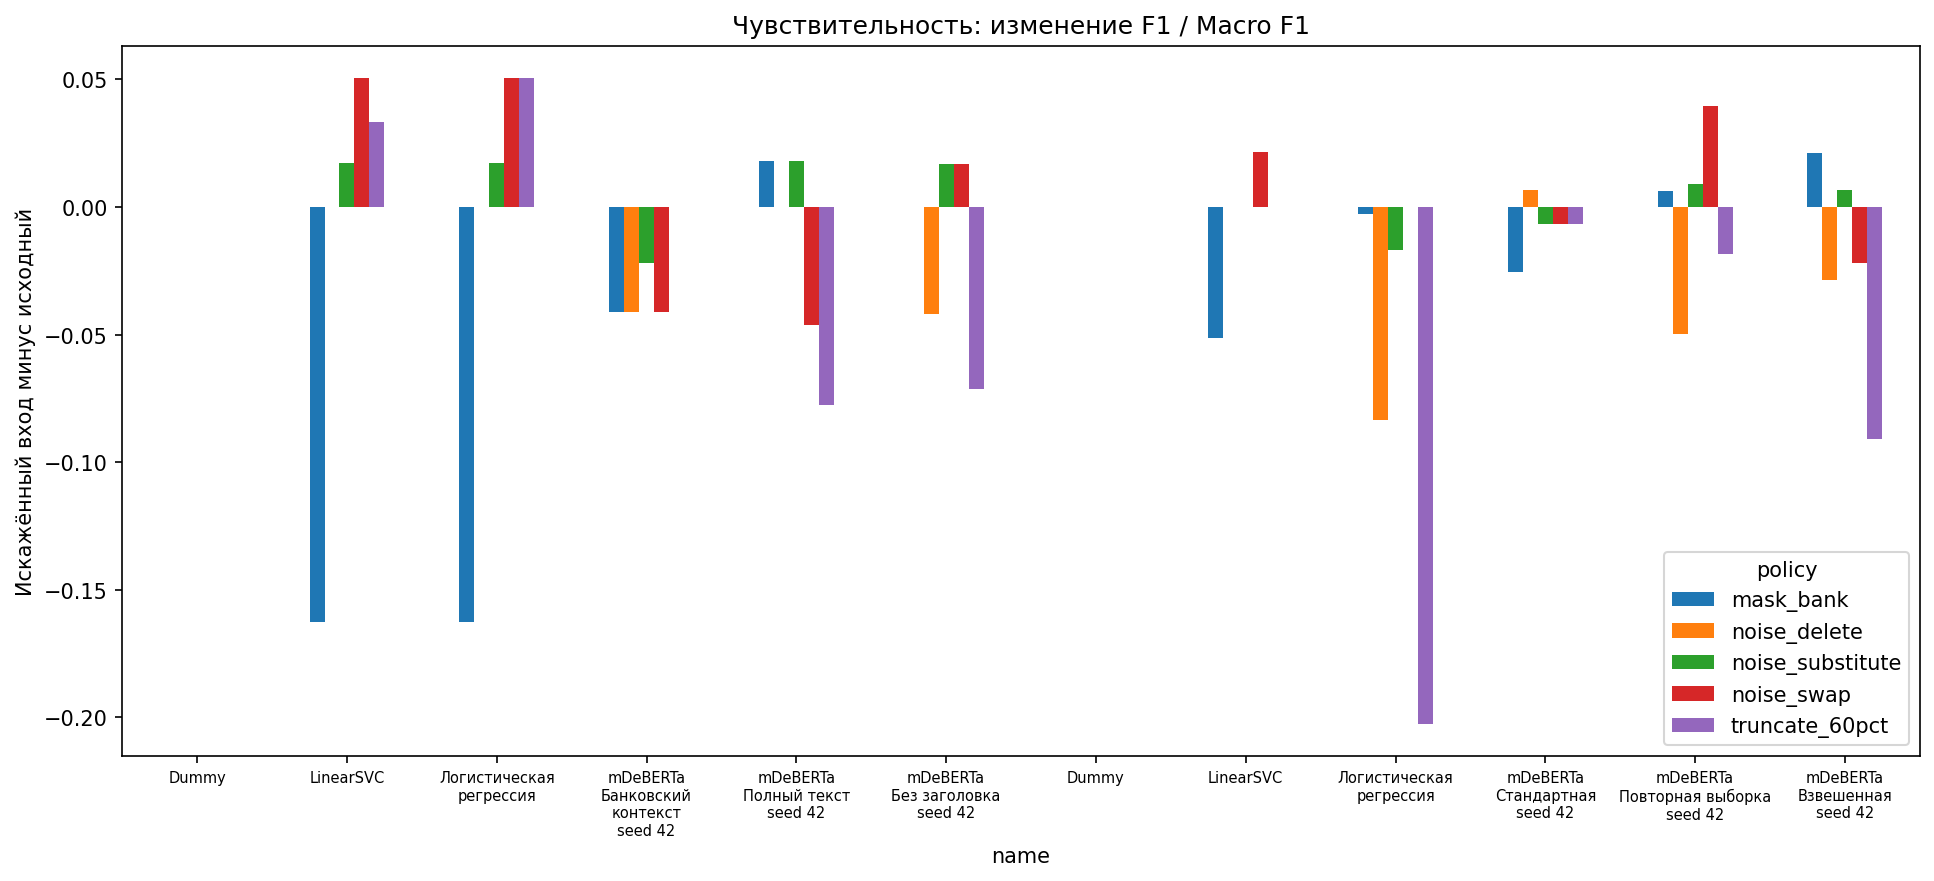

,policy,rows,changed_any_input,changed_text_or_title,unchanged_text_or_title,status_counts,bank_match_count
0,noise_substitute,641,625,625,16,"{'applied': 625, 'no_selected_characters': 16}",0
1,noise_delete,641,616,616,25,"{'applied': 616, 'no_selected_characters': 25}",0
2,noise_swap,641,609,609,32,"{'applied': 609, 'no_selected_characters': 32}",0
3,truncate_60pct,641,638,638,3,"{'applied': 638, 'not_applied_short_text': 3}",0
4,mask_bank,641,641,618,23,"{'applied': 618, 'bank_condition_masked_no_rel...",1196


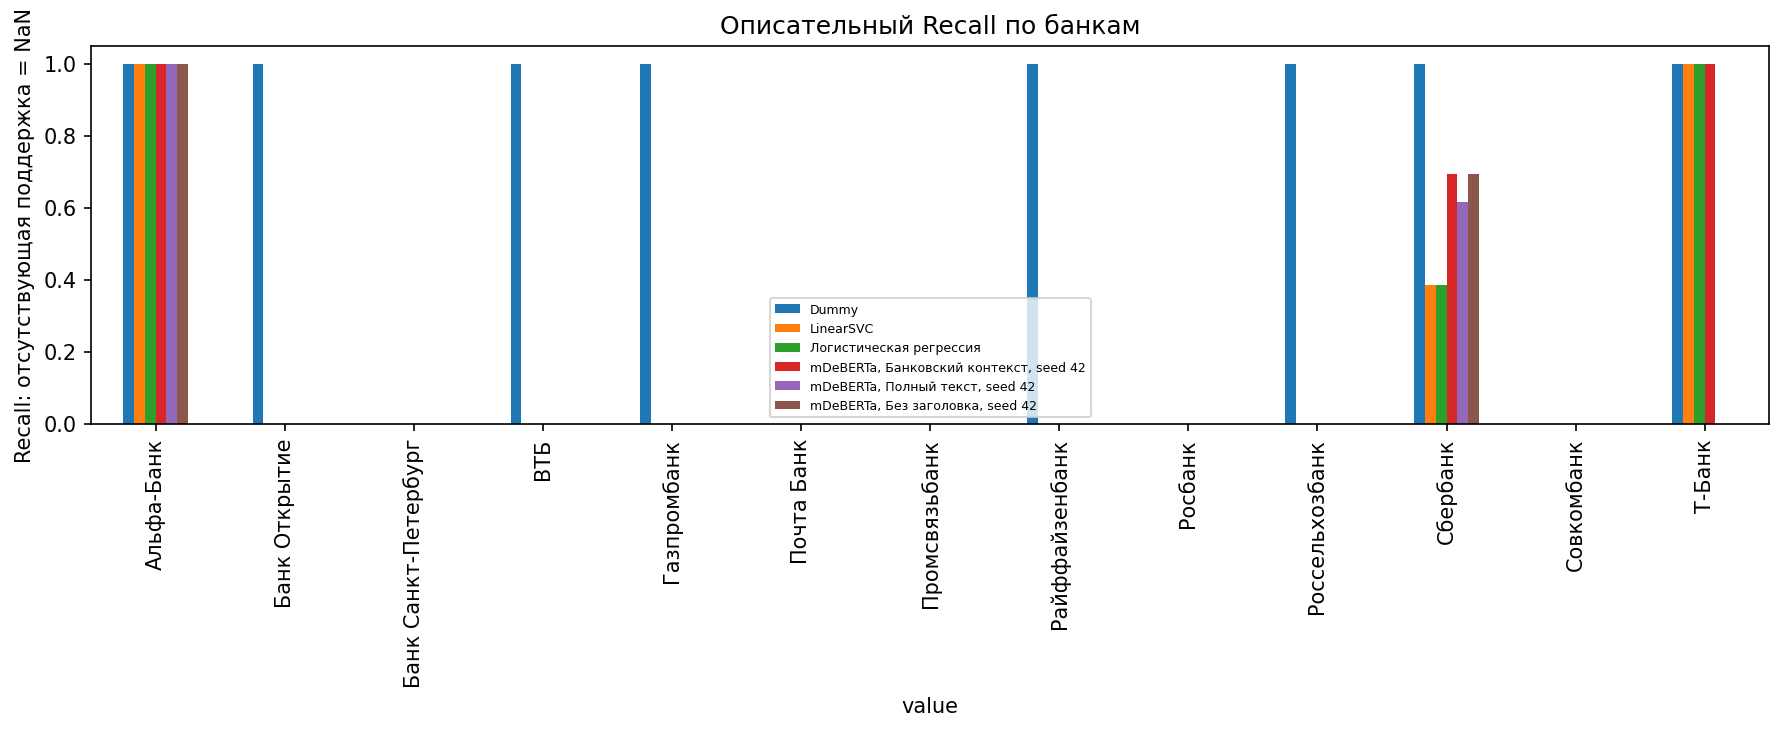

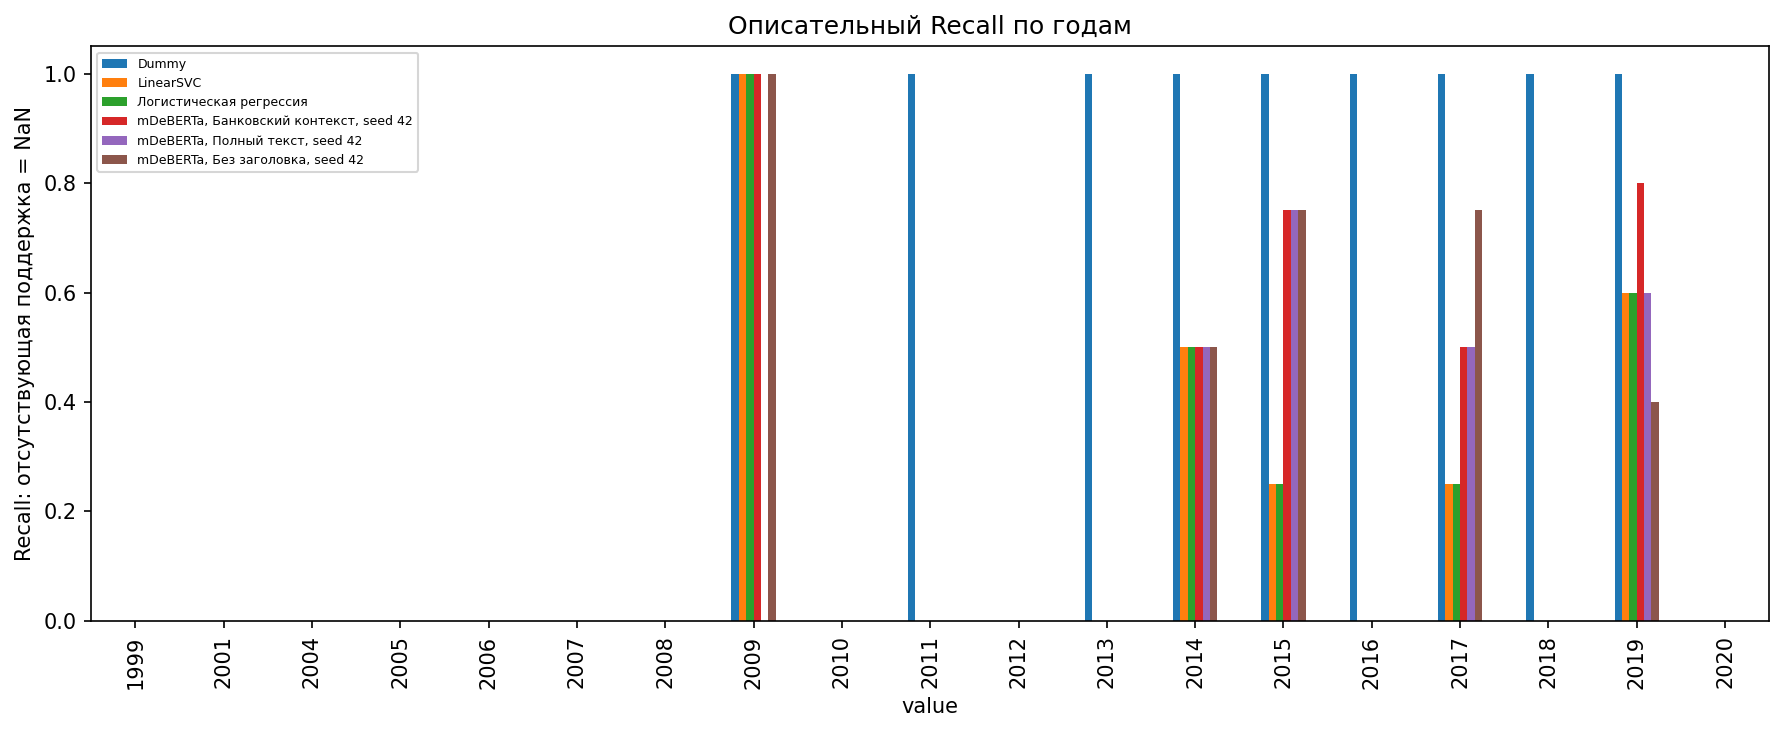

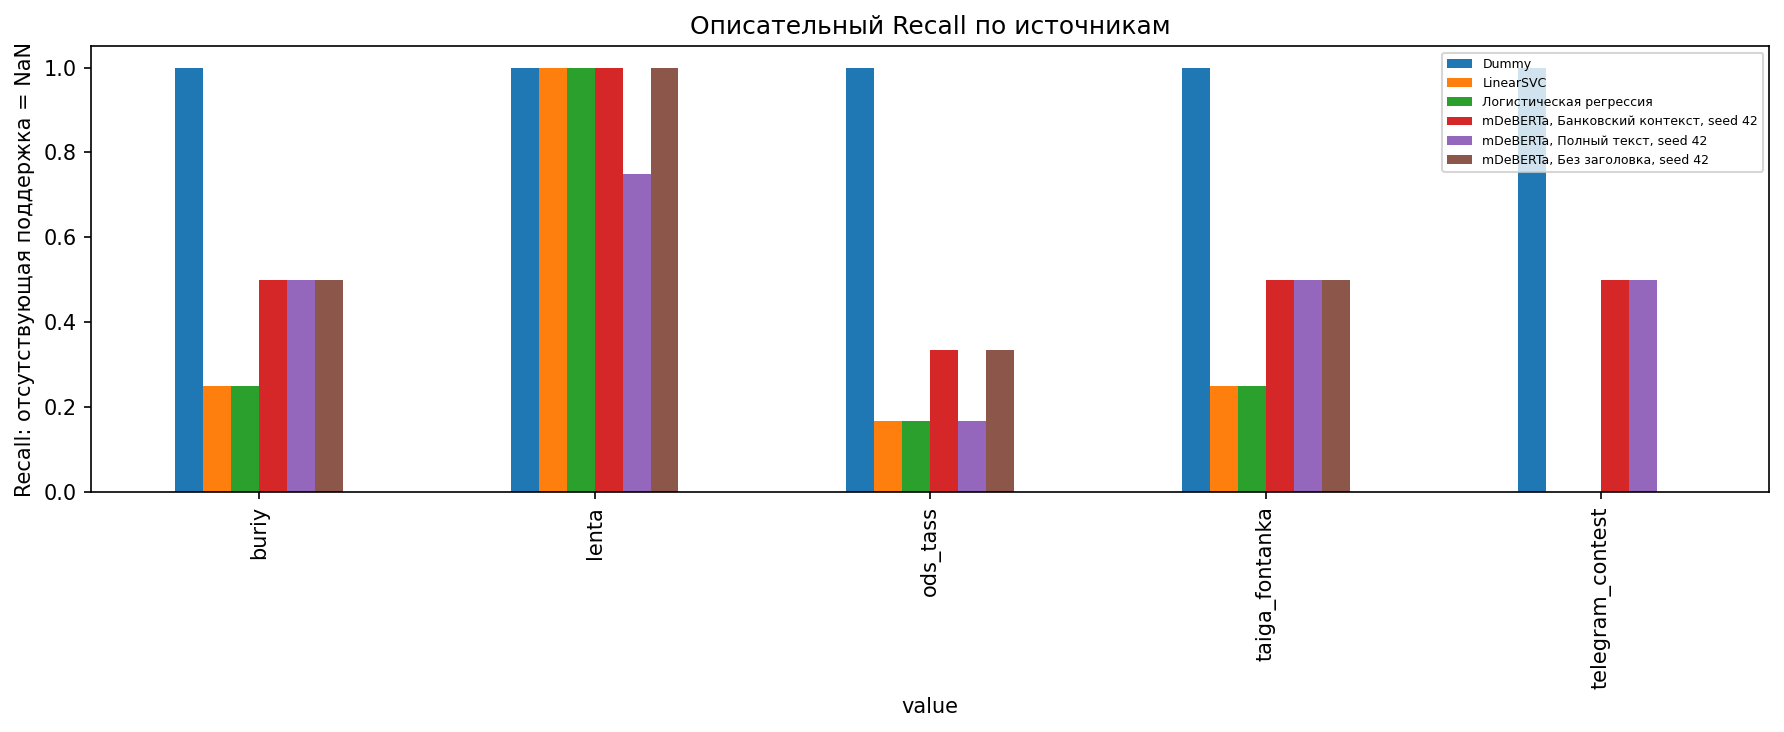

In [42]:
plot_result('robustness_sensitivity')
table_result('robustness_application_counts')
plot_result('slice_entity_norm')
plot_result('slice_published_year')
plot_result('slice_source')


### 9.4. Неопределённость и анализ ошибок


In [43]:
table_result('group_bootstrap_intervals')
table_result('paired_group_bootstrap_intervals')
table_result('errors')
table_result('regulatory_zero_f1_diagnostics')
table_result('computational_cost')


,metric,observed,ci_low,ci_high,valid_replicates,requested_replicates,groups,class_group_support,warning,interpretation,name
0,precision,0.031201,0.018603,0.044243,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__Dummy__text__classical_grid__42
1,recall,1.000000,1.000000,1.000000,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__Dummy__text__classical_grid__42
2,f1,0.060514,0.036527,0.084738,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__Dummy__text__classical_grid__42
3,ap,0.031201,0.018603,0.044243,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__Dummy__text__classical_grid__42
4,precision,0.777778,0.444048,1.000000,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LogisticRegression__text__classical_gr...
5,recall,0.350000,0.142619,0.571617,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LogisticRegression__text__classical_gr...
6,f1,0.482759,0.222222,0.695652,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LogisticRegression__text__classical_gr...
7,ap,0.643376,0.430694,0.843372,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LogisticRegression__text__classical_gr...
8,precision,0.777778,0.444048,1.000000,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LinearSVC__text__classical_grid__42
9,recall,0.350000,0.142619,0.571617,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LinearSVC__text__classical_grid__42


,metric,observed,ci_low,ci_high,valid_replicates,requested_replicates,groups,class_group_support,warning,interpretation,a,b,population,task,direction_interpretation
0,precision,0.000000,0.000000,0.000000,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LogisticRegression__text__classical_gr...,binary__LinearSVC__text__classical_grid__42,full_valid,binary,Интервал содержит ноль; направление различия н...
1,recall,0.000000,0.000000,0.000000,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LogisticRegression__text__classical_gr...,binary__LinearSVC__text__classical_grid__42,full_valid,binary,Интервал содержит ноль; направление различия н...
2,f1,0.000000,0.000000,0.000000,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LogisticRegression__text__classical_gr...,binary__LinearSVC__text__classical_grid__42,full_valid,binary,Интервал содержит ноль; направление различия н...
3,ap,0.008673,-0.005882,0.033604,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LogisticRegression__text__classical_gr...,binary__LinearSVC__text__classical_grid__42,full_valid,binary,Интервал содержит ноль; направление различия н...
4,precision,0.027778,-0.285794,0.305556,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LogisticRegression__text__classical_gr...,binary__mDeBERTa__text__baseline__42,full_valid,binary,Интервал содержит ноль; направление различия н...
5,recall,-0.100000,-0.347880,0.142857,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LogisticRegression__text__classical_gr...,binary__mDeBERTa__text__baseline__42,full_valid,binary,Интервал содержит ноль; направление различия н...
6,f1,-0.079741,-0.322664,0.173388,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LogisticRegression__text__classical_gr...,binary__mDeBERTa__text__baseline__42,full_valid,binary,Интервал содержит ноль; направление различия н...
7,ap,0.032435,-0.136395,0.191770,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LogisticRegression__text__classical_gr...,binary__mDeBERTa__text__baseline__42,full_valid,binary,Интервал содержит ноль; направление различия н...
8,precision,0.027778,-0.285794,0.305556,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LinearSVC__text__classical_grid__42,binary__mDeBERTa__text__baseline__42,full_valid,binary,Интервал содержит ноль; направление различия н...
9,recall,-0.100000,-0.347880,0.142857,1000,1000,628,"[{'class': 'no_risk', 'rows': 621, 'independen...",NaN,Описательный условный интервал без поправки на...,binary__LinearSVC__text__classical_grid__42,binary__mDeBERTa__text__baseline__42,full_valid,binary,Интервал содержит ноль; направление различия н...


,name,sample_id,entity_norm,true,predicted,error_type,excerpt,cause
0,binary__Dummy__text__classical_grid__42,ml_nat5_final_000008,Райффайзенбанк,no_risk,risk,FP,Финансовый регулятор приостановил выдачу инвес...,Причина не установлена; пример для анализа без...
1,binary__Dummy__text__classical_grid__42,ml_nat5_final_000010,Газпромбанк,no_risk,risk,FP,Порошенко ввел в действие решение СНБО о санкц...,Причина не установлена; пример для анализа без...
2,binary__Dummy__text__classical_grid__42,ml_nat5_final_000029,Промсвязьбанк,no_risk,risk,FP,Минфин захотел активнее брать в долг у россиян...,Причина не установлена; пример для анализа без...
3,binary__Dummy__text__classical_grid__42,ml_nat5_final_000031,ВТБ,no_risk,risk,FP,Из ВТБ уволился второй топ-менеджер за неделю ...,Причина не установлена; пример для анализа без...
4,binary__Dummy__text__classical_grid__42,ml_nat5_final_000039,Газпромбанк,no_risk,risk,FP,"Мнение: Кремль хватается за каждый клин, котор...",Причина не установлена; пример для анализа без...
5,binary__Dummy__text__classical_grid__42,ml_nat5_final_000053,Сбербанк,no_risk,risk,FP,Из-за технических работ карты Сбербанка могут ...,Причина не установлена; пример для анализа без...
6,binary__Dummy__text__classical_grid__42,ml_nat5_final_000060,ВТБ,no_risk,risk,FP,"Конфликт вокруг ""Уралкалия"". Хроника событий n...",Причина не установлена; пример для анализа без...
7,binary__Dummy__text__classical_grid__42,ml_nat5_final_000061,Банк Санкт-Петербург,no_risk,risk,FP,Лилия Агаркова о Неделе предпринимательства: в...,Причина не установлена; пример для анализа без...
8,binary__Dummy__text__classical_grid__42,ml_nat5_final_000068,ВТБ,no_risk,risk,FP,ВТБ забрал за долги нефтеперерабатывающий заво...,Причина не установлена; пример для анализа без...
9,binary__Dummy__text__classical_grid__42,ml_nat5_final_000069,Газпромбанк,no_risk,risk,FP,Посол ЕС в России - РБК: «Размахивание санкция...,Причина не установлена; пример для анализа без...


,task,family,mode,balance,seed,name,valid_regulatory_rows,valid_regulatory_groups,regulatory_predicted_rows,regulatory_true_positives,regulatory_false_positives,regulatory_false_negatives,class_weights_from_training_artifact,fit_regulatory_rows,diagnostic
0,multiclass,mDeBERTa,text,baseline,42,multiclass__mDeBERTa__text__baseline__42,5,5,0,0,0,5,NaN,7,no regulatory predictions; investigate fit sup...
1,multiclass,mDeBERTa,text,weighted_loss,42,multiclass__mDeBERTa__text__weighted_loss__42,5,5,0,0,0,5,"[0.2585690968443961, 29.703125, 11.88125, 67.8...",7,no regulatory predictions; investigate fit sup...
2,multiclass,mDeBERTa,text,oversampling,42,multiclass__mDeBERTa__text__oversampling__42,5,5,3,1,2,4,NaN,7,inspect errors and per-class tradeoffs; no aut...
3,multiclass,mDeBERTa,text,baseline,123,multiclass__mDeBERTa__text__baseline__123,5,5,0,0,0,5,NaN,7,no regulatory predictions; investigate fit sup...
4,multiclass,mDeBERTa,text,weighted_loss,123,multiclass__mDeBERTa__text__weighted_loss__123,5,5,0,0,0,5,"[0.2585690968443961, 29.703125, 11.88125, 67.8...",7,no regulatory predictions; investigate fit sup...
5,multiclass,mDeBERTa,text,oversampling,123,multiclass__mDeBERTa__text__oversampling__123,5,5,1,1,0,4,NaN,7,inspect errors and per-class tradeoffs; no aut...
6,multiclass,mDeBERTa,text,baseline,2026,multiclass__mDeBERTa__text__baseline__2026,5,5,0,0,0,5,NaN,7,no regulatory predictions; investigate fit sup...
7,multiclass,mDeBERTa,text,weighted_loss,2026,multiclass__mDeBERTa__text__weighted_loss__2026,5,5,0,0,0,5,"[0.2585690968443961, 29.703125, 11.88125, 67.8...",7,no regulatory predictions; investigate fit sup...
8,multiclass,mDeBERTa,text,oversampling,2026,multiclass__mDeBERTa__text__oversampling__2026,5,5,2,2,0,3,NaN,7,inspect errors and per-class tradeoffs; no aut...


,task,family,mode,balance,seed,name,training_seconds,hours,artifact_bytes,epochs_completed,best_checkpoint,time_scope
0,binary,Dummy,text,classical_grid,42,binary__Dummy__text__classical_grid__42,4.389550,0.001219,949695,NaN,model.joblib,Измеренное время обучения и кросс-валидации; д...
1,binary,LogisticRegression,text,classical_grid,42,binary__LogisticRegression__text__classical_gr...,25.696990,0.007138,1155344,NaN,model.joblib,Измеренное время обучения и кросс-валидации; д...
2,binary,LinearSVC,text,classical_grid,42,binary__LinearSVC__text__classical_grid__42,15.528520,0.004313,1156142,NaN,model.joblib,Измеренное время обучения и кросс-валидации; д...
3,multiclass,Dummy,text,classical_grid,42,multiclass__Dummy__text__classical_grid__42,4.400106,0.001222,1031037,NaN,model.joblib,Измеренное время обучения и кросс-валидации; д...
4,multiclass,LogisticRegression,text,classical_grid,42,multiclass__LogisticRegression__text__classica...,44.481425,0.012356,1658295,NaN,model.joblib,Измеренное время обучения и кросс-валидации; д...
5,multiclass,LinearSVC,text,classical_grid,42,multiclass__LinearSVC__text__classical_grid__42,15.973209,0.004437,1416787,NaN,model.joblib,Измеренное время обучения и кросс-валидации; д...
6,binary,mDeBERTa,text,baseline,42,binary__mDeBERTa__text__baseline__42,1933.080527,0.536967,1138529082,6.0,checkpoint-240,Измеренное время обучения и кросс-валидации; д...
7,binary,mDeBERTa,text_without_title,baseline,42,binary__mDeBERTa__text_without_title__baseline...,1209.737054,0.336038,1138532873,4.0,checkpoint-120,Измеренное время обучения и кросс-валидации; д...
8,binary,mDeBERTa,bank_context,baseline,42,binary__mDeBERTa__bank_context__baseline__42,1624.219495,0.451172,1138529563,6.0,checkpoint-240,Измеренное время обучения и кросс-валидации; д...
9,binary,mDeBERTa,text,baseline,123,binary__mDeBERTa__text__baseline__123,1614.192136,0.448387,1138530458,5.0,checkpoint-180,Измеренное время обучения и кросс-валидации; д...


## 10. Финальная независимая оценка на историческом test

После завершения всех 24 обучающих конфигураций, фиксации бинарного варианта входа, стратегии балансировки, основного seed и порогов историческая тестовая выборка открывается **один раз**. Test не используется для выбора конфигураций, порогов или повторного обучения моделей.


Зафиксированный binary mode: bank_context
Зафиксированная multiclass balancing: oversampling
Основной seed: 42

TEST открыт однократно.
Строк: 631
risk_type_4cls
no_risk             597
operational_risk     23
regulatory_risk       9
cyber_risk            2
Name: count, dtype: int64

Финальная test-оценка:
 - binary__Dummy__text__classical_grid__42
 - binary__LogisticRegression__text__classical_grid__42
 - binary__LinearSVC__text__classical_grid__42
 - multiclass__Dummy__text__classical_grid__42
 - multiclass__LogisticRegression__text__classical_grid__42
 - multiclass__LinearSVC__text__classical_grid__42
 - binary__mDeBERTa__bank_context__baseline__42
 - multiclass__mDeBERTa__text__oversampling__42

TEST: binary__Dummy__text__classical_grid__42

TEST: binary__LogisticRegression__text__classical_grid__42

TEST: binary__LinearSVC__text__classical_grid__42

TEST: multiclass__Dummy__text__classical_grid__42

TEST: multiclass__LogisticRegression__text__classical_grid__42

TEST: multiclass__


TEST: multiclass__mDeBERTa__text__oversampling__42


,name,task,family,mode,balance,seed,precision,recall,f1,ap,macro_f1,f1_no_risk,f1_cyber_risk,f1_operational_risk,f1_regulatory_risk
0,binary__Dummy__text__classical_grid__42,binary,Dummy,text,classical_grid,42,0.053883,1.000000,0.102256,0.053883,0.051128,0.000000,NaN,NaN,NaN
1,binary__LinearSVC__text__classical_grid__42,binary,LinearSVC,text,classical_grid,42,1.000000,0.441176,0.612245,0.719170,0.798291,0.984336,NaN,NaN,NaN
2,binary__LogisticRegression__text__classical_gr...,binary,LogisticRegression,text,classical_grid,42,1.000000,0.441176,0.612245,0.724881,0.798291,0.984336,NaN,NaN,NaN
3,binary__mDeBERTa__bank_context__baseline__42,binary,mDeBERTa,bank_context,baseline,42,1.000000,0.676471,0.807018,0.761123,0.898944,0.990871,NaN,NaN,NaN
4,multiclass__Dummy__text__classical_grid__42,multiclass,Dummy,text,classical_grid,42,NaN,NaN,NaN,NaN,0.243078,0.972313,0.0,0.000000,0.000000
5,multiclass__LinearSVC__text__classical_grid__42,multiclass,LinearSVC,text,classical_grid,42,NaN,NaN,NaN,NaN,0.385498,0.979491,0.0,0.562500,0.000000
6,multiclass__LogisticRegression__text__classica...,multiclass,LogisticRegression,text,classical_grid,42,NaN,NaN,NaN,NaN,0.568528,0.983416,0.5,0.790698,0.000000
7,multiclass__mDeBERTa__text__oversampling__42,multiclass,mDeBERTa,text,oversampling,42,NaN,NaN,NaN,NaN,0.677273,0.988314,0.5,0.857143,0.363636


,name,task,metric,observed,ci_2.5,ci_97.5,valid_replicates,independent_groups,warning
0,binary__Dummy__text__classical_grid__42,binary,ap,0.053883,0.035086,0.077053,1000,622,
1,binary__Dummy__text__classical_grid__42,binary,f1,0.102256,0.067794,0.143081,1000,622,
2,binary__LogisticRegression__text__classical_gr...,binary,ap,0.724881,0.546181,0.858259,1000,622,
3,binary__LogisticRegression__text__classical_gr...,binary,f1,0.612245,0.436324,0.756803,1000,622,
4,binary__LinearSVC__text__classical_grid__42,binary,ap,0.719170,0.541463,0.853546,1000,622,
5,binary__LinearSVC__text__classical_grid__42,binary,f1,0.612245,0.436324,0.756803,1000,622,
6,multiclass__Dummy__text__classical_grid__42,multiclass,macro_f1,0.243078,NaN,NaN,863,622,too few defined replicates: CI suppressed
7,multiclass__Dummy__text__classical_grid__42,multiclass,f1_cyber_risk,0.000000,NaN,NaN,863,622,too few defined replicates: CI suppressed
8,multiclass__Dummy__text__classical_grid__42,multiclass,f1_operational_risk,0.000000,0.000000,0.000000,1000,622,
9,multiclass__Dummy__text__classical_grid__42,multiclass,f1_regulatory_risk,0.000000,0.000000,0.000000,1000,622,


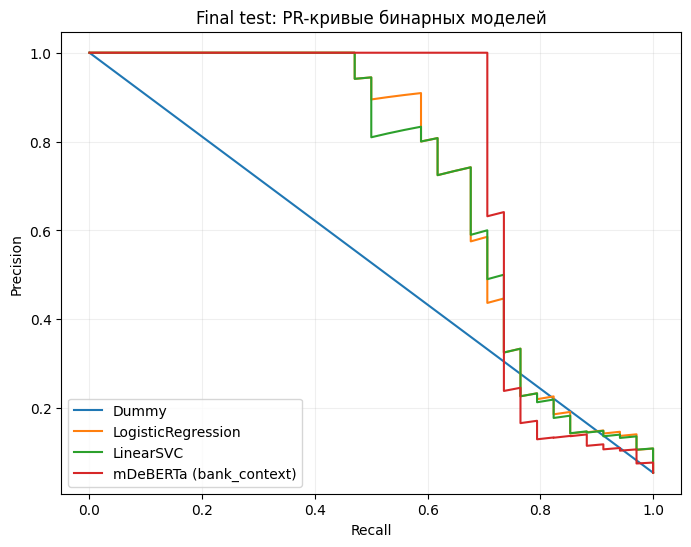

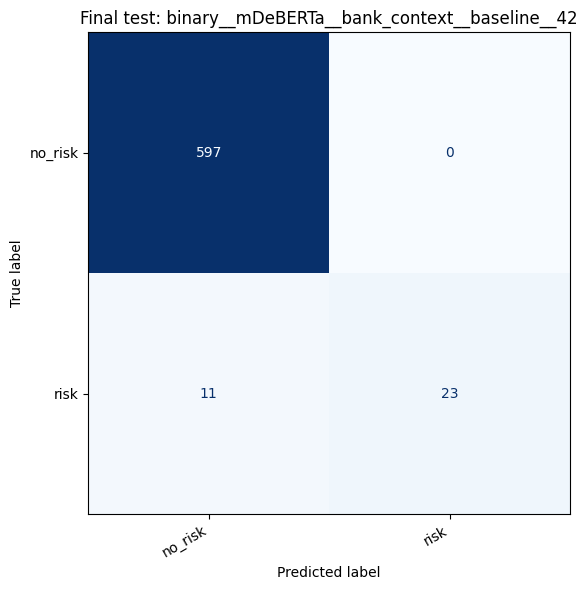

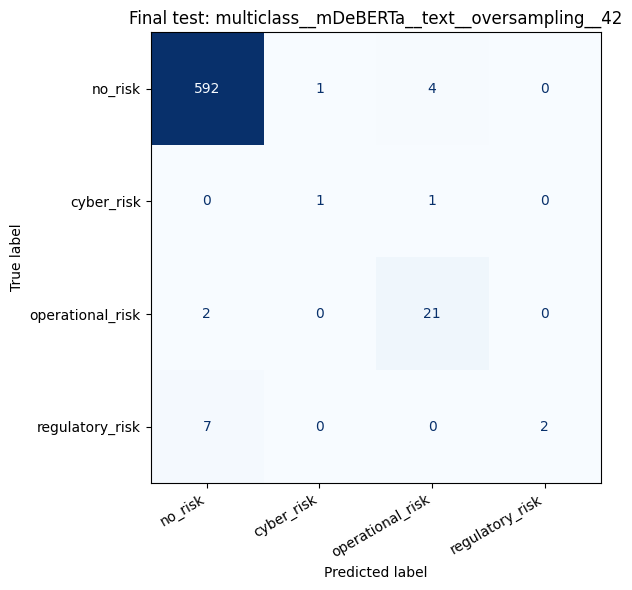


FINAL TEST COMPLETE
Никакие модели после открытия test не переобучались.
Test не использовался для выбора конфигураций.
Результаты сохранены в:
/kaggle/working/bank-risk-one-open-notebook-v1-6e7286445cd5/final_test


In [49]:
# ============================================================
# FINAL ONE-SHOT TEST EVALUATION
# Никакого переобучения и никакого выбора модели по test.
# ============================================================

from pathlib import Path
import json
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    ConfusionMatrixDisplay
)

assert EXPERIMENT is not None
assert len(EXPERIMENT.completed()) == len(EXPERIMENT.plan), "Не все 24 обучения завершены"

# --- 1. Читаем уже зафиксированный план ---
engine_freeze, research_freeze = EXPERIMENT.freezes()
freeze = read_json(engine_freeze)

print("Зафиксированный binary mode:", freeze["selected_binary_mode_train_only"])
print("Зафиксированная multiclass balancing:", freeze["selected_multiclass_balancing_train_only"])
print("Основной seed:", freeze["main_seed"])

# --- 2. Открываем исторический test ОДИН РАЗ ---
# Не используем DATA.load('test'), поскольку он намеренно был заблокирован
# до завершения всех решений по модели.
test_rows = []

for row in DATA.bundle.rows("bank_risk_news.csv"):
    meta = DATA.index[row["sample_id"]]
    if meta["split"] == "test":
        test_rows.append({
            **row,
            "split": "test",
            "role": "",
            "leakage_group_id": meta["leakage_group_id"]
        })

test = pd.DataFrame(test_rows).reset_index(drop=True)

assert len(test) == 631, f"Ожидалось 631 строк test, найдено {len(test)}"
print("\nTEST открыт однократно.")
print("Строк:", len(test))
print(test["risk_type_4cls"].value_counts())

# --- 3. Финальный набор моделей ---
# Классические baseline — все 3 для обеих задач.
# mDeBERTa — только заранее выбранные train-only конфигурации,
# основной seed=42. Test НЕ используется для выбора конфигурации.

selected = []

for run, folder, meta in EXPERIMENT.completed():

    if run["family"] != "mDeBERTa":
        selected.append((run, folder, meta))
        continue

    if run["seed"] != freeze["main_seed"]:
        continue

    if (
        run["task"] == "binary"
        and run["mode"] == freeze["selected_binary_mode_train_only"]
    ):
        selected.append((run, folder, meta))

    if (
        run["task"] == "multiclass"
        and run["balance"] == freeze["selected_multiclass_balancing_train_only"]
    ):
        selected.append((run, folder, meta))

print("\nФинальная test-оценка:")
for run, _, _ in selected:
    print(" -", run["name"])

# --- 4. Инференс ---
out_dir = Path(EXPERIMENT.store.root) / "final_test"
out_dir.mkdir(parents=True, exist_ok=True)

all_metrics = []
all_predictions = {}

for run, folder, meta in selected:

    print("\nTEST:", run["name"])

    # Порог binary уже зафиксирован на calibration.
    threshold = meta["threshold"]

    with Predictor(run, folder) as predictor:
        scores = predictor.scores(test)

    pred = score_frame(
        test,
        run["task"],
        scores,
        threshold=threshold
    )

    result = metrics(
        pred.y_true,
        pred.y_pred,
        run["task"],
        pred.score if run["task"] == "binary" else None
    )

    all_predictions[run["name"]] = pred

    row = {
        "name": run["name"],
        "task": run["task"],
        "family": run["family"],
        "mode": run["mode"],
        "balance": run["balance"],
        "seed": run["seed"],
        **flatten_result(result)
    }
    all_metrics.append(row)

    save_csv(out_dir / f"{run['name']}__predictions.csv", pred)
    save_json(out_dir / f"{run['name']}__metrics.json", result)

    del scores
    gc.collect()

# --- 5. Итоговая таблица ---
test_metrics = pd.DataFrame(all_metrics)

columns = [
    c for c in [
        "name", "task", "family", "mode", "balance", "seed",
        "precision", "recall", "f1", "ap",
        "macro_f1",
        "f1_no_risk",
        "f1_cyber_risk",
        "f1_operational_risk",
        "f1_regulatory_risk"
    ]
    if c in test_metrics.columns
]

display(
    test_metrics[columns]
    .sort_values(["task", "family", "name"])
    .reset_index(drop=True)
)

save_csv(out_dir / "FINAL_TEST_METRICS.csv", test_metrics)

# --- 6. Group-bootstrap 95% CI ---
ci_tables = []

for run, _, _ in selected:
    pred = all_predictions[run["name"]]

    ci = group_bootstrap(
        pred,
        run["task"],
        repeats=1000,
        seed=20261122
    )

    ci["name"] = run["name"]
    ci["task"] = run["task"]
    ci_tables.append(ci)

test_ci = pd.concat(ci_tables, ignore_index=True)
save_csv(out_dir / "FINAL_TEST_GROUP_BOOTSTRAP_CI.csv", test_ci)

display(
    test_ci[
        ["name", "task", "metric", "observed",
         "ci_2.5", "ci_97.5", "valid_replicates",
         "independent_groups", "warning"]
    ]
)

# --- 7. PR-кривые binary ---
fig, ax = plt.subplots(figsize=(8, 6))

for run, _, _ in selected:
    if run["task"] != "binary":
        continue

    pred = all_predictions[run["name"]]
    precision, recall, _ = precision_recall_curve(
        pred.y_true,
        pred.score
    )

    ax.plot(
        recall,
        precision,
        label=run["family"] if run["family"] != "mDeBERTa"
        else f"mDeBERTa ({run['mode']})"
    )

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Final test: PR-кривые бинарных моделей")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

# --- 8. Confusion matrices финальных mDeBERTa ---
for run, _, _ in selected:

    if run["family"] != "mDeBERTa":
        continue

    pred = all_predictions[run["name"]]

    labels = (
        ["no_risk", "risk"]
        if run["task"] == "binary"
        else LABELS
    )

    fig, ax = plt.subplots(figsize=(7, 6))

    ConfusionMatrixDisplay.from_predictions(
        pred.y_true,
        pred.y_pred,
        display_labels=labels,
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title("Final test: " + run["name"])
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# --- 9. Фиксируем факт единственного открытия test ---
test_record = {
    "status": "FINAL_TEST_COMPLETE",
    "test_rows": len(test),
    "models_evaluated": [r["name"] for r, _, _ in selected],
    "binary_mode_frozen_before_test":
        freeze["selected_binary_mode_train_only"],
    "multiclass_balance_frozen_before_test":
        freeze["selected_multiclass_balancing_train_only"],
    "main_seed_frozen_before_test":
        freeze["main_seed"],
    "thresholds_unchanged": True,
    "models_retrained_after_test": False,
    "test_used_for_selection": False
}

save_json(out_dir / "FINAL_TEST_PROTOCOL.json", test_record)

print("\n==========================================")
print("FINAL TEST COMPLETE")
print("Никакие модели после открытия test не переобучались.")
print("Test не использовался для выбора конфигураций.")
print("Результаты сохранены в:")
print(out_dir)
print("==========================================")


# 11. Итоговые результаты и выводы

## 11.1. Что было проверено

Исследование выполнено на зафиксированной версии корпуса из **4 473 публикаций**. Экспериментальный план включает **24 конфигурации**: классические baseline, бинарные варианты mDeBERTa с абляцией представления текста и многоклассовые варианты mDeBERTa с различными стратегиями балансировки и тремя случайными инициализациями.

Для снижения риска утечки данных train разделён на `fit`, `stop` и `calibration`. Выбор контрольной точки выполняется без использования valid, бинарный порог фиксируется на calibration. После фиксации решений проводится внешняя оценка на valid, а исторический test открывается один раз в самом конце.

В Notebook также представлены:
- DummyClassifier, Logistic Regression и LinearSVC;
- PR-кривые, Precision, Recall, F1 и Average Precision для бинарной задачи;
- Macro-F1 и поклассовые F1 для многоклассовой задачи;
- групповой bootstrap и доверительные интервалы;
- анализ FP/FN и диагностических ошибок;
- абляция заголовка и банковского контекста;
- устойчивость к seed;
- сравнение baseline / weighted loss / oversampling;
- проверки робастности к опечаткам, удалению и перестановке символов, обрезке текста и маскированию банка;
- срезы по банкам, годам и источникам.

## 11.2. Финальная бинарная задача: наличие риска

Исторический test содержит **631 публикацию**, из них **34 публикации с риском** и 597 без выявленного риска.

Финальная mDeBERTa с заранее выбранным представлением `bank_context` и seed 42 получила:

| Модель | Precision | Recall | F1 | Average Precision |
|---|---:|---:|---:|---:|
| Logistic Regression | 1.000 | 0.441 | 0.612 | 0.725 |
| LinearSVC | 1.000 | 0.441 | 0.612 | 0.719 |
| **mDeBERTa** | **1.000** | **0.676** | **0.807** | **0.761** |

Таким образом, на независимом test mDeBERTa обнаруживает большую долю рисковых публикаций при отсутствии ложноположительных решений в выбранной рабочей точке. Для F1 mDeBERTa групповой bootstrap дал 95% интервал примерно **0.652–0.914**, для AP — **0.584–0.895**. Интервалы остаются широкими, поэтому различия следует интерпретировать с учётом малого числа положительных наблюдений.

## 11.3. Финальная многоклассовая задача

В test представлены 597 публикаций `no_risk`, 23 `operational_risk`, 9 `regulatory_risk` и только 2 `cyber_risk`. Поэтому поклассовые показатели редких категорий статистически неустойчивы.

Финальная mDeBERTa использует **oversampling**, выбранный до открытия test. Получены следующие результаты:

| Модель | Macro-F1 | Cyber F1 | Operational F1 | Regulatory F1 |
|---|---:|---:|---:|---:|
| Dummy | 0.243 | 0.000 | 0.000 | 0.000 |
| LinearSVC | 0.385 | 0.000 | 0.563 | 0.000 |
| Logistic Regression | 0.569 | 0.500 | 0.791 | 0.000 |
| **mDeBERTa + oversampling** | **0.677** | **0.500** | **0.857** | **0.364** |

Ключевой результат состоит в том, что для регуляторного риска F1 **перестаёт быть нулевым** у финальной mDeBERTa с oversampling. Для operational risk F1 достигает **0.857**. При этом вывод по cyber risk принципиально ограничен двумя примерами этого класса в test.

Для regulatory risk групповой bootstrap даёт широкий 95% интервал **0.000–0.727**, что прямо показывает высокую неопределённость оценки редкого класса.

## 11.4. Балансировка и устойчивость

Эксперименты с тремя seed показали, что многоклассовая mDeBERTa чувствительна к случайной инициализации. Weighted loss не устранил проблему редкого регуляторного класса. Наиболее полезной стратегией оказался **oversampling**: именно он позволил получать ненулевой F1 для regulatory risk на valid и подтвердил преимущество выбранной конфигурации на test.

Следовательно, нестабильность нельзя считать полностью устранённой, но она **измерена**, а влияние стратегии балансировки проверено экспериментально.

## 11.5. Надёжность выводов и ограничения

Основное ограничение исследования — сильный дисбаланс классов. Один отдельный объект способен существенно изменить показатели редких категорий. Поэтому точечные значения F1 не рассматриваются как доказательство универсального превосходства модели.

Особенно осторожно интерпретируются:
- `cyber_risk`: всего 2 объекта в test;
- `regulatory_risk`: 9 объектов в test;
- различия между близкими конфигурациями на valid;
- срезы по редким банкам, годам и источникам.

Корпус используется в зафиксированном виде до начала финального цикла оценки. В Notebook дополнительно контролируются целостность разбиений, событийные группы, дубликаты и согласованность экспериментального протокола. Возможная остаточная неоднозначность отдельных новостных формулировок рассматривается как ограничение задачи классификации естественного языка и учитывается при интерпретации ошибок.

## 11.6. Итог

На данном корпусе **полное дообучение mDeBERTa** показало лучший итоговый результат среди рассмотренных методов как в бинарной, так и в многоклассовой постановке.

Для бинарного обнаружения риска финальная модель достигла **F1 = 0.807** и **AP = 0.761** на независимом историческом test.

Для четырёхклассовой классификации mDeBERTa с oversampling достигла **Macro-F1 = 0.677** и, в отличие от классических моделей, получила ненулевой **F1 = 0.364** для регуляторного риска.

При этом результаты редких классов сопровождаются высокой статистической неопределённостью. Поэтому основной практический вывод заключается не только в преимуществе трансформерной модели, но и в необходимости совместно учитывать **качество корпуса, дисбаланс классов, калибровку, устойчивость к seed, робастность и статистическую неопределённость**.

В совокупности проведённые эксперименты показывают, что mDeBERTa является наиболее перспективным из рассмотренных подходов для автоматизированного мониторинга банковских рисков по новостным публикациям при условии осторожной интерпретации редких категорий.


### Статус исследования

- Обучающие конфигурации: **24/24 завершены**.
- Финальный бинарный вариант: **mDeBERTa, bank_context, seed 42**.
- Финальная многоклассовая стратегия: **mDeBERTa, oversampling, seed 42**.
- Исторический test: **открыт однократно после фиксации решений**.
- Повторного обучения после открытия test: **нет**.
- Test для выбора конфигураций или порогов: **не использовался**.
